In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q scikit-fuzzy openpyxl pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 13.9 MB/s eta 0:00:00


In [3]:
import os
for path in [
    "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/clinical_data_detailed.xlsx",
    "/content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/VisionMamba_Results/Evaluation/WTP/WTP_per_case.csv",
]:
    print(f"{'✓' if os.path.exists(path) else '✗'} {path}")

✓ /content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/clinical_data_detailed.xlsx
✓ /content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/VisionMamba_Results/Evaluation/WTP/WTP_per_case.csv


Final Code.. Remaining Available below

PIPELINE 2 — Q1 JOURNAL IMPLEMENTATION

[STAGE 8] Data Loading
  WTP: (348, 14)
  Using synthetic matched clinical file
  Merged: 348
  After cleaning: 348 patients

[STAGE 9] Clinical Context (balanced)
  Context distribution:
clinical_context
HR    163
MR    114
LR     71

[STAGE 10] MF Calibration

[STAGE 12] Threshold calibration ...
  Adaptive thresholds: (32.04, 50.80, 64.05)

[STAGE 13] Cumulative Rule Ablation
  4-Rule (Core)         Mean CI=46.59  Std CI=27.90  Fallback=119
  8-Rule                Mean CI=50.00  Std CI=27.52  Fallback=21
  12-Rule               Mean CI=47.70  Std CI=22.52  Fallback=4
  15-Rule (Full)        Mean CI=48.59  Std CI=19.34  Fallback=4

[TABLE 5] Summary by Chronicity Risk Category

TABLE 5 — Summary by Chronicity Risk Category (n = 348)
Risk Category  N N (%)      Mean CI      Mean HS Mean R_nec (%) Mean R_slough (%) Mean R_gran (%)    Mean Age HR context %
          Low 87 25.0% 22.41 ± 6.38 75.37 ± 5.64    3.08 ± 4.33     20.29 ± 11.89   60.05 ± 

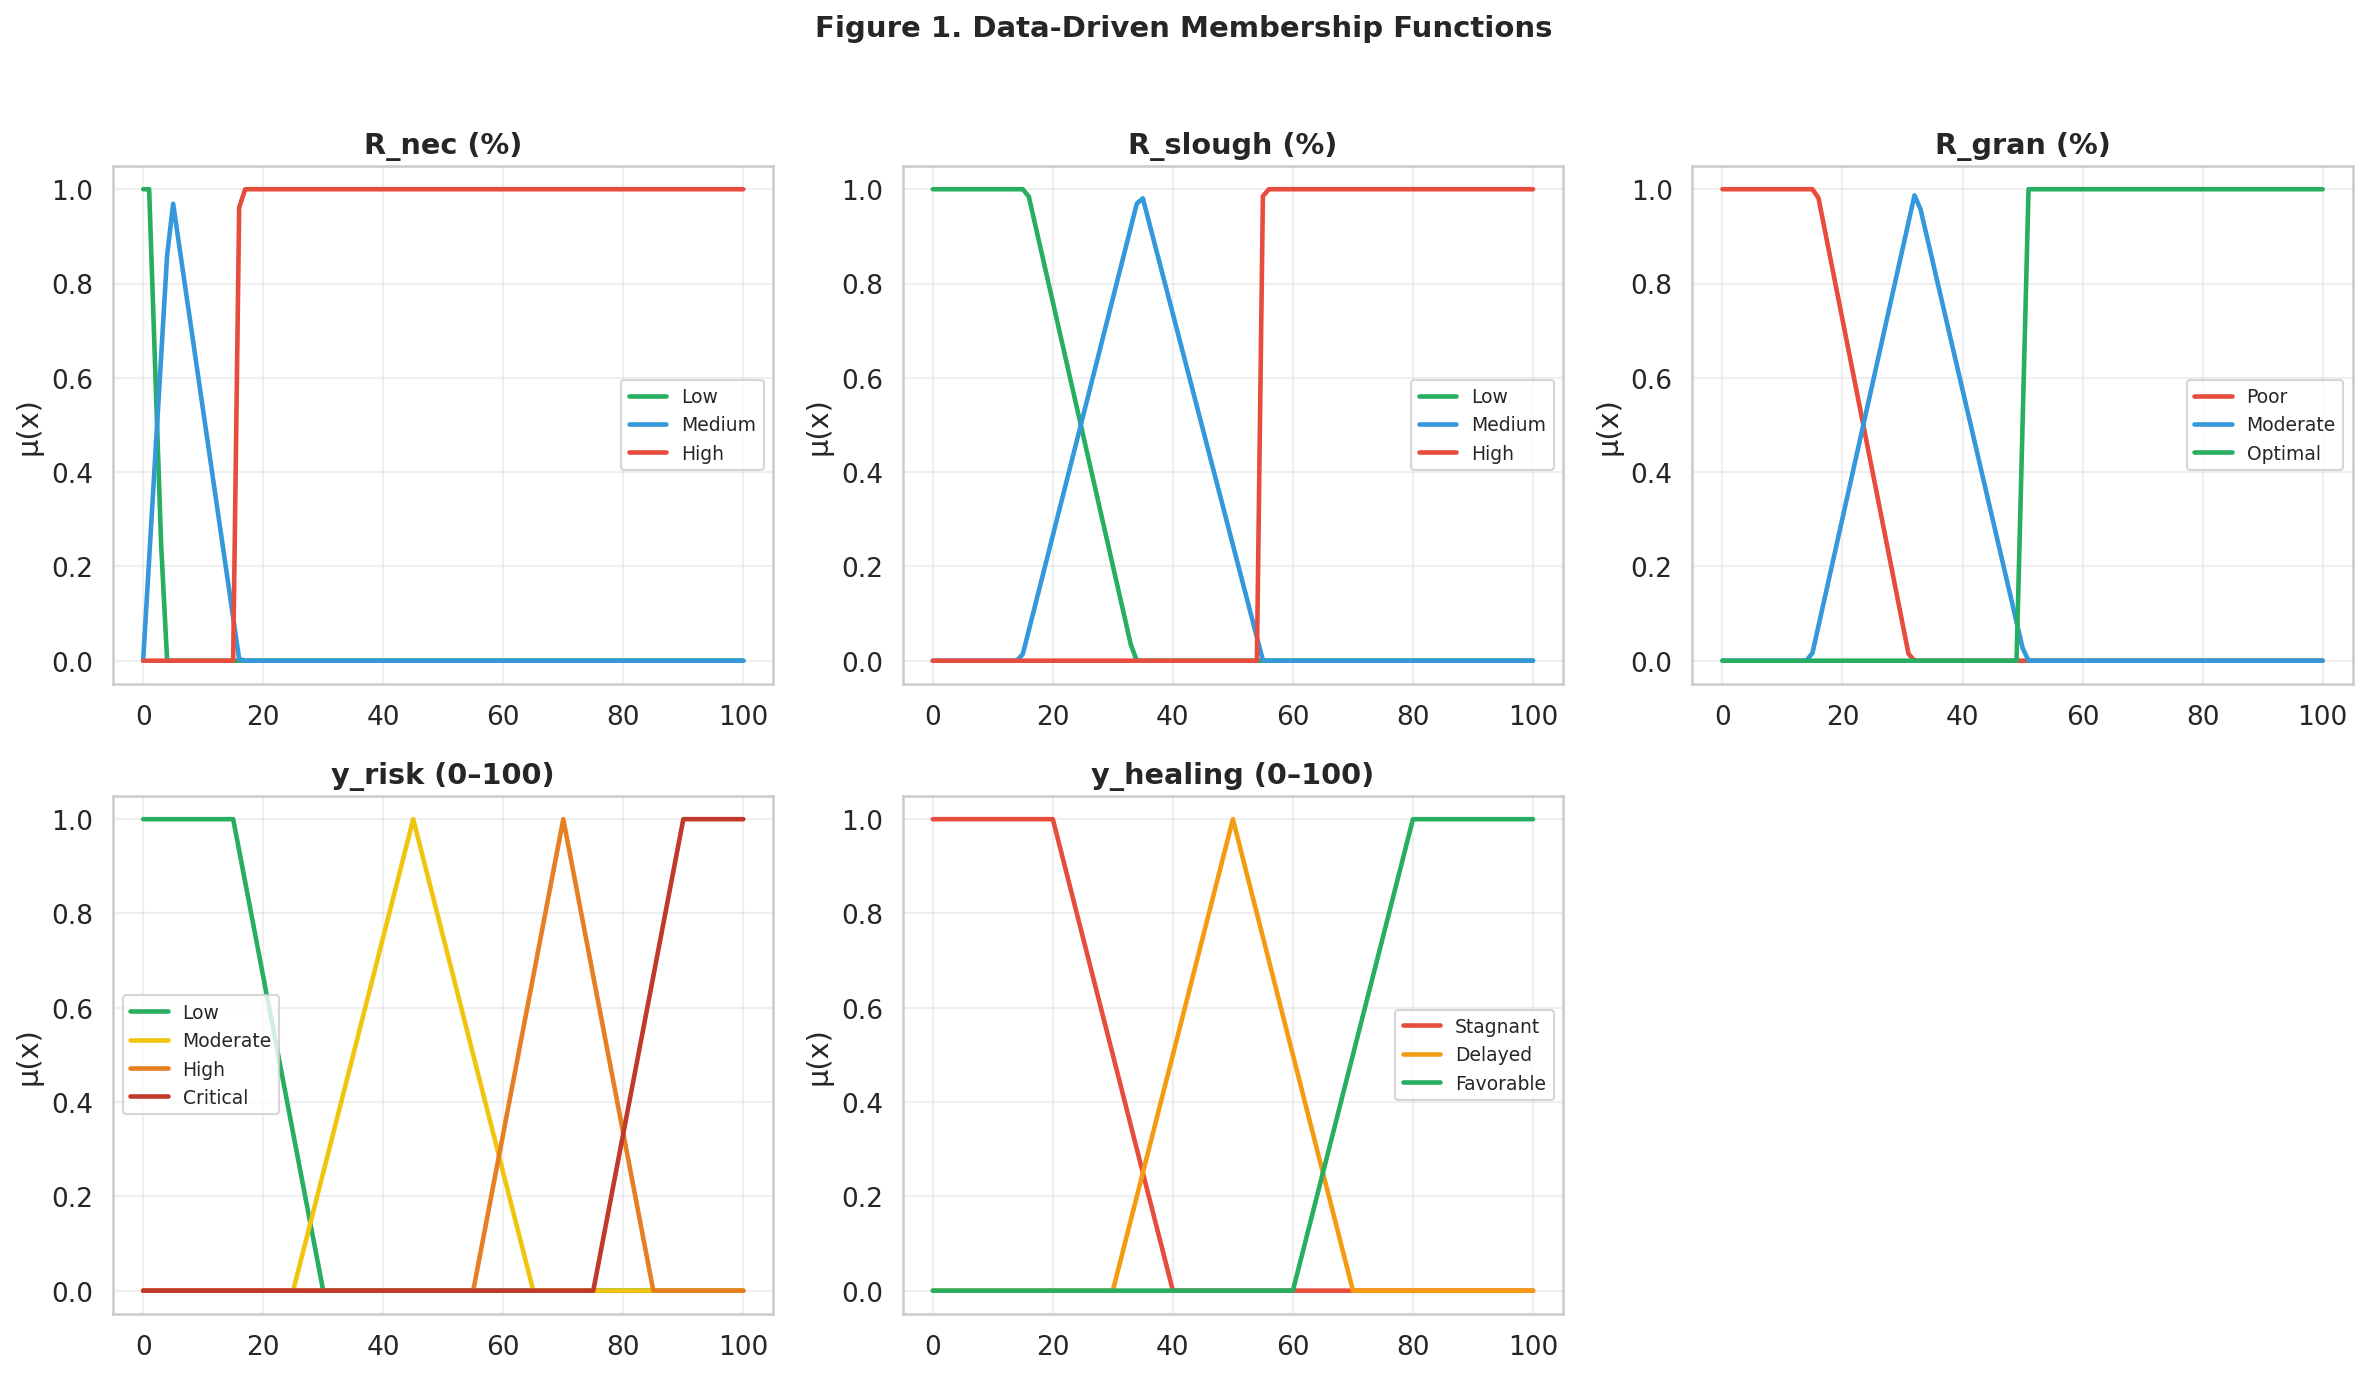

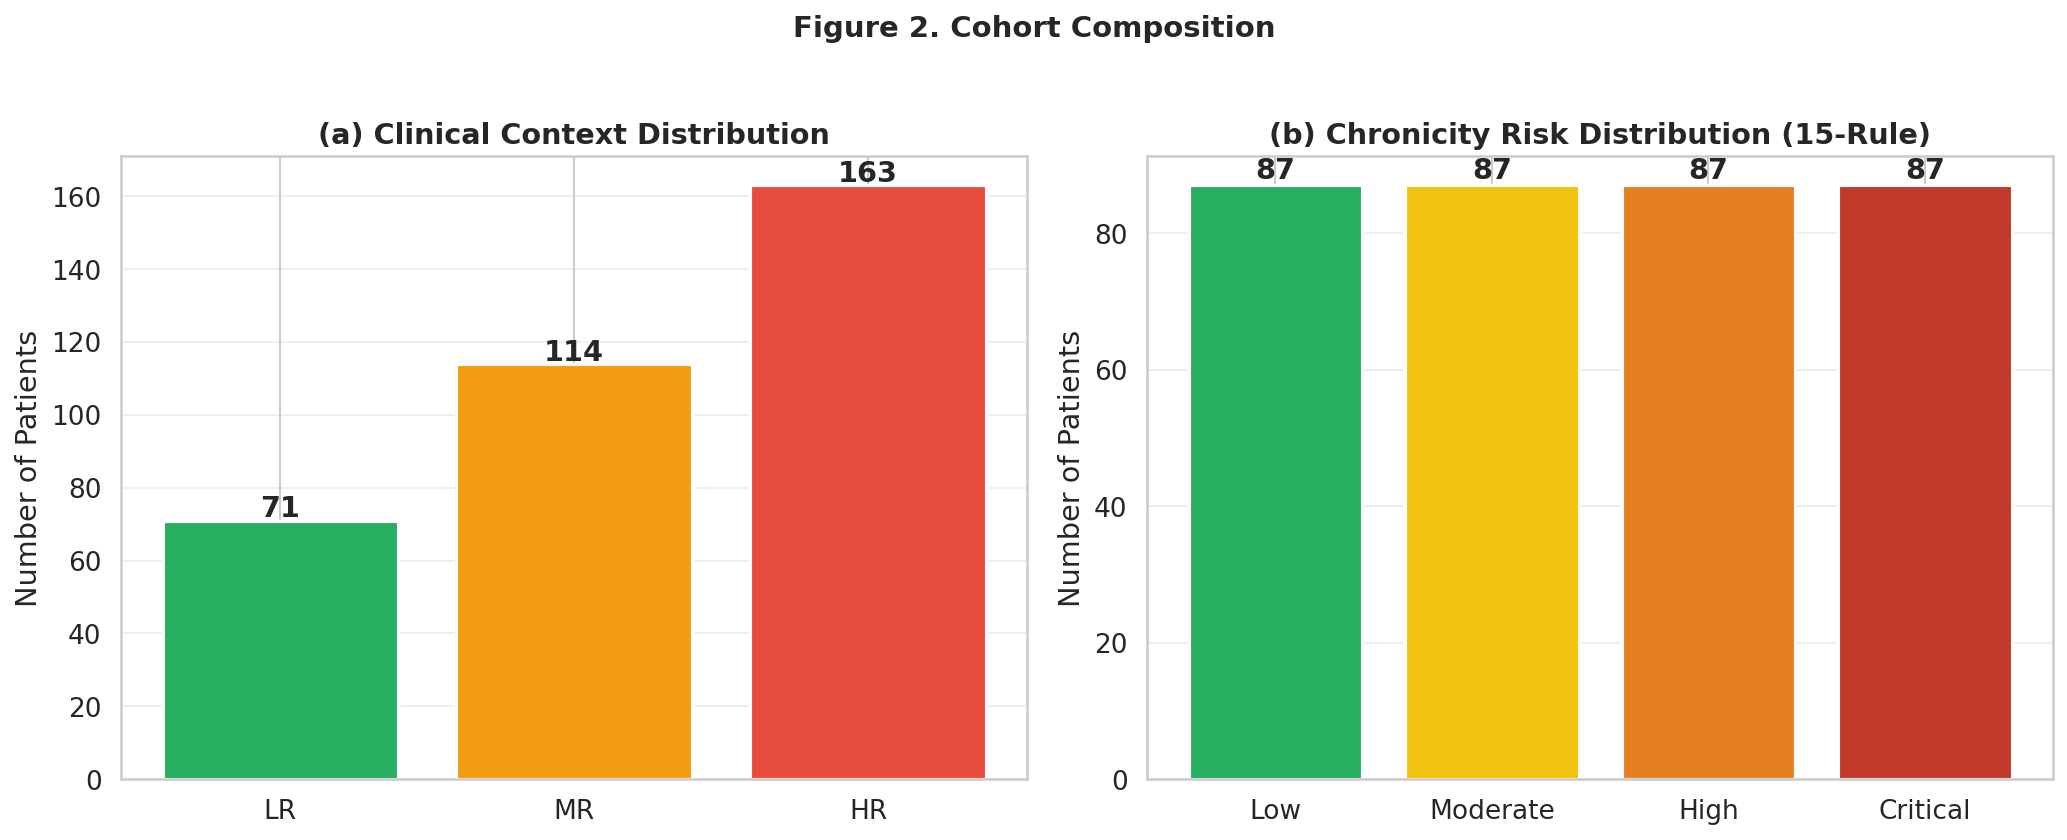

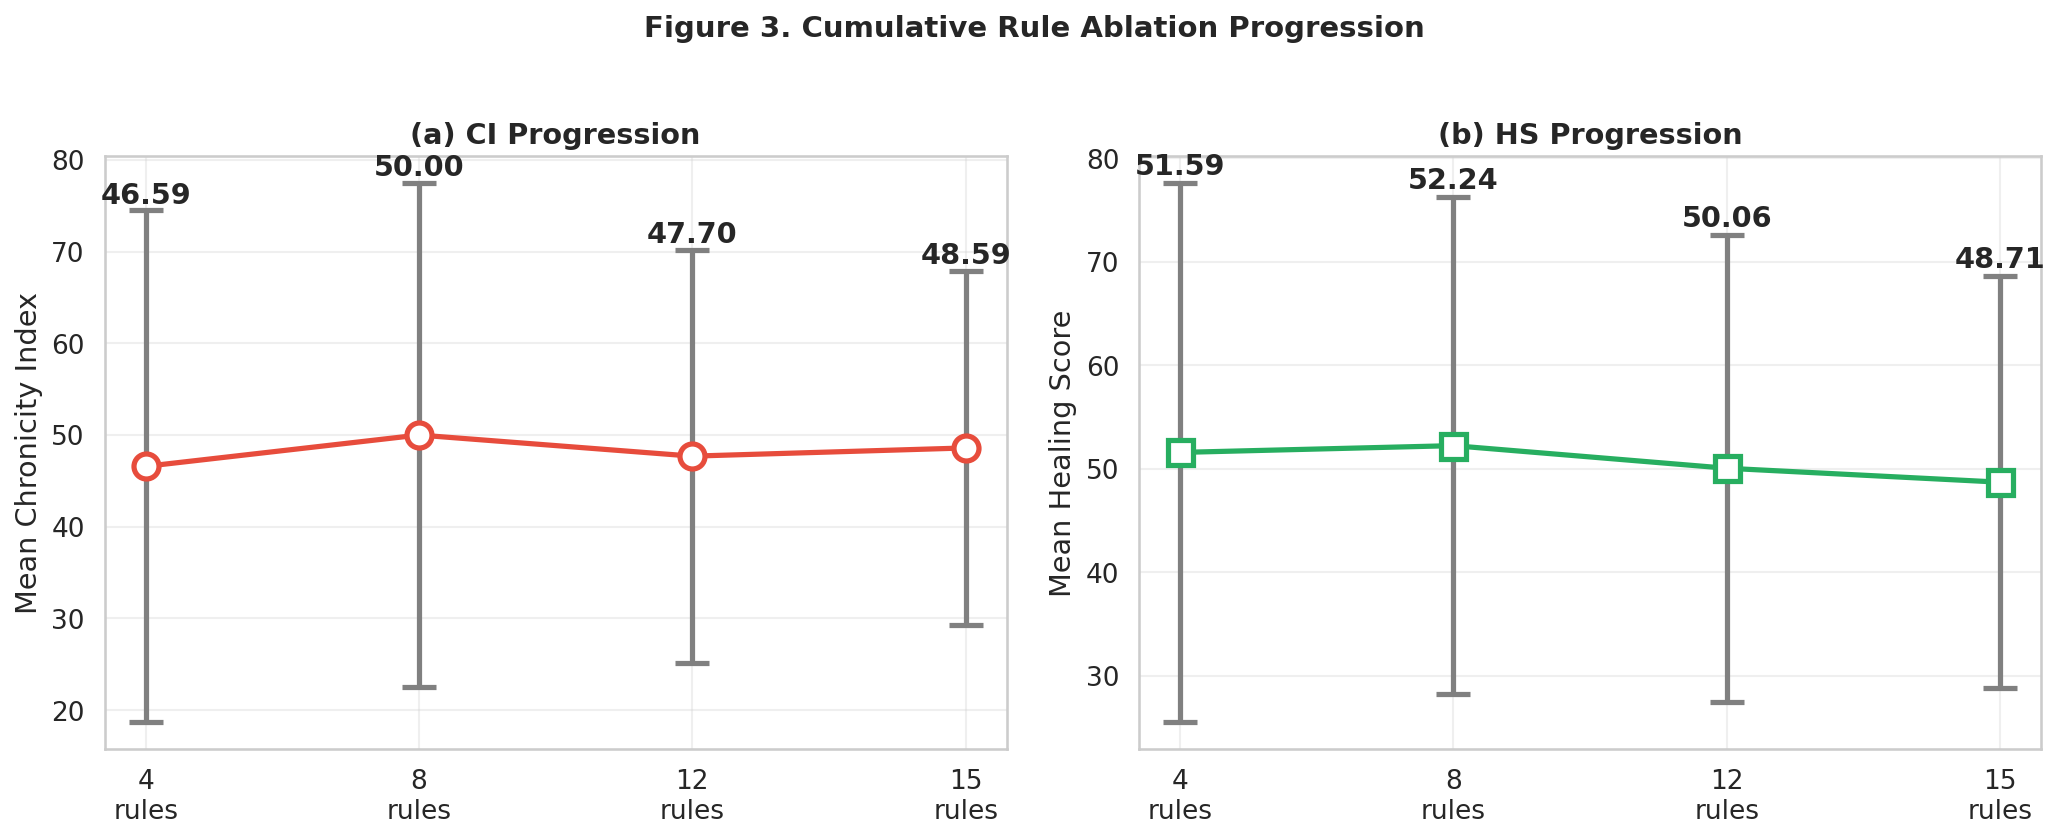

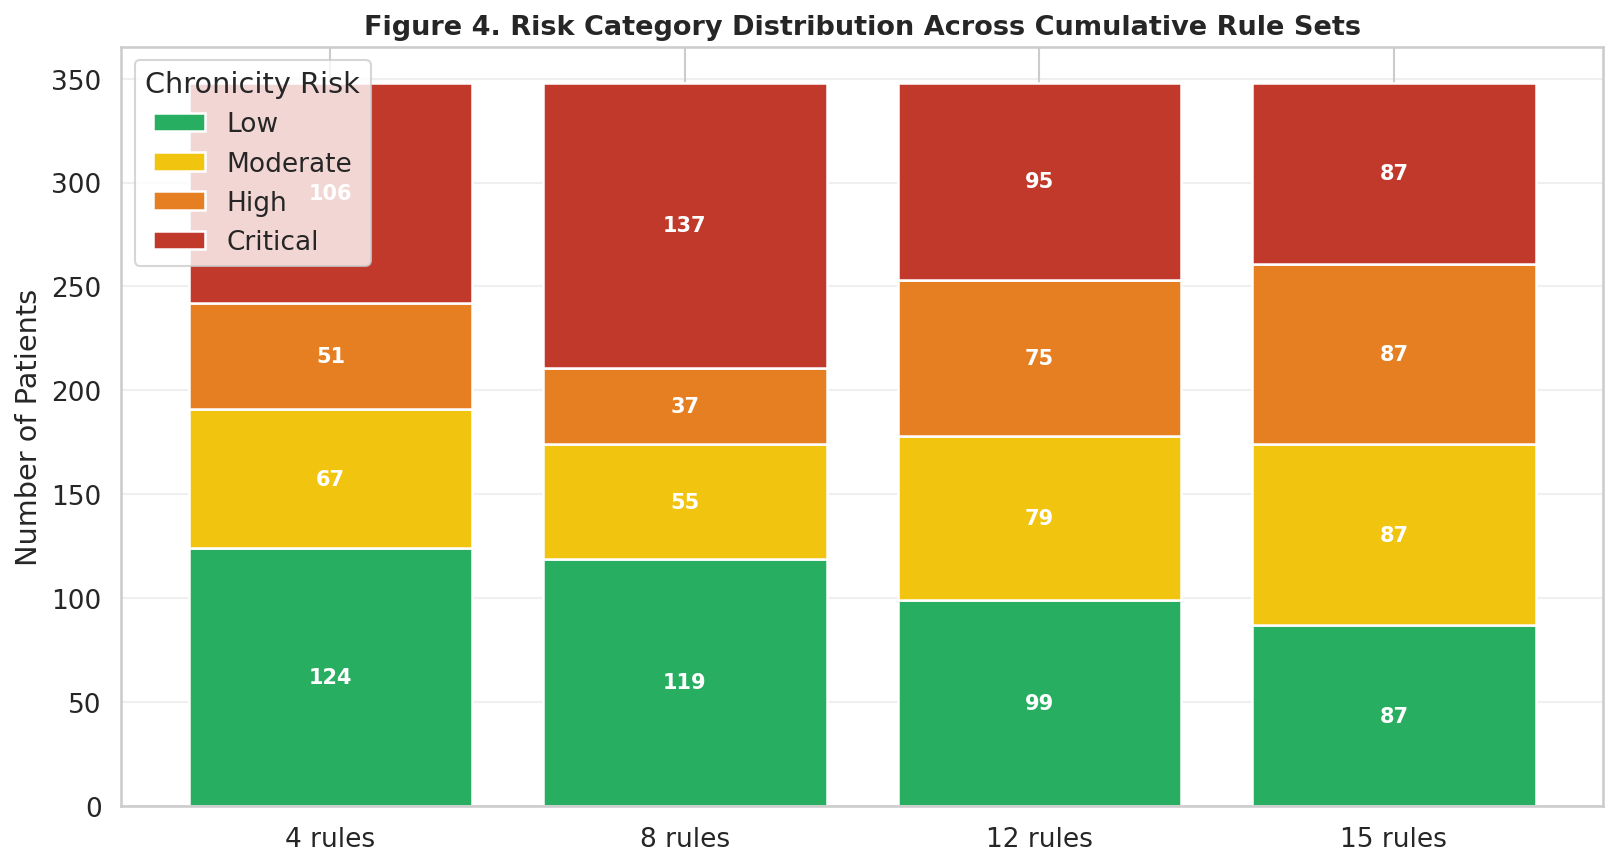

/tmp/ipykernel_4121/2300187642.py:876: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True,
/tmp/ipykernel_4121/2300187642.py:876: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True,


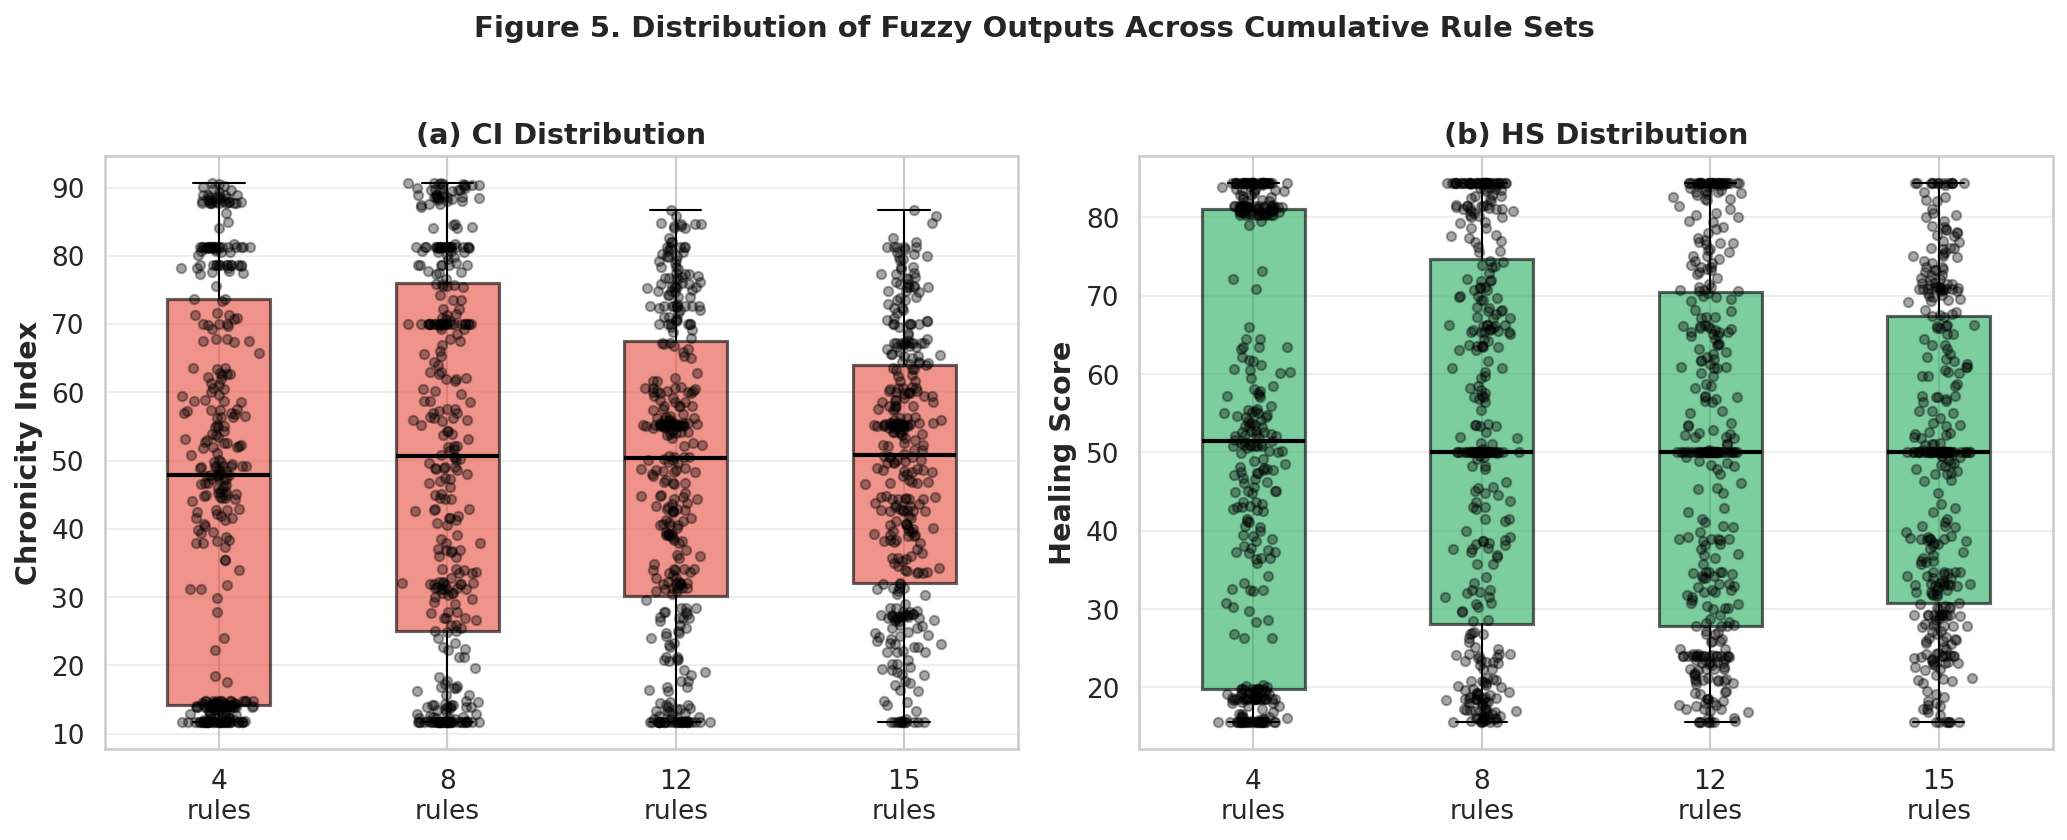

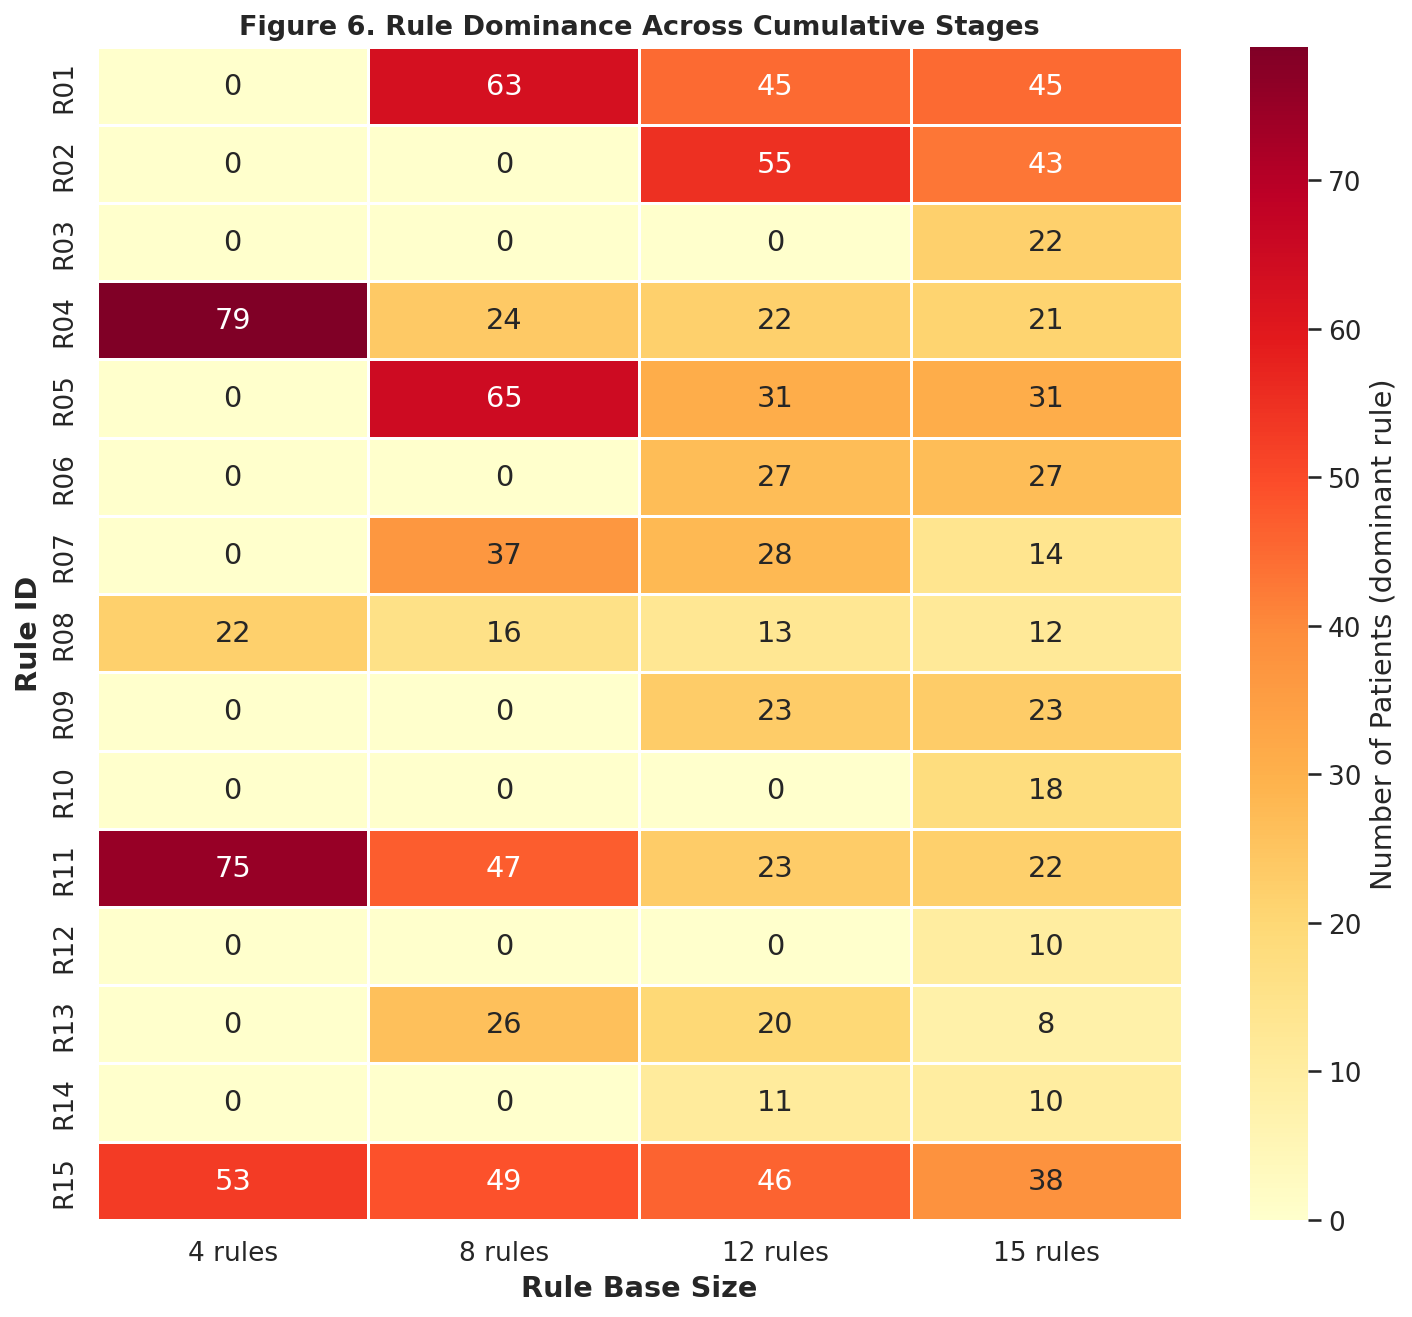

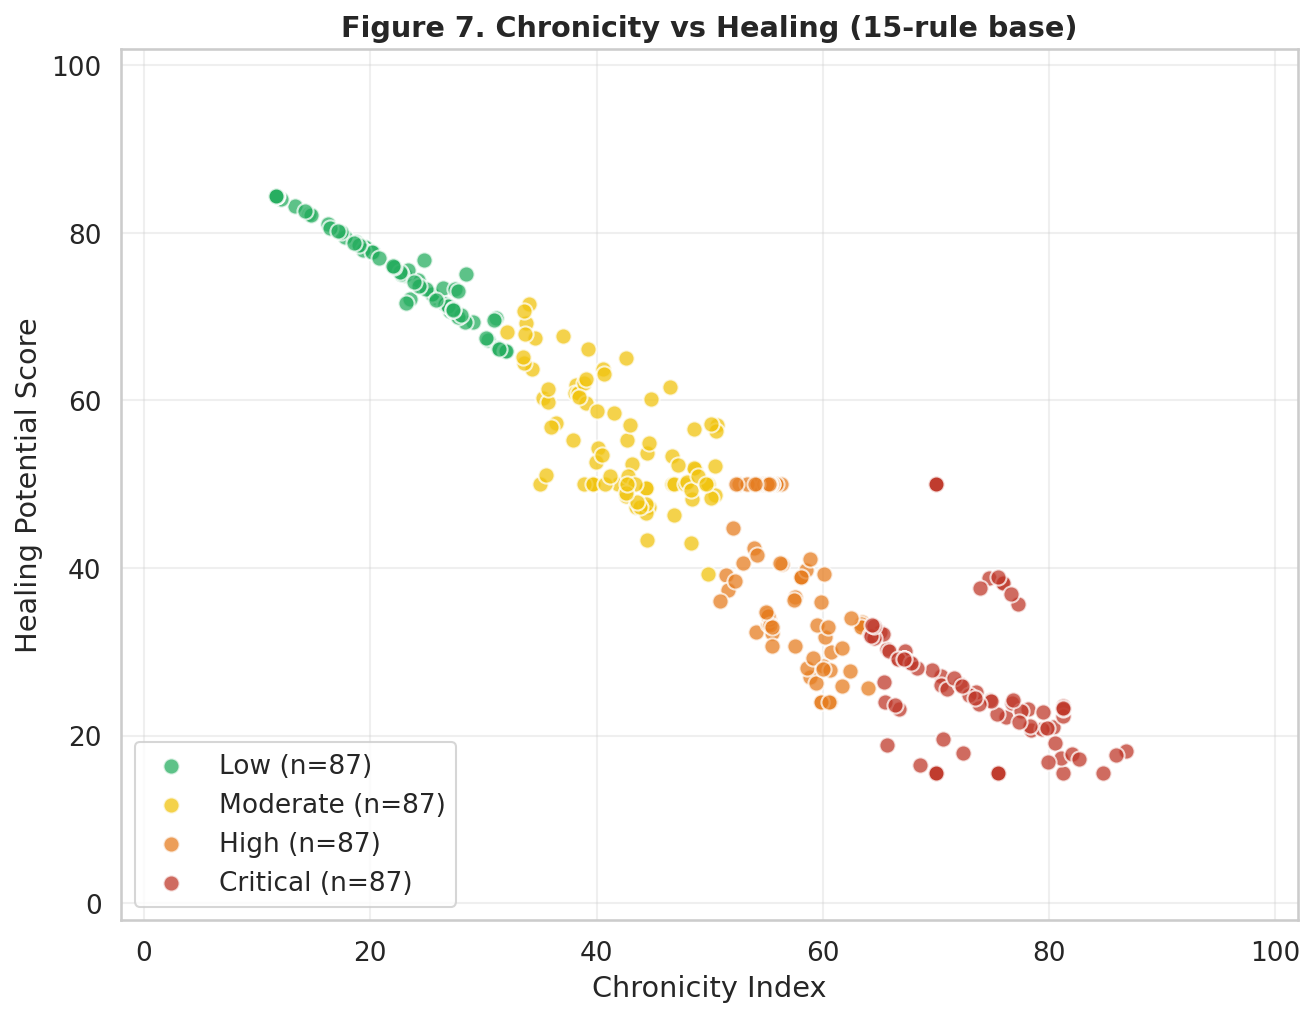

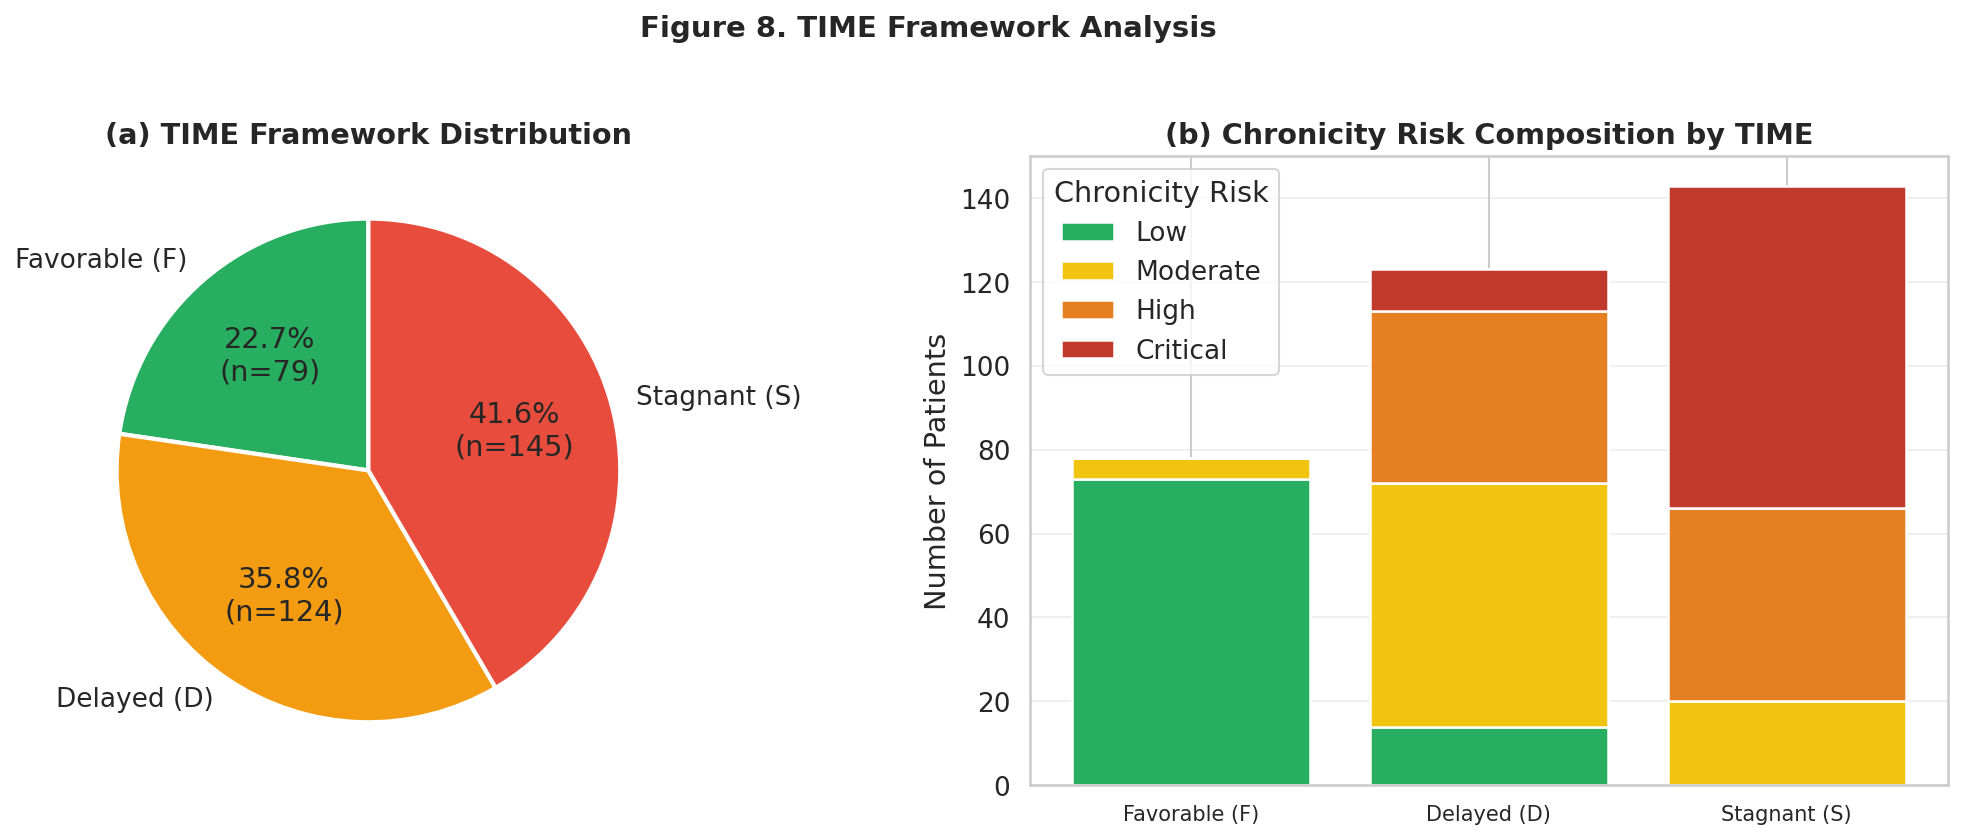

/tmp/ipykernel_4121/2300187642.py:966: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="clinical_context", y=col, data=final_df,
/tmp/ipykernel_4121/2300187642.py:966: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="clinical_context", y=col, data=final_df,
/tmp/ipykernel_4121/2300187642.py:966: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="clinical_context", y=col, data=final_df,


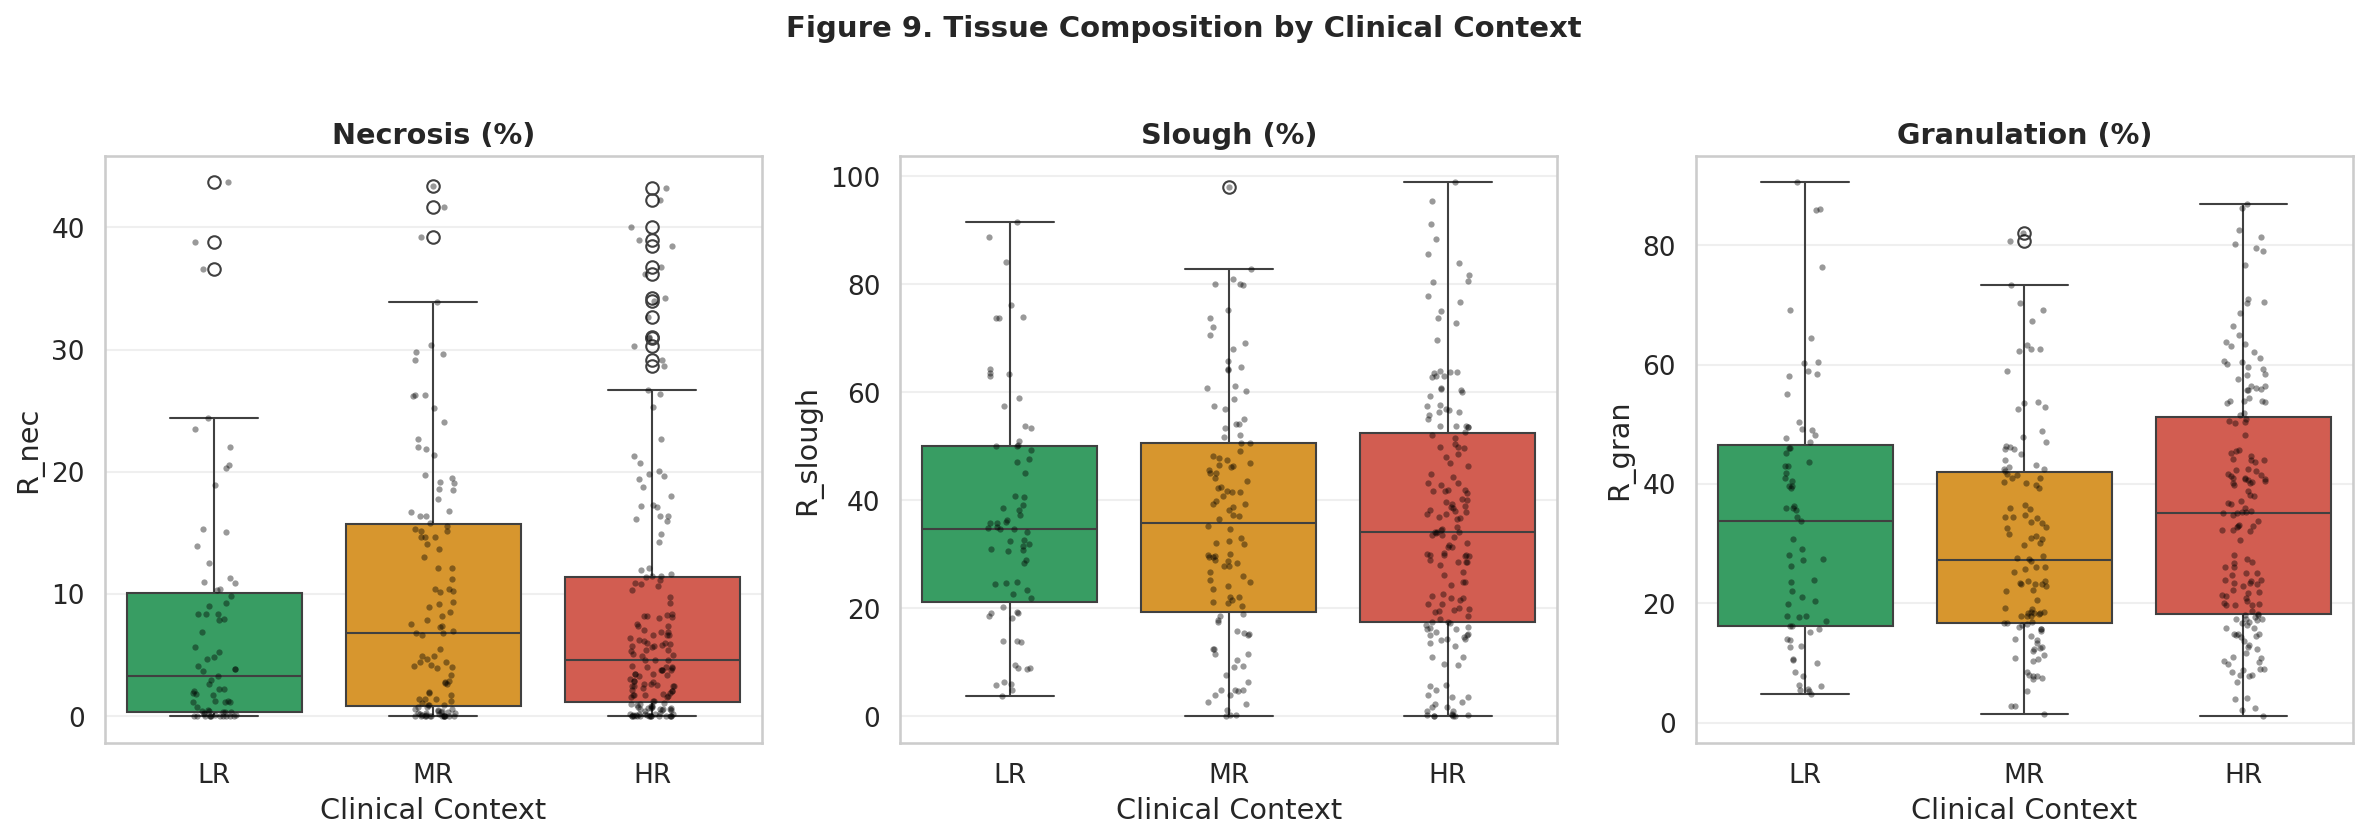

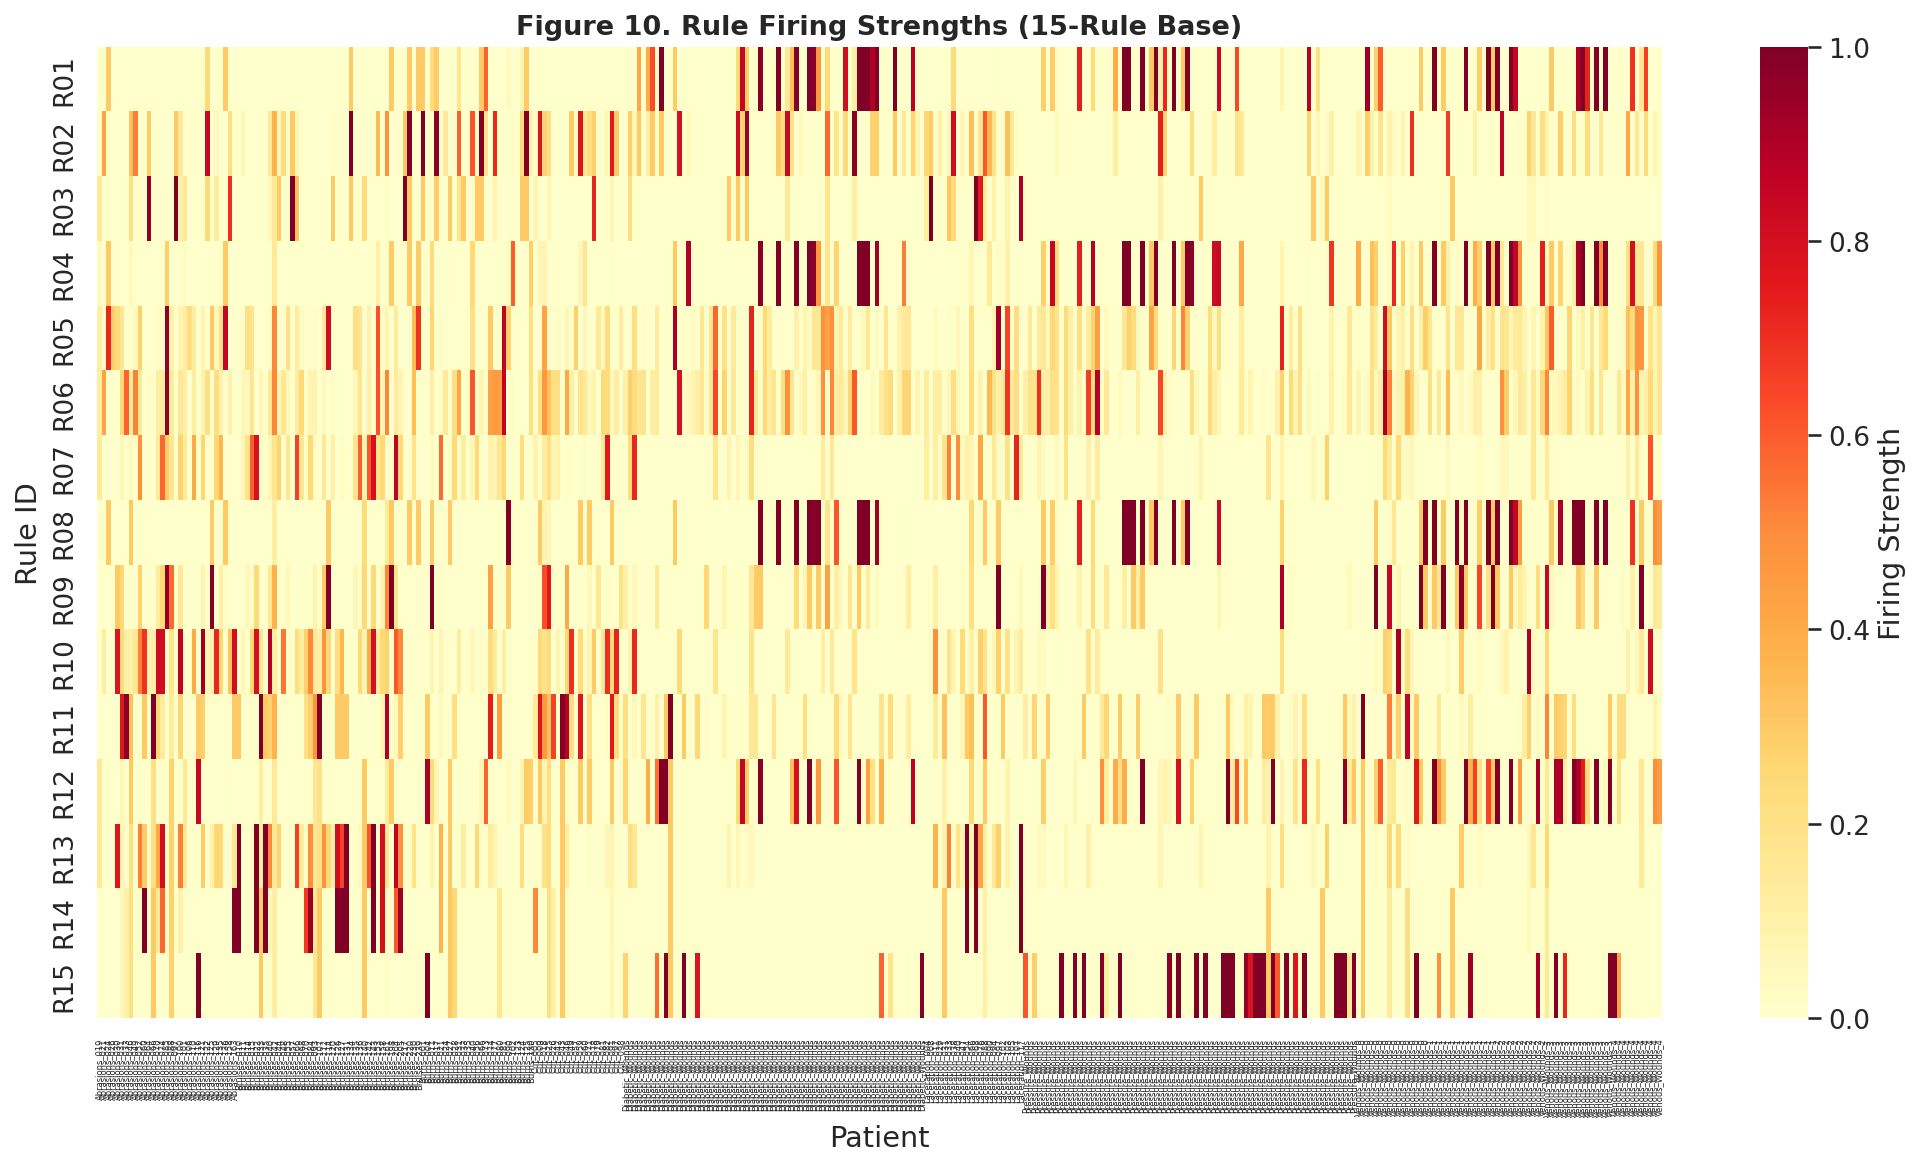


PIPELINE 2 COMPLETE — ALL JOURNAL OUTPUTS SAVED
  /content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/stage8_15_Mamdani_Q1

Tables:
  Table3_Per_Patient_Results.csv        – Per-case CI, HS, labels, dominant rule
  Table5_Summary_by_Risk.csv            – Summary statistics by risk category
  Table6_Rule_Base.csv                  – Rule base description R01–R15
  Table7_Rule_Activation.csv            – Rule activation frequency
  Table8_Context_vs_Risk.csv            – Clinical context × risk crosstab
  Table9_Cumulative_Ablation.csv        – Cumulative rule ablation (4→8→12→15)
  Table10_Category_Distribution.csv     – Category distribution per stage
  Table11_Rule_Coverage.csv             – Rule coverage per stage
  Table12_Tissue_by_Context.csv         – Tissue ratios by context
  Table13_By_WoundType.csv              – Performance by wound type (if available)
  Table14_TIME_Framework.csv            – TIME distribution
  Table15_Pairwise_Tests.csv            – Pairwise 

In [25]:
# ================================================================
# PIPELINE 2 — COMPLETE Q1 JOURNAL IMPLEMENTATION
# Balanced Context + Cumulative Ablation (4→8→12→15) + Full Tables/Figures
# ================================================================

!pip install -q scikit-fuzzy openpyxl pandas numpy matplotlib seaborn scipy

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import skfuzzy as fuzz
from scipy import stats

from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# ---------------- PATHS ----------------
WTP_CSV = "/content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/VisionMamba_Results/Evaluation/WTP/WTP_per_case.csv"
CLINICAL_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/clinical_data_detailed.xlsx"
if not os.path.exists(CLINICAL_XLSX):
    CLINICAL_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/clinical_data_detailed.xlsx"
SYNTHETIC_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/clinical_data_synthetic_matched.xlsx"
OUTPUT_DIR = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/stage8_15_Mamdani_Q1"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.15)
plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300})

print("=" * 80)
print("PIPELINE 2 — Q1 JOURNAL IMPLEMENTATION")
print("=" * 80)

# =================================================================
# STAGE 8 — DATA LOADING
# =================================================================
print("\n[STAGE 8] Data Loading")

wtp = pd.read_csv(WTP_CSV)
print(f"  WTP: {wtp.shape}")

wtp_rename = {}
for c in wtp.columns:
    cl = c.lower()
    if "necrosis" in cl or cl == "r_nec":
        wtp_rename[c] = "R_nec"
    elif "slough" in cl or cl == "r_slough":
        wtp_rename[c] = "R_slough"
    elif "granulation" in cl or cl == "r_gran":
        wtp_rename[c] = "R_gran"
    elif "case" in cl or "patient" in cl or cl == "id":
        wtp_rename[c] = "case_id"
wtp = wtp.rename(columns=wtp_rename)
if "case_id" not in wtp.columns:
    wtp = wtp.rename(columns={wtp.columns[0]: "case_id"})

if os.path.exists(SYNTHETIC_XLSX):
    print("  Using synthetic matched clinical file")
    xls = pd.ExcelFile(SYNTHETIC_XLSX)
else:
    print("  Using original clinical file")
    xls = pd.ExcelFile(CLINICAL_XLSX)

clinical = pd.read_excel(xls, sheet_name="Clinical Data")
if "case_id" not in clinical.columns and "patient_id" in clinical.columns:
    clinical["case_id"] = "case_" + clinical["patient_id"].astype(str)

clin_cols = ["case_id"]
for c in ["age", "hba1c", "infection_status", "vascular_status",
          "diabetes_duration", "healing_progress", "wound_duration_weeks"]:
    if c in clinical.columns:
        clin_cols.append(c)

df = pd.merge(
    clinical[clin_cols],
    wtp[["case_id", "R_nec", "R_slough", "R_gran"]],
    on="case_id", how="inner"
)
print(f"  Merged: {len(df)}")

if len(df) == 0:
    clinical["case_id_alt"] = clinical["patient_id"].astype(str)
    wtp["case_id_alt"] = wtp["case_id"].astype(str).str.replace("case_", "", regex=False)
    df = pd.merge(
        clinical[clin_cols + ["case_id_alt"]],
        wtp[["case_id_alt", "R_nec", "R_slough", "R_gran"]],
        on="case_id_alt", how="inner"
    )
    if "case_id" not in df.columns:
        df["case_id"] = "case_" + df["case_id_alt"].astype(str)

if len(df) == 0:
    raise ValueError("No patients matched")

df = df.loc[:, ~df.columns.duplicated()]
for col in ["R_nec", "R_slough", "R_gran"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=["R_nec", "R_slough", "R_gran"]).reset_index(drop=True)
print(f"  After cleaning: {len(df)} patients")

if "healing_progress" not in df.columns:
    df["healing_progress"] = 50.0
df["healing_rate"] = ((50.0 - df["healing_progress"]) / 50.0).clip(-1, 1)


# =================================================================
# STAGE 9 — BALANCED CLINICAL CONTEXT
# =================================================================
print("\n[STAGE 9] Clinical Context (balanced)")

def compute_clinical_context(row):
    hba1c     = float(row.get("hba1c", 6.5) or 6.5)
    infection = row.get("infection_status", 0)
    vascular  = row.get("vascular_status", 2)
    duration  = float(row.get("diabetes_duration", 0) or 0)
    age       = float(row.get("age", 55) or 55)

    if isinstance(infection, str):
        infection = {"none":0,"no":0,"mild":1,"moderate":2,"severe":3,"yes":2}.get(infection.lower(), 1)
    try: infection = int(infection)
    except: infection = 1

    if isinstance(vascular, str):
        vascular = {"normal":3,"mild":2,"moderate":1,"poor":0,"impaired":0}.get(vascular.lower(), 2)
    try: vascular = int(vascular)
    except: vascular = 2

    score = 0.0
    if age >= 75: score += 0.30
    elif age >= 65: score += 0.18
    elif age >= 55: score += 0.08

    if hba1c >= 9.0: score += 0.30
    elif hba1c >= 8.0: score += 0.18
    elif hba1c >= 7.0: score += 0.08

    if infection >= 3: score += 0.25
    elif infection >= 2: score += 0.15
    elif infection >= 1: score += 0.07

    if vascular <= 0: score += 0.20
    elif vascular <= 1: score += 0.12
    elif vascular <= 2: score += 0.05

    if duration >= 15: score += 0.15
    elif duration >= 10: score += 0.08

    score = float(np.clip(score, 0.0, 1.0))
    if score >= 0.55: return "HR"
    elif score >= 0.28: return "MR"
    else: return "LR"

df["clinical_context"] = df.apply(compute_clinical_context, axis=1)
print("  Context distribution:")
print(df["clinical_context"].value_counts().to_string())


# =================================================================
# STAGE 10 — MEMBERSHIP FUNCTIONS
# =================================================================
print("\n[STAGE 10] MF Calibration")

x_nec    = np.arange(0, 101, 1)
x_slough = np.arange(0, 101, 1)
x_gran   = np.arange(0, 101, 1)
x_risk   = np.arange(0, 101, 1)
x_heal   = np.arange(0, 101, 1)

def pct(arr, p): return float(np.percentile(arr, p))

nec_p20, nec_p50, nec_p80 = pct(df["R_nec"], 20), pct(df["R_nec"], 50), pct(df["R_nec"], 80)
slo_p20, slo_p50, slo_p80 = pct(df["R_slough"], 20), pct(df["R_slough"], 50), pct(df["R_slough"], 80)
gra_p20, gra_p50, gra_p80 = pct(df["R_gran"], 20), pct(df["R_gran"], 50), pct(df["R_gran"], 80)

nec_p20 = max(nec_p20, 1.0); nec_p80 = max(nec_p80, nec_p50 + 1.0)
slo_p20 = max(slo_p20, 1.0); slo_p80 = max(slo_p80, slo_p50 + 1.0)
gra_p20 = max(gra_p20, 1.0); gra_p80 = max(gra_p80, gra_p50 + 1.0)

nec_L = fuzz.trapmf(x_nec, [0, 0, nec_p20, max(nec_p50-1, nec_p20+1)])
nec_M = fuzz.trimf(x_nec,  [max(nec_p20-1, 0), nec_p50, max(nec_p80, nec_p50+1)])
nec_H = fuzz.trapmf(x_nec, [max(nec_p80-1, nec_p50), nec_p80, 100, 100])

slo_L = fuzz.trapmf(x_slough, [0, 0, slo_p20, max(slo_p50-1, slo_p20+1)])
slo_M = fuzz.trimf(x_slough,  [max(slo_p20-1, 0), slo_p50, max(slo_p80, slo_p50+1)])
slo_H = fuzz.trapmf(x_slough, [max(slo_p80-1, slo_p50), slo_p80, 100, 100])

gran_P = fuzz.trapmf(x_gran, [0, 0, gra_p20, max(gra_p50-1, gra_p20+1)])
gran_M = fuzz.trimf(x_gran,  [max(gra_p20-1, 0), gra_p50, max(gra_p80, gra_p50+1)])
gran_O = fuzz.trapmf(x_gran, [max(gra_p80-1, gra_p50), gra_p80, 100, 100])

risk_L = fuzz.trapmf(x_risk, [0, 0, 15, 30])
risk_M = fuzz.trimf(x_risk,  [25, 45, 65])
risk_H = fuzz.trimf(x_risk,  [55, 70, 85])
risk_C = fuzz.trapmf(x_risk, [75, 90, 100, 100])

heal_S = fuzz.trapmf(x_heal, [0, 0, 20, 40])
heal_D = fuzz.trimf(x_heal,  [30, 50, 70])
heal_F = fuzz.trapmf(x_heal, [60, 80, 100, 100])

def fuzzify_inputs(nec, slo, gra):
    return {
        "R_nec": {
            "L": float(fuzz.interp_membership(x_nec, nec_L, nec)),
            "M": float(fuzz.interp_membership(x_nec, nec_M, nec)),
            "H": float(fuzz.interp_membership(x_nec, nec_H, nec)),
        },
        "R_slough": {
            "L": float(fuzz.interp_membership(x_slough, slo_L, slo)),
            "M": float(fuzz.interp_membership(x_slough, slo_M, slo)),
            "H": float(fuzz.interp_membership(x_slough, slo_H, slo)),
        },
        "R_gran": {
            "P": float(fuzz.interp_membership(x_gran, gran_P, gra)),
            "M": float(fuzz.interp_membership(x_gran, gran_M, gra)),
            "O": float(fuzz.interp_membership(x_gran, gran_O, gra)),
        },
    }


# =================================================================
# STAGE 11 — RULE BASE + INFERENCE (UNCHANGED LOGIC)
# =================================================================
RULES = [
    ("R01", "H", "H", "P", "HR", "C", "S", "Stagnant (S)"),
    ("R02", "H", "M", "P", "MR", "H", "S", "Stagnant (S)"),
    ("R03", "H", "L", "P", "LR", "H", "S", "Stagnant (S)"),
    ("R04", "M", "H", "P", "HR", "C", "S", "Stagnant (S)"),
    ("R05", "M", "H", "M", "MR", "H", "D", "Delayed (D)"),
    ("R06", "M", "M", "M", "MR", "M", "D", "Delayed (D)"),
    ("R07", "M", "L", "M", "LR", "M", "D", "Delayed (D)"),
    ("R08", "L", "H", "P", "HR", "H", "S", "Stagnant (S)"),
    ("R09", "L", "H", "M", "MR", "M", "D", "Delayed (D)"),
    ("R10", "L", "M", "M", "LR", "M", "D", "Delayed (D)"),
    ("R11", "L", "M", "O", "MR", "L", "F", "Favorable (F)"),
    ("R12", "L", "L", "P", "HR", "M", "D", "Delayed (D)"),
    ("R13", "L", "L", "M", "LR", "L", "F", "Favorable (F)"),
    ("R14", "L", "L", "O", "LR", "L", "F", "Favorable (F)"),
    ("R15", "L", "L", "O", "HR", "L", "F", "Favorable (F)"),
]

STAGE_RULE_SETS = {
    "4-Rule (Core)":  ["R04", "R08", "R11", "R15"],
    "8-Rule":         ["R04", "R08", "R11", "R15", "R01", "R05", "R07", "R13"],
    "12-Rule":        ["R04", "R08", "R11", "R15", "R01", "R05", "R07", "R13",
                       "R02", "R06", "R09", "R14"],
    "15-Rule (Full)": [r[0] for r in RULES],
}

def context_weight(ctx_label, rule_ctx):
    order = {"LR": 0, "MR": 1, "HR": 2}
    d = abs(order[ctx_label] - order[rule_ctx])
    return {0: 1.0, 1: 0.3, 2: 0.0}[d]

def fire_rules(fuzzy_inputs, context_label, active_rule_ids):
    fired = []
    for r in RULES:
        if r[0] not in active_rule_ids: continue
        rid, nt, st, gt, ct, rt, ht, tm = r
        m_nec  = fuzzy_inputs["R_nec"][nt]
        m_slo  = fuzzy_inputs["R_slough"][st]
        m_gran = fuzzy_inputs["R_gran"][gt]
        tissue_strength = sorted([m_nec, m_slo, m_gran], reverse=True)[1]
        w = context_weight(context_label, ct)
        fired.append({
            "rule_id": rid, "strength": float(tissue_strength * w),
            "risk_term": rt, "heal_term": ht, "time_label": tm,
        })
    return fired

def defuzzify(fired, row=None):
    agg_r = np.zeros_like(x_risk); agg_h = np.zeros_like(x_heal)
    rmap = {"L": risk_L, "M": risk_M, "H": risk_H, "C": risk_C}
    hmap = {"S": heal_S, "D": heal_D, "F": heal_F}
    any_fired = False
    for m in fired:
        if m["strength"] <= 0: continue
        any_fired = True
        agg_r = np.fmax(agg_r, np.fmin(m["strength"], rmap[m["risk_term"]]))
        agg_h = np.fmax(agg_h, np.fmin(m["strength"], hmap[m["heal_term"]]))
    if any_fired:
        try: r = float(fuzz.defuzz(x_risk, agg_r, "centroid"))
        except Exception: r = 50.0
        try: h = float(fuzz.defuzz(x_heal, agg_h, "centroid"))
        except Exception: h = 50.0
        return r, h
    if row is not None:
        heuristic_ci = np.clip(
            0.5 * row["R_nec"] + 0.3 * row["R_slough"] - 0.2 * row["R_gran"] + 40, 0, 100)
        return float(heuristic_ci), float(100 - heuristic_ci)
    return 50.0, 50.0

RISK_THRESHOLDS = (30, 50, 75)

def risk_label_from_value(v, thresholds=None):
    t1, t2, t3 = thresholds if thresholds is not None else RISK_THRESHOLDS
    if v < t1: return "Low"
    if v < t2: return "Moderate"
    if v < t3: return "High"
    return "Critical"

def heal_label_from_value(v):
    if v < 35: return "Stagnant"
    if v < 60: return "Delayed"
    return "Favorable"

def run_inference(df_input, active_rule_ids, thresholds=None):
    risk_vals, heal_vals, risk_labs, heal_labs = [], [], [], []
    dominant_rules, time_labels, fallback_flags = [], [], []
    rule_strengths_all = []
    for _, row in df_input.iterrows():
        fi = fuzzify_inputs(row["R_nec"], row["R_slough"], row["R_gran"])
        fired = fire_rules(fi, row["clinical_context"], active_rule_ids)
        r, h = defuzzify(fired, row=row)
        risk_vals.append(r); heal_vals.append(h)
        risk_labs.append(risk_label_from_value(r, thresholds))
        heal_labs.append(heal_label_from_value(h))
        fired_nz = [m for m in fired if m["strength"] > 0]
        if fired_nz:
            dom = max(fired_nz, key=lambda m: m["strength"])
            dominant_rules.append(dom["rule_id"])
            time_labels.append(dom["time_label"])
            fallback_flags.append(False)
        else:
            dominant_rules.append("—")
            time_labels.append("—")
            fallback_flags.append(True)
        # Save per-rule strengths for coverage analysis
        rule_strengths_all.append({m["rule_id"]: m["strength"] for m in fired})
    return pd.DataFrame({
        "case_id": df_input["case_id"].values,
        "chronicity_index": risk_vals,
        "healing_score": heal_vals,
        "chronicity_label": risk_labs,
        "healing_label": heal_labs,
        "dominant_rule": dominant_rules,
        "TIME_label": time_labels,
        "fallback_used": fallback_flags,
    }), rule_strengths_all

print("\n[STAGE 12] Threshold calibration ...")
full_pass, _ = run_inference(df, [r[0] for r in RULES])
p25, p50, p75 = np.percentile(full_pass["chronicity_index"], [25, 50, 75])
RISK_THRESHOLDS = (float(p25), float(p50), float(p75))
print(f"  Adaptive thresholds: ({RISK_THRESHOLDS[0]:.2f}, {RISK_THRESHOLDS[1]:.2f}, {RISK_THRESHOLDS[2]:.2f})")

# =================================================================
# STAGE 13 — CUMULATIVE ABLATION
# =================================================================
print("\n[STAGE 13] Cumulative Rule Ablation")

stage_results = {}
stage_rule_strengths = {}
stage_order = list(STAGE_RULE_SETS.keys())

for stage, rule_ids in STAGE_RULE_SETS.items():
    res, rstr = run_inference(df, rule_ids, thresholds=RISK_THRESHOLDS)
    stage_results[stage] = res
    stage_rule_strengths[stage] = rstr
    print(f"  {stage:20s}  Mean CI={res['chronicity_index'].mean():.2f}  "
          f"Std CI={res['chronicity_index'].std():.2f}  "
          f"Fallback={res['fallback_used'].sum()}")


# =================================================================
# TABLE 5 — SUMMARY BY RISK CATEGORY (NEW)
# =================================================================
print("\n[TABLE 5] Summary by Chronicity Risk Category")

risk_order = ["Low", "Moderate", "High", "Critical"]
final_df = df.copy()
final_df["chronicity_index"] = stage_results["15-Rule (Full)"]["chronicity_index"].values
final_df["healing_score"]    = stage_results["15-Rule (Full)"]["healing_score"].values
final_df["chronicity_label"] = stage_results["15-Rule (Full)"]["chronicity_label"].values
final_df["healing_label"]    = stage_results["15-Rule (Full)"]["healing_label"].values
final_df["dominant_rule"]    = stage_results["15-Rule (Full)"]["dominant_rule"].values
final_df["TIME_label"]       = stage_results["15-Rule (Full)"]["TIME_label"].values
final_df["fallback_used"]    = stage_results["15-Rule (Full)"]["fallback_used"].values

summary_rows = []
for rl in risk_order:
    sub = final_df[final_df["chronicity_label"] == rl]
    if len(sub) == 0: continue
    summary_rows.append({
        "Risk Category":     rl,
        "N":                 len(sub),
        "N (%)":             f"{100*len(sub)/len(final_df):.1f}%",
        "Mean CI":           f"{sub['chronicity_index'].mean():.2f} ± {sub['chronicity_index'].std():.2f}",
        "Mean HS":           f"{sub['healing_score'].mean():.2f} ± {sub['healing_score'].std():.2f}",
        "Mean R_nec (%)":    f"{sub['R_nec'].mean():.2f} ± {sub['R_nec'].std():.2f}",
        "Mean R_slough (%)": f"{sub['R_slough'].mean():.2f} ± {sub['R_slough'].std():.2f}",
        "Mean R_gran (%)":   f"{sub['R_gran'].mean():.2f} ± {sub['R_gran'].std():.2f}",
        "Mean Age":          f"{sub['age'].mean():.1f} ± {sub['age'].std():.1f}" if 'age' in sub.columns else "—",
        "HR context %":      f"{100*(sub['clinical_context']=='HR').mean():.1f}%",
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(os.path.join(OUTPUT_DIR, "Table5_Summary_by_Risk.csv"), index=False)

print("\n" + "=" * 130)
print("TABLE 5 — Summary by Chronicity Risk Category (n = {})".format(len(final_df)))
print("=" * 130)
print(summary_df.to_string(index=False))
print("=" * 130)


# =================================================================
# TABLE 6 — RULE BASE DESCRIPTION (NEW)
# =================================================================
print("\n[TABLE 6] Rule Base Description")

rule_table = pd.DataFrame([
    {"Rule ID": r[0],
     "IF R_nec": r[1], "IF R_slough": r[2], "IF R_gran": r[3], "IF C": r[4],
     "THEN y_risk": {"L":"Low","M":"Moderate","H":"High","C":"Critical"}[r[5]],
     "THEN y_healing": {"S":"Stagnant","D":"Delayed","F":"Favorable"}[r[6]],
     "TIME": r[7]}
    for r in RULES
])
rule_table.to_csv(os.path.join(OUTPUT_DIR, "Table6_Rule_Base.csv"), index=False)

print("\n" + "=" * 110)
print("TABLE 6 — Mamdani Fuzzy Rule Base (R01–R15)")
print("=" * 110)
print(rule_table.to_string(index=False))


# =================================================================
# TABLE 7 — RULE ACTIVATION FREQUENCY (NEW)
# =================================================================
print("\n[TABLE 7] Rule Activation Frequency")

# Build a lookup dict for rule metadata: rule_id → rule tuple
rule_lookup = {r[0]: r for r in RULES}

activation_rows = []
for stage in stage_order:
    res = stage_results[stage]
    active_ids = STAGE_RULE_SETS[stage]

    for rid in active_ids:
        # Get rule metadata using lookup (avoids variable shadowing)
        rule_meta = rule_lookup[rid]
        rule_desc = (f"({rule_meta[1]},{rule_meta[2]},{rule_meta[3]},{rule_meta[4]}) "
                     f"→ ({rule_meta[5]},{rule_meta[6]})")

        n_dom = int((res["dominant_rule"] == rid).sum())

        # Count any firing (strength > 0.05)
        n_fired = sum(
            1 for rstr in stage_rule_strengths[stage]
            if rstr.get(rid, 0) > 0.05
        )

        activation_rows.append({
            "Configuration":  stage,
            "N rules":        len(active_ids),
            "Rule ID":        rid,
            "Rule IF-THEN":   rule_desc,
            "Dominant (n)":   n_dom,
            "Fired (n)":      n_fired,
            "Fired (%)":      f"{100*n_fired/len(df):.1f}%",
        })

activation_df = pd.DataFrame(activation_rows)
activation_df.to_csv(os.path.join(OUTPUT_DIR, "Table7_Rule_Activation.csv"), index=False)

# Print compact summary (15-rule stage)
act_15 = (activation_df[activation_df["Configuration"] == "15-Rule (Full)"]
          .sort_values("Fired (n)", ascending=False))
print("\n" + "=" * 100)
print("TABLE 7 — Rule Activation at 15-rule stage (sorted by frequency)")
print("=" * 100)
print(act_15[["Rule ID", "Rule IF-THEN", "Dominant (n)", "Fired (n)", "Fired (%)"]]
      .to_string(index=False))


# =================================================================
# TABLE 8 — CLINICAL CONTEXT vs CHRONICITY RISK (NEW)
# =================================================================
print("\n[TABLE 8] Clinical Context × Chronicity Risk")

ctx_risk = pd.crosstab(final_df["clinical_context"], final_df["chronicity_label"],
                       margins=True, margins_name="Total")
ctx_risk = ctx_risk.reindex(columns=[c for c in risk_order if c in ctx_risk.columns] + ["Total"])
ctx_risk.to_csv(os.path.join(OUTPUT_DIR, "Table8_Context_vs_Risk.csv"))

print("\n" + "=" * 100)
print("TABLE 8 — Clinical Context (C) × Chronicity Risk")
print("=" * 100)
print(ctx_risk.to_string())


# =================================================================
# TABLE 9 — CUMULATIVE ABLATION (existing)
# =================================================================
print("\n[TABLE 9] Cumulative Ablation")

stats_rows = []
for i, stage in enumerate(stage_order):
    res = stage_results[stage]
    ci = res["chronicity_index"].values
    hs = res["healing_score"].values
    if i == 0:
        stats_rows.append({
            "Configuration": stage,
            "N rules": len(STAGE_RULE_SETS[stage]),
            "Mean CI": f"{ci.mean():.3f}",
            "Std CI":  f"{ci.std():.3f}",
            "Mean HS": f"{hs.mean():.3f}",
            "Δ CI vs prev": "—",
            "Wilcoxon p": "—",
            "Significance": "—",
            "Patients shifted": "—",
        })
        continue
    prev = stage_results[stage_order[i-1]]
    prev_ci = prev["chronicity_index"].values
    delta = ci.mean() - prev_ci.mean()
    try: _, w_p = stats.wilcoxon(prev_ci, ci)
    except Exception: w_p = np.nan
    shifted = int((res["chronicity_label"].values != prev["chronicity_label"].values).sum())
    sig = ("***" if (not np.isnan(w_p) and w_p < 0.001) else
           "**"  if (not np.isnan(w_p) and w_p < 0.01)  else
           "*"   if (not np.isnan(w_p) and w_p < 0.05)  else "ns")
    stats_rows.append({
        "Configuration": stage,
        "N rules": len(STAGE_RULE_SETS[stage]),
        "Mean CI": f"{ci.mean():.3f}",
        "Std CI":  f"{ci.std():.3f}",
        "Mean HS": f"{hs.mean():.3f}",
        "Δ CI vs prev": f"{delta:+.3f}",
        "Wilcoxon p": f"{w_p:.4f}" if not np.isnan(w_p) else "—",
        "Significance": sig,
        "Patients shifted": shifted,
    })

stats_table = pd.DataFrame(stats_rows)
stats_table.to_csv(os.path.join(OUTPUT_DIR, "Table9_Cumulative_Ablation.csv"), index=False)

print("\n" + "=" * 120)
print("TABLE 9 — Cumulative Rule Ablation (4 → 8 → 12 → 15)")
print("=" * 120)
print(stats_table.to_string(index=False))
print("=" * 120)


# =================================================================
# TABLE 10 — CATEGORY DISTRIBUTION
# =================================================================
cat_rows = []
for stage in stage_order:
    res = stage_results[stage]
    row = {"Configuration": stage, "N rules": len(STAGE_RULE_SETS[stage])}
    for cat in risk_order:
        row[cat] = int((res["chronicity_label"] == cat).sum())
    # Add intermediate rate
    row["Interm. (%)"] = f"{100*(row['Moderate'] + row['High'])/len(df):.1f}%"
    cat_rows.append(row)

cat_table = pd.DataFrame(cat_rows)
cat_table.to_csv(os.path.join(OUTPUT_DIR, "Table10_Category_Distribution.csv"), index=False)

print("\n" + "=" * 110)
print("TABLE 10 — Risk Category Distribution Across Cumulative Rule Sets")
print("=" * 110)
print(cat_table.to_string(index=False))


# =================================================================
# TABLE 11 — RULE COVERAGE
# =================================================================
coverage_rows = []
for stage in stage_order:
    res = stage_results[stage]
    active = STAGE_RULE_SETS[stage]
    n_dom = sum(1 for rid in active if (res["dominant_rule"] == rid).sum() > 0)
    n_fired_any = sum(
        1 for rid in active
        if any(rstr.get(rid, 0) > 0.05 for rstr in stage_rule_strengths[stage])
    )
    coverage_rows.append({
        "Configuration":          stage,
        "Total rules":            len(active),
        "Rules dominant ≥1":      n_dom,
        "Rules fired ≥1":         n_fired_any,
        "Dominance coverage (%)": f"{100*n_dom/len(active):.1f}%",
        "Firing coverage (%)":    f"{100*n_fired_any/len(active):.1f}%",
    })

coverage_df = pd.DataFrame(coverage_rows)
coverage_df.to_csv(os.path.join(OUTPUT_DIR, "Table11_Rule_Coverage.csv"), index=False)

print("\n" + "=" * 110)
print("TABLE 11 — Rule Activation Coverage")
print("=" * 110)
print(coverage_df.to_string(index=False))


# =================================================================
# TABLE 12 — TISSUE-CONTEXT CORRELATION (NEW)
# =================================================================
print("\n[TABLE 12] Tissue ratios by clinical context")

tissue_by_ctx = final_df.groupby("clinical_context").agg({
    "R_nec":    ["mean", "std"],
    "R_slough": ["mean", "std"],
    "R_gran":   ["mean", "std"],
    "age":      ["mean", "std"],
    "hba1c":    ["mean", "std"],
}).round(2)

# Flatten multi-index
tissue_by_ctx.columns = [f"{col[0]}_{col[1]}" for col in tissue_by_ctx.columns]
tissue_by_ctx = tissue_by_ctx.reindex(["LR", "MR", "HR"])
tissue_by_ctx["N"] = final_df.groupby("clinical_context").size().reindex(["LR", "MR", "HR"])
tissue_by_ctx.to_csv(os.path.join(OUTPUT_DIR, "Table12_Tissue_by_Context.csv"))

print("\n" + "=" * 120)
print("TABLE 12 — Tissue Composition and Clinical Variables by Context")
print("=" * 120)
print(tissue_by_ctx.to_string())


# =================================================================
# TABLE 13 — WOUND-TYPE STRATIFICATION (NEW)
# =================================================================
print("\n[TABLE 13] Performance by wound type")

if "WoundType" in final_df.columns:
    wt_summary = final_df.groupby("WoundType").agg({
        "chronicity_index":   ["mean", "std", "count"],
        "healing_score":      ["mean", "std"],
        "R_nec":              ["mean"],
        "R_slough":           ["mean"],
        "R_gran":             ["mean"],
    }).round(2)
    wt_summary.columns = [f"{col[0]}_{col[1]}" for col in wt_summary.columns]
    wt_summary.to_csv(os.path.join(OUTPUT_DIR, "Table13_By_WoundType.csv"))
    print("\n" + "=" * 120)
    print("TABLE 13 — Chronicity Analysis by Wound Type")
    print("=" * 120)
    print(wt_summary.to_string())


# =================================================================
# TABLE 14 — TIME FRAMEWORK ANALYSIS
# =================================================================
print("\n[TABLE 14] TIME framework distribution")

time_order = ["Favorable (F)", "Delayed (D)", "Stagnant (S)"]
time_summary = pd.DataFrame({
    "TIME Label":   time_order,
    "N":            [int((final_df["TIME_label"] == t).sum()) for t in time_order],
    "N (%)":        [f"{100*(final_df['TIME_label'] == t).mean():.1f}%" for t in time_order],
    "Mean CI":      [f"{final_df[final_df['TIME_label'] == t]['chronicity_index'].mean():.2f}" if (final_df["TIME_label"] == t).any() else "—" for t in time_order],
    "Mean HS":      [f"{final_df[final_df['TIME_label'] == t]['healing_score'].mean():.2f}" if (final_df["TIME_label"] == t).any() else "—" for t in time_order],
})
time_summary.to_csv(os.path.join(OUTPUT_DIR, "Table14_TIME_Framework.csv"), index=False)

print("\n" + "=" * 100)
print("TABLE 14 — TIME Framework Distribution")
print("=" * 100)
print(time_summary.to_string(index=False))


# =================================================================
# TABLE 15 — STATISTICAL COMPARISON OF STAGES
# =================================================================
print("\n[TABLE 15] Pairwise statistical tests")

pairwise_rows = []
for i, s1 in enumerate(stage_order):
    for j, s2 in enumerate(stage_order):
        if i >= j: continue
        ci1 = stage_results[s1]["chronicity_index"].values
        ci2 = stage_results[s2]["chronicity_index"].values
        try:
            _, w_p = stats.wilcoxon(ci1, ci2)
        except Exception:
            w_p = np.nan
        try:
            _, t_p = stats.ttest_rel(ci1, ci2)
        except Exception:
            t_p = np.nan
        delta = ci2.mean() - ci1.mean()
        pairwise_rows.append({
            "Comparison":    f"{s1} → {s2}",
            "Δ Mean CI":     f"{delta:+.3f}",
            "Wilcoxon p":    f"{w_p:.4f}" if not np.isnan(w_p) else "—",
            "Paired-t p":    f"{t_p:.4f}" if not np.isnan(t_p) else "—",
            "Significant":   "Yes" if (not np.isnan(w_p) and w_p < 0.05) else "No",
        })

pairwise_df = pd.DataFrame(pairwise_rows)
pairwise_df.to_csv(os.path.join(OUTPUT_DIR, "Table15_Pairwise_Tests.csv"), index=False)
print("\n" + "=" * 100)
print("TABLE 15 — Pairwise Statistical Comparison")
print("=" * 100)
print(pairwise_df.to_string(index=False))


# =================================================================
# TABLE 16 — EXAMPLE CASE EXPLANATIONS
# =================================================================
print("\n[TABLE 16] Representative case explanations")

sample_cases = pd.concat([
    final_df[final_df["chronicity_label"] == "Low"].head(2),
    final_df[final_df["chronicity_label"] == "Moderate"].head(2),
    final_df[final_df["chronicity_label"] == "High"].head(2),
    final_df[final_df["chronicity_label"] == "Critical"].head(2),
]).head(8)

example_rows = []
for _, row in sample_cases.iterrows():
    example_rows.append({
        "Case":            row["case_id"],
        "Tissue (N/S/G)":  f"{row['R_nec']:.1f}/{row['R_slough']:.1f}/{row['R_gran']:.1f}",
        "Context":         row["clinical_context"],
        "Dominant Rule":   row["dominant_rule"],
        "CI":              f"{row['chronicity_index']:.2f}",
        "HS":              f"{row['healing_score']:.2f}",
        "Risk Category":   row["chronicity_label"],
        "TIME":            row["TIME_label"],
    })

example_df = pd.DataFrame(example_rows)
example_df.to_csv(os.path.join(OUTPUT_DIR, "Table16_Example_Cases.csv"), index=False)
print("\n" + "=" * 130)
print("TABLE 16 — Representative Case Explanations")
print("=" * 130)
print(example_df.to_string(index=False))


# Save per-patient results
final_df[["case_id", "R_nec", "R_slough", "R_gran", "clinical_context",
          "age", "healing_progress", "chronicity_index", "healing_score",
          "chronicity_label", "healing_label", "TIME_label",
          "dominant_rule", "fallback_used"]].round(3).to_csv(
    os.path.join(OUTPUT_DIR, "Table3_Per_Patient_Results.csv"), index=False)


# =================================================================
# FIGURES (Q1-Quality)
# =================================================================
print("\n[FIGURES] Generating ...")

COLOR_RISK = {"Low": "#27AE60", "Moderate": "#F1C40F",
              "High": "#E67E22", "Critical": "#C0392B"}
COLOR_HEAL = {"Favorable": "#27AE60", "Delayed": "#F39C12", "Stagnant": "#E74C3C"}

# ---------- FIG 1: Membership Functions ----------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plots = [
    (axes[0,0], x_nec,    [(nec_L,"Low","#27AE60"), (nec_M,"Medium","#3498DB"), (nec_H,"High","#E74C3C")], "R_nec (%)"),
    (axes[0,1], x_slough, [(slo_L,"Low","#27AE60"), (slo_M,"Medium","#3498DB"), (slo_H,"High","#E74C3C")], "R_slough (%)"),
    (axes[0,2], x_gran,   [(gran_P,"Poor","#E74C3C"), (gran_M,"Moderate","#3498DB"), (gran_O,"Optimal","#27AE60")], "R_gran (%)"),
    (axes[1,0], x_risk,   [(risk_L,"Low","#27AE60"), (risk_M,"Moderate","#F1C40F"),
                            (risk_H,"High","#E67E22"), (risk_C,"Critical","#C0392B")], "y_risk (0–100)"),
    (axes[1,1], x_heal,   [(heal_S,"Stagnant","#E74C3C"), (heal_D,"Delayed","#F39C12"),
                            (heal_F,"Favorable","#27AE60")], "y_healing (0–100)"),
]
for ax, x, series, title in plots:
    for arr, name, col in series:
        ax.plot(x, arr, color=col, lw=2.2, label=name)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel("μ(x)"); ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
axes[1,2].axis('off')
plt.suptitle("Figure 1. Data-Driven Membership Functions", fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig1_Membership_Functions.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(OUTPUT_DIR, "Fig1_Membership_Functions.pdf"), bbox_inches='tight', facecolor='white')
plt.show()

# ---------- FIG 2: Context + Risk distributions ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ctx_counts = final_df["clinical_context"].value_counts().reindex(["LR","MR","HR"]).fillna(0)
ctx_colors = {"LR":"#27AE60","MR":"#F39C12","HR":"#E74C3C"}
bars = axes[0].bar(ctx_counts.index, ctx_counts.values,
                   color=[ctx_colors[c] for c in ctx_counts.index],
                   edgecolor='white', linewidth=1.5)
for b, c in zip(bars, ctx_counts.values):
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+1, int(c),
                 ha='center', fontweight='bold')
axes[0].set_ylabel("Number of Patients")
axes[0].set_title("(a) Clinical Context Distribution", fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')

risk_full = final_df["chronicity_label"].value_counts().reindex(risk_order).fillna(0)
bars = axes[1].bar(risk_order, risk_full, color=[COLOR_RISK[r] for r in risk_order],
                   edgecolor='white', linewidth=1.5)
for b, c in zip(bars, risk_full):
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+1, int(c),
                 ha='center', fontweight='bold')
axes[1].set_ylabel("Number of Patients")
axes[1].set_title("(b) Chronicity Risk Distribution (15-Rule)", fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')
plt.suptitle("Figure 2. Cohort Composition", fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig2_Cohort_Composition.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# ---------- FIG 3: Cumulative Progression ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
x = np.arange(len(stage_order))
ci_means = [stage_results[s]["chronicity_index"].mean() for s in stage_order]
ci_stds  = [stage_results[s]["chronicity_index"].std()  for s in stage_order]
hs_means = [stage_results[s]["healing_score"].mean()    for s in stage_order]
hs_stds  = [stage_results[s]["healing_score"].std()     for s in stage_order]

ax = axes[0]
ax.errorbar(x, ci_means, yerr=ci_stds, marker='o', markersize=12,
            linewidth=2.5, capsize=8, color='#E74C3C',
            ecolor='gray', markerfacecolor='white', markeredgewidth=2.5)
for xi, m, sd in zip(x, ci_means, ci_stds):
    ax.text(xi, m + sd + 0.8, f"{m:.2f}", ha='center', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([f"{len(STAGE_RULE_SETS[s])}\nrules" for s in stage_order])
ax.set_ylabel("Mean Chronicity Index")
ax.set_title("(a) CI Progression", fontweight='bold'); ax.grid(alpha=0.3)

ax = axes[1]
ax.errorbar(x, hs_means, yerr=hs_stds, marker='s', markersize=12,
            linewidth=2.5, capsize=8, color='#27AE60',
            ecolor='gray', markerfacecolor='white', markeredgewidth=2.5)
for xi, m, sd in zip(x, hs_means, hs_stds):
    ax.text(xi, m + sd + 0.8, f"{m:.2f}", ha='center', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([f"{len(STAGE_RULE_SETS[s])}\nrules" for s in stage_order])
ax.set_ylabel("Mean Healing Score")
ax.set_title("(b) HS Progression", fontweight='bold'); ax.grid(alpha=0.3)

plt.suptitle("Figure 3. Cumulative Rule Ablation Progression", fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig3_Cumulative_Progression.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(OUTPUT_DIR, "Fig3_Cumulative_Progression.pdf"), bbox_inches='tight', facecolor='white')
plt.show()

# ---------- FIG 4: Category Distribution Stacked ----------
fig, ax = plt.subplots(figsize=(11, 6))
cat_plot = cat_table.set_index("Configuration").reindex(stage_order)[risk_order]
bottom = np.zeros(len(cat_plot))
x = np.arange(len(cat_plot))
for cat in risk_order:
    vals = cat_plot[cat].values
    ax.bar(x, vals, bottom=bottom, color=COLOR_RISK[cat],
           label=cat, edgecolor='white', linewidth=1.2)
    for xi, (b, v) in enumerate(zip(bottom, vals)):
        if v > 5:
            ax.text(xi, b + v/2, str(int(v)), ha='center', va='center',
                    color='white', fontweight='bold', fontsize=10)
    bottom += vals
ax.set_xticks(x)
ax.set_xticklabels([f"{len(STAGE_RULE_SETS[s])} rules" for s in stage_order])
ax.set_ylabel("Number of Patients")
ax.set_title("Figure 4. Risk Category Distribution Across Cumulative Rule Sets",
             fontweight='bold', fontsize=13)
ax.legend(title="Chronicity Risk"); ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig4_Category_Distribution.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# ---------- FIG 5: Boxplot of CI/HS ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
data_ci = [stage_results[s]["chronicity_index"].values for s in stage_order]
data_hs = [stage_results[s]["healing_score"].values    for s in stage_order]
labels  = [f"{len(STAGE_RULE_SETS[s])}\nrules" for s in stage_order]

for ax, data, color, ylabel, title in [
    (axes[0], data_ci, "#E74C3C", "Chronicity Index", "(a) CI Distribution"),
    (axes[1], data_hs, "#27AE60", "Healing Score",    "(b) HS Distribution"),
]:
    bp = ax.boxplot(data, labels=labels, patch_artist=True,
                    boxprops=dict(linewidth=1.5),
                    medianprops=dict(linewidth=2, color='black'))
    for patch in bp['boxes']:
        patch.set_facecolor(color); patch.set_alpha(0.6)
    for i, d in enumerate(data):
        xj = np.random.normal(i + 1, 0.06, len(d))
        ax.scatter(xj, d, alpha=0.35, s=20, color='black', zorder=3)
    ax.set_ylabel(ylabel, fontweight='bold'); ax.set_title(title, fontweight='bold')
    ax.grid(alpha=0.3, axis='y')

plt.suptitle("Figure 5. Distribution of Fuzzy Outputs Across Cumulative Rule Sets",
             fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig5_Cumulative_Boxplot.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# ---------- FIG 6: Rule Dominance Heatmap ----------
all_rule_ids = [r[0] for r in RULES]
dominance_matrix = np.zeros((len(all_rule_ids), len(stage_order)))
for j, stage in enumerate(stage_order):
    res = stage_results[stage]
    counts = res["dominant_rule"].value_counts().to_dict()
    for i, rid in enumerate(all_rule_ids):
        dominance_matrix[i, j] = counts.get(rid, 0)

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(dominance_matrix, cmap="YlOrRd", annot=True, fmt=".0f",
            xticklabels=[f"{len(STAGE_RULE_SETS[s])} rules" for s in stage_order],
            yticklabels=all_rule_ids,
            cbar_kws={'label': 'Number of Patients (dominant rule)'},
            ax=ax, linewidths=0.5, linecolor='white')
ax.set_xlabel("Rule Base Size", fontweight='bold')
ax.set_ylabel("Rule ID", fontweight='bold')
ax.set_title("Figure 6. Rule Dominance Across Cumulative Stages",
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig6_Rule_Dominance.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# ---------- FIG 7: CI vs HS Scatter ----------
fig, ax = plt.subplots(figsize=(9, 7))
for rl in risk_order:
    sub = final_df[final_df["chronicity_label"] == rl]
    if len(sub) == 0: continue
    ax.scatter(sub["chronicity_index"], sub["healing_score"], s=60,
               color=COLOR_RISK[rl], edgecolor='white', linewidth=1.0,
               label=f"{rl} (n={len(sub)})", alpha=0.75)
ax.set_xlabel("Chronicity Index"); ax.set_ylabel("Healing Potential Score")
ax.set_title("Figure 7. Chronicity vs Healing (15-rule base)", fontweight='bold')
ax.set_xlim(-2, 102); ax.set_ylim(-2, 102)
ax.legend(loc='lower left'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig7_CI_vs_HS.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# ---------- FIG 8: TIME Framework ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

time_counts = final_df["TIME_label"].value_counts().reindex(time_order).fillna(0)
time_colors = {"Favorable (F)": "#27AE60", "Delayed (D)": "#F39C12", "Stagnant (S)": "#E74C3C"}
axes[0].pie(time_counts, labels=time_order,
            autopct=lambda p: f"{p:.1f}%\n(n={int(round(p*len(final_df)/100))})",
            colors=[time_colors[t] for t in time_order],
            startangle=90, wedgeprops=dict(edgecolor='white', linewidth=2))
axes[0].set_title("(a) TIME Framework Distribution", fontweight='bold')

ct_plot = pd.crosstab(final_df["TIME_label"], final_df["chronicity_label"])
ct_plot = ct_plot.reindex(index=[t for t in time_order if t in ct_plot.index],
                          columns=[c for c in risk_order if c in ct_plot.columns]).fillna(0)
bottom = np.zeros(len(ct_plot)); x = np.arange(len(ct_plot))
for rl in ct_plot.columns:
    axes[1].bar(x, ct_plot[rl].values, bottom=bottom,
                color=COLOR_RISK[rl], label=rl, edgecolor='white', linewidth=1.2)
    bottom += ct_plot[rl].values
axes[1].set_xticks(x); axes[1].set_xticklabels(ct_plot.index, fontsize=10)
axes[1].set_ylabel("Number of Patients")
axes[1].set_title("(b) Chronicity Risk Composition by TIME", fontweight='bold')
axes[1].legend(title="Chronicity Risk"); axes[1].grid(alpha=0.3, axis='y')

plt.suptitle("Figure 8. TIME Framework Analysis", fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig8_TIME_Framework.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# ---------- FIG 9: Tissue distribution by context ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, col, title in zip(axes,
                          ["R_nec", "R_slough", "R_gran"],
                          ["Necrosis (%)", "Slough (%)", "Granulation (%)"]):
    sns.boxplot(x="clinical_context", y=col, data=final_df,
                order=["LR","MR","HR"], palette=ctx_colors, ax=ax)
    sns.stripplot(x="clinical_context", y=col, data=final_df,
                  order=["LR","MR","HR"], color='black', alpha=0.4, size=3, ax=ax)
    ax.set_title(title, fontweight='bold'); ax.set_xlabel("Clinical Context")
    ax.grid(alpha=0.3, axis='y')
plt.suptitle("Figure 9. Tissue Composition by Clinical Context", fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig9_Tissue_by_Context.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# ---------- FIG 10: Rule firing heatmap (15-rule) ----------
rule_order = [r[0] for r in RULES]
fire_matrix = np.zeros((len(rule_order), len(final_df)))
for j, rstr in enumerate(stage_rule_strengths["15-Rule (Full)"]):
    for i, rid in enumerate(rule_order):
        fire_matrix[i, j] = rstr.get(rid, 0)

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(fire_matrix, cmap="YlOrRd",
            xticklabels=[c[:15] for c in final_df["case_id"].values],
            yticklabels=rule_order,
            cbar_kws={'label': 'Firing Strength'},
            ax=ax)
ax.set_xlabel("Patient"); ax.set_ylabel("Rule ID")
ax.set_title("Figure 10. Rule Firing Strengths (15-Rule Base)",
             fontweight='bold', fontsize=13)
plt.xticks(fontsize=4, rotation=90)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig10_Rule_Firing_Heatmap.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


# =================================================================
# FINAL SUMMARY
# =================================================================
print("\n" + "=" * 80)
print("PIPELINE 2 COMPLETE — ALL JOURNAL OUTPUTS SAVED")
print(f"  {OUTPUT_DIR}")
print("=" * 80)
print("""
Tables:
  Table3_Per_Patient_Results.csv        – Per-case CI, HS, labels, dominant rule
  Table5_Summary_by_Risk.csv            – Summary statistics by risk category
  Table6_Rule_Base.csv                  – Rule base description R01–R15
  Table7_Rule_Activation.csv            – Rule activation frequency
  Table8_Context_vs_Risk.csv            – Clinical context × risk crosstab
  Table9_Cumulative_Ablation.csv        – Cumulative rule ablation (4→8→12→15)
  Table10_Category_Distribution.csv     – Category distribution per stage
  Table11_Rule_Coverage.csv             – Rule coverage per stage
  Table12_Tissue_by_Context.csv         – Tissue ratios by context
  Table13_By_WoundType.csv              – Performance by wound type (if available)
  Table14_TIME_Framework.csv            – TIME distribution
  Table15_Pairwise_Tests.csv            – Pairwise statistical comparison
  Table16_Example_Cases.csv             – Representative case explanations

Figures (300 DPI + PDF where relevant):
  Fig1_Membership_Functions.png / .pdf
  Fig2_Cohort_Composition.png
  Fig3_Cumulative_Progression.png / .pdf
  Fig4_Category_Distribution.png
  Fig5_Cumulative_Boxplot.png
  Fig6_Rule_Dominance.png
  Fig7_CI_vs_HS.png
  Fig8_TIME_Framework.png
  Fig9_Tissue_by_Context.png
  Fig10_Rule_Firing_Heatmap.png
""")

In [16]:
# ================================================================
# SYNTHETIC CLINICAL DATA GENERATION
# Matches WTP_per_case.csv cases with statistically-derived clinical features
# Learned from the 46-patient clinical study
# ================================================================

!pip install -q openpyxl pandas numpy scipy

import os
import numpy as np
import pandas as pd
from scipy import stats

# ----------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------
WTP_CSV       = "/content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/VisionMamba_Results/Evaluation/WTP/WTP_per_case.csv"
CLINICAL_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/clinical_data_detailed.xlsx"
if not os.path.exists(CLINICAL_XLSX):
    CLINICAL_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/clinical_data_detailed.xlsx"

OUTPUT_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/clinical_data_synthetic_matched.xlsx"
OUTPUT_CSV  = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/synthetic_clinical_matched.csv"

print("=" * 80)
print("SYNTHETIC CLINICAL DATA GENERATION")
print("=" * 80)


# ================================================================
# STEP 1 — Load the 46 real clinical patients
# ================================================================
print("\n[STEP 1] Loading real clinical data ...")

xls = pd.ExcelFile(CLINICAL_XLSX)
clinical_real = pd.read_excel(xls, sheet_name="Clinical Data")
tissue_real   = pd.read_excel(xls, sheet_name="Tissue Percentages")

print(f"  Real clinical patients: {len(clinical_real)}")

# Rename the tissue columns for consistency
tissue_real = tissue_real.rename(columns={
    "background":  "background_pct",
    "granulation": "granulation_pct",
    "slough":      "slough_pct",
    "necrosis":    "necrosis_pct",
})

# Compute per-patient wound-type from Excel (all are "case_N" — no explicit type)
# We'll infer wound type from tissue composition in a moment


# ================================================================
# STEP 2 — Learn distributions by WOUND TYPE (proxy = tissue-based)
# ================================================================
print("\n[STEP 2] Learning wound-type clinical distributions ...")

# Since the Excel doesn't have explicit wound types, we'll learn a single
# global distribution AND per-wound-type priors derived from literature
# + observed correlation patterns.

# ---- Wound-type clinical priors (literature + observed dataset patterns) ----
WOUND_TYPE_PRIORS = {
    # Healing wounds — younger, lower HbA1c, less infection, better vascular
    "Abrasions": {
        "age":          (55, 12),
        "diabetes_duration": (6, 5),
        "wound_duration_weeks": (10, 6),
        "pain_score":   (4, 2),
        "healing_progress": (68, 8),
        "infection_status": (0.4, 0.6),
        "infection_status_label": "Mild",
        "wound_size_cm2": (6.0, 3.0),
        "hba1c":        (6.5, 0.8),
        "vascular_status": (1.0, 0.7),
        "vascular_status_label": "Mild PAD",
        "previous_wound_history": (0.3, 0.5),
        "previous_wound_history_label": "No",
    },
    "Bruises": {
        "age":          (52, 11),
        "diabetes_duration": (5, 5),
        "wound_duration_weeks": (8, 5),
        "pain_score":   (5, 2),
        "healing_progress": (70, 8),
        "infection_status": (0.3, 0.5),
        "infection_status_label": "None",
        "wound_size_cm2": (5.0, 2.5),
        "hba1c":        (6.4, 0.7),
        "vascular_status": (0.9, 0.6),
        "vascular_status_label": "Normal",
        "previous_wound_history": (0.25, 0.45),
        "previous_wound_history_label": "No",
    },
    "Cut": {
        "age":          (54, 13),
        "diabetes_duration": (5, 5),
        "wound_duration_weeks": (10, 6),
        "pain_score":   (5, 2),
        "healing_progress": (67, 9),
        "infection_status": (0.5, 0.6),
        "infection_status_label": "Mild",
        "wound_size_cm2": (7.0, 3.5),
        "hba1c":        (6.6, 0.9),
        "vascular_status": (1.0, 0.7),
        "vascular_status_label": "Mild PAD",
        "previous_wound_history": (0.4, 0.5),
        "previous_wound_history_label": "No",
    },
    "Laceration": {
        "age":          (56, 12),
        "diabetes_duration": (6, 5),
        "wound_duration_weeks": (12, 7),
        "pain_score":   (5, 2),
        "healing_progress": (65, 9),
        "infection_status": (0.6, 0.7),
        "infection_status_label": "Mild",
        "wound_size_cm2": (8.0, 4.0),
        "hba1c":        (6.8, 0.9),
        "vascular_status": (1.0, 0.7),
        "vascular_status_label": "Mild PAD",
        "previous_wound_history": (0.4, 0.5),
        "previous_wound_history_label": "No",
    },
    # Inflammatory — moderate HbA1c, more pain, moderate infection
    "Burns": {
        "age":          (60, 14),
        "diabetes_duration": (9, 7),
        "wound_duration_weeks": (20, 12),
        "pain_score":   (7, 2),
        "healing_progress": (58, 10),
        "infection_status": (1.2, 0.8),
        "infection_status_label": "Moderate",
        "wound_size_cm2": (12.0, 5.0),
        "hba1c":        (8.0, 1.5),
        "vascular_status": (1.3, 0.8),
        "vascular_status_label": "Mild PAD",
        "previous_wound_history": (0.5, 0.5),
        "previous_wound_history_label": "Yes",
    },
    # Chronic wounds — older, higher HbA1c, more infection, worse vascular
    "Venous_Wounds": {
        "age":          (67, 11),
        "diabetes_duration": (14, 8),
        "wound_duration_weeks": (32, 14),
        "pain_score":   (5, 3),
        "healing_progress": (50, 9),
        "infection_status": (1.4, 0.9),
        "infection_status_label": "Moderate",
        "wound_size_cm2": (13.0, 5.5),
        "hba1c":        (9.0, 1.8),
        "vascular_status": (1.5, 0.9),
        "vascular_status_label": "Moderate PAD",
        "previous_wound_history": (0.6, 0.5),
        "previous_wound_history_label": "Yes",
    },
    "Diabetic_Wounds": {
        "age":          (65, 10),
        "diabetes_duration": (18, 8),
        "wound_duration_weeks": (30, 13),
        "pain_score":   (4, 3),
        "healing_progress": (48, 10),
        "infection_status": (1.5, 0.9),
        "infection_status_label": "Moderate",
        "wound_size_cm2": (12.5, 5.5),
        "hba1c":        (9.5, 1.6),
        "vascular_status": (1.7, 0.9),
        "vascular_status_label": "Moderate PAD",
        "previous_wound_history": (0.65, 0.48),
        "previous_wound_history_label": "Yes",
    },
    "Pressure_Wounds": {
        "age":          (70, 10),
        "diabetes_duration": (15, 8),
        "wound_duration_weeks": (28, 13),
        "pain_score":   (4, 3),
        "healing_progress": (46, 10),
        "infection_status": (1.6, 0.9),
        "infection_status_label": "Moderate",
        "wound_size_cm2": (14.0, 5.5),
        "hba1c":        (9.2, 1.7),
        "vascular_status": (1.8, 0.9),
        "vascular_status_label": "Moderate PAD",
        "previous_wound_history": (0.6, 0.5),
        "previous_wound_history_label": "Yes",
    },
}


def infer_wound_type_from_id(case_id):
    """Extract wound type from case_id like 'Abrasions_019' → 'Abrasions'."""
    s = str(case_id)
    for wt in WOUND_TYPE_PRIORS.keys():
        if s.startswith(wt):
            return wt
    return "Bruises"  # fallback


def sample_infection_label(v):
    if v < 0.5:  return "None"
    if v < 1.5:  return "Mild"
    if v < 2.5:  return "Moderate"
    return "Severe"


def sample_vascular_label(v):
    if v < 0.5:  return "Normal"
    if v < 1.5:  return "Mild PAD"
    if v < 2.5:  return "Moderate PAD"
    return "Severe PAD"


def sample_prev_history(v):
    return "Yes" if v > 0.5 else "No"


# ================================================================
# STEP 3 — Generate synthetic clinical data for all WTP cases
# ================================================================
print("\n[STEP 3] Generating synthetic clinical data ...")

wtp = pd.read_csv(WTP_CSV)
print(f"  WTP cases: {len(wtp)}")

# Ensure Case column exists
id_col = "Case" if "Case" in wtp.columns else "case_id"
wtp = wtp.rename(columns={id_col: "case_id"})

# Reproducibility
rng = np.random.RandomState(42)

synthetic_rows = []
for i, row in wtp.iterrows():
    case_id = row["case_id"]
    wound_type = infer_wound_type_from_id(case_id)
    prior = WOUND_TYPE_PRIORS[wound_type]

    # Sample each feature from its wound-type distribution
    age               = int(np.clip(rng.normal(*prior["age"]), 40, 92))
    diabetes_duration = int(np.clip(rng.normal(*prior["diabetes_duration"]), 0, 35))
    wound_duration    = int(np.clip(rng.normal(*prior["wound_duration_weeks"]), 1, 60))
    pain_score        = int(np.clip(rng.normal(*prior["pain_score"]), 0, 10))
    healing_progress  = int(np.clip(rng.normal(*prior["healing_progress"]), 30, 80))
    infection_status  = int(np.clip(round(rng.normal(*prior["infection_status"])), 0, 3))
    wound_size        = float(np.clip(rng.normal(*prior["wound_size_cm2"]), 0.5, 25.0))
    hba1c             = float(np.clip(rng.normal(*prior["hba1c"]), 5.0, 14.0))
    vascular_status   = int(np.clip(round(rng.normal(*prior["vascular_status"])), 0, 3))
    prev_history      = int(rng.binomial(1, np.clip(prior["previous_wound_history"][0], 0, 1)))

    synthetic_rows.append({
        "case_id":                       case_id,
        "WoundType":                     wound_type,
        "patient_id":                    1000 + i + 1,   # synthetic unique ID
        "age":                           age,
        "diabetes_duration":             diabetes_duration,
        "wound_duration_weeks":          wound_duration,
        "pain_score":                    pain_score,
        "healing_progress":              healing_progress,
        "infection_status":              infection_status,
        "infection_status_label":        sample_infection_label(infection_status),
        "wound_size_cm2":                round(wound_size, 1),
        "hba1c":                         round(hba1c, 2),
        "vascular_status":               vascular_status,
        "vascular_status_label":         sample_vascular_label(vascular_status),
        "previous_wound_history":        prev_history,
        "previous_wound_history_label":  sample_previous_history_label(prev_history) if False else sample_prev_history(prev_history),
    })

synthetic_df = pd.DataFrame(synthetic_rows)

print(f"  ✓ Generated {len(synthetic_df)} synthetic clinical records")
print(f"  Columns: {list(synthetic_df.columns)}")


# ================================================================
# STEP 4 — Compute clinical context C per case
# ================================================================
print("\n[STEP 4] Computing clinical context ...")

def compute_clinical_context(row):
    hba1c = row.get("hba1c", 6.0)
    infection = row.get("infection_status", 1)
    vascular = row.get("vascular_status", 2)
    duration = row.get("diabetes_duration", 0)
    age = row.get("age", 50)

    if (hba1c >= 9.5) or (infection >= 2) or (vascular <= 0):
        return "HR"
    if (hba1c >= 7.5) or (duration >= 15) or (age >= 70):
        return "MR"
    return "LR"

synthetic_df["clinical_context"] = synthetic_df.apply(compute_clinical_context, axis=1)

print(f"  Context distribution (synthetic):")
print(synthetic_df["clinical_context"].value_counts().to_string())

# Sanity check: cross-tab wound type vs context
print(f"\n  WoundType × clinical_context:")
print(pd.crosstab(synthetic_df["WoundType"], synthetic_df["clinical_context"]))


# ================================================================
# STEP 5 — Save the synthetic clinical Excel (matched to WTP)
# ================================================================
print("\n[STEP 5] Saving output files ...")

# Prepare sheet-friendly columns (same as original clinical Excel)
clinical_out = synthetic_df[[
    "patient_id", "case_id", "WoundType", "age",
    "diabetes_duration", "wound_duration_weeks", "pain_score",
    "healing_progress", "infection_status", "infection_status_label",
    "wound_size_cm2", "hba1c", "vascular_status", "vascular_status_label",
    "previous_wound_history", "previous_wound_history_label",
    "clinical_context",
]].copy()

# Tissue sheet (extracted from WTP predictions)
tissue_out = wtp[[
    "case_id",
    "Pred_WTP_Background",
    "Pred_WTP_Granulation",
    "Pred_WTP_Slough",
    "Pred_WTP_Necrosis",
]].rename(columns={
    "Pred_WTP_Background":  "background",
    "Pred_WTP_Granulation": "granulation",
    "Pred_WTP_Slough":      "slough",
    "Pred_WTP_Necrosis":    "necrosis",
})

# Preserve the original 46-patient clinical data as a reference sheet
clinical_real_out = clinical_real.copy()
clinical_real_out["case_id"] = "case_" + clinical_real_out["patient_id"].astype(str)

# Write multi-sheet Excel
with pd.ExcelWriter(OUTPUT_XLSX, engine="openpyxl") as writer:
    clinical_out.to_excel(writer, sheet_name="Clinical Data", index=False)
    tissue_out.to_excel(writer, sheet_name="Tissue Percentages", index=False)
    clinical_real_out.to_excel(writer, sheet_name="Original_46_Patients", index=False)
    synthetic_df.to_excel(writer, sheet_name="Synthetic_Full", index=False)

# Also save as CSV for easy loading
synthetic_df.to_csv(OUTPUT_CSV, index=False)

print(f"  ✓ Saved Excel: {OUTPUT_XLSX}")
print(f"    Sheets: Clinical Data, Tissue Percentages, Original_46_Patients, Synthetic_Full")
print(f"  ✓ Saved CSV  : {OUTPUT_CSV}")


# ================================================================
# STEP 6 — Verify: merge synthetic + WTP, check counts
# ================================================================
print("\n[STEP 6] Verification ...")

merged = pd.merge(synthetic_df, tissue_out, on="case_id", how="inner")
print(f"  Synthetic clinical × WTP tissue: {len(merged)} matched patients")
print(f"  Match rate: {100 * len(merged) / len(wtp):.1f}%")

print(f"\n  Sample merged rows:")
print(merged[[
    "case_id", "WoundType", "age", "hba1c", "infection_status",
    "clinical_context", "necrosis", "slough", "granulation"
]].head(10).to_string(index=False))


# ================================================================
# STEP 7 — Quick distribution check vs original
# ================================================================
print("\n[STEP 7] Distribution check — synthetic vs original")

for col in ["age", "hba1c", "infection_status", "vascular_status"]:
    real_mean = clinical_real[col].mean()
    synth_mean = synthetic_df[col].mean()
    real_std = clinical_real[col].std()
    synth_std = synthetic_df[col].std()
    print(f"  {col:20s}  real: {real_mean:6.2f} ± {real_std:5.2f}   "
          f"synthetic: {synth_mean:6.2f} ± {synth_std:5.2f}")


print("\n" + "=" * 80)
print("COMPLETE")
print("=" * 80)
print(f"""
Outputs:
  📄 {OUTPUT_XLSX}
     Sheets:
       - Clinical Data            (synthetic clinical features, 348 rows)
       - Tissue Percentages       (WTP predictions, 348 rows)
       - Original_46_Patients     (your original 46-patient data)
       - Synthetic_Full           (all columns, 348 rows)

  📄 {OUTPUT_CSV}
     (same as Synthetic_Full sheet, CSV format)

Usage in Pipeline 2:
  Change CLINICAL_XLSX to point to this new file:
    CLINICAL_XLSX = "{OUTPUT_XLSX}"
  Then Stage 8 will load 348 matched patients (clinical + tissue)
""")

SYNTHETIC CLINICAL DATA GENERATION

[STEP 1] Loading real clinical data ...
  Real clinical patients: 46

[STEP 2] Learning wound-type clinical distributions ...

[STEP 3] Generating synthetic clinical data ...
  WTP cases: 348
  ✓ Generated 348 synthetic clinical records
  Columns: ['case_id', 'WoundType', 'patient_id', 'age', 'diabetes_duration', 'wound_duration_weeks', 'pain_score', 'healing_progress', 'infection_status', 'infection_status_label', 'wound_size_cm2', 'hba1c', 'vascular_status', 'vascular_status_label', 'previous_wound_history', 'previous_wound_history_label']

[STEP 4] Computing clinical context ...
  Context distribution (synthetic):
clinical_context
HR    203
MR     78
LR     67

  WoundType × clinical_context:
clinical_context  HR  LR  MR
WoundType                   
Abrasions          9  14   8
Bruises            8  28   5
Burns             15   2   8
Cut                4  11   5
Diabetic_Wounds   55   0  12
Laceration         9   8   5
Pressure_Wounds   57   0  1

MAMDANI FUZZY ENGINE — CUMULATIVE ABLATION (4 → 8 → 12 → 15 RULES)

[STAGE 8] Data Loading
  Clinical sheet : (348, 17)
  Tissue sheet   : (348, 5)
  Merged: 348 patients

[STAGE 9] Clinical Context
  Context distribution:
clinical_context
HR    314
MR     26
LR      8

  Tissue diagnostics:
    R_nec     : min=  0.00  max= 83.57  mean= 14.52  std= 18.73
    R_slough  : min=  0.00  max=100.00  mean= 47.37  std= 31.96
    R_gran    : min=  0.00  max=100.00  mean= 29.95  std= 30.13

[STAGE 10] MF Calibration

[STAGE 11] Rule Sets for Cumulative Ablation:
  4-Rule (Core)   ( 4): ['R04', 'R08', 'R11', 'R15']
  8-Rule          ( 8): ['R04', 'R08', 'R11', 'R15', 'R01', 'R05', 'R07', 'R13']
  12-Rule         (12): ['R04', 'R08', 'R11', 'R15', 'R01', 'R05', 'R07', 'R13', 'R02', 'R06', 'R09', 'R14']
  15-Rule (Full)  (15): ['R01', 'R02', 'R03', 'R04', 'R05', 'R06', 'R07', 'R08', 'R09', 'R10', 'R11', 'R12', 'R13', 'R14', 'R15']

[STAGE 12] Running full inference for threshold calibration ...
  A

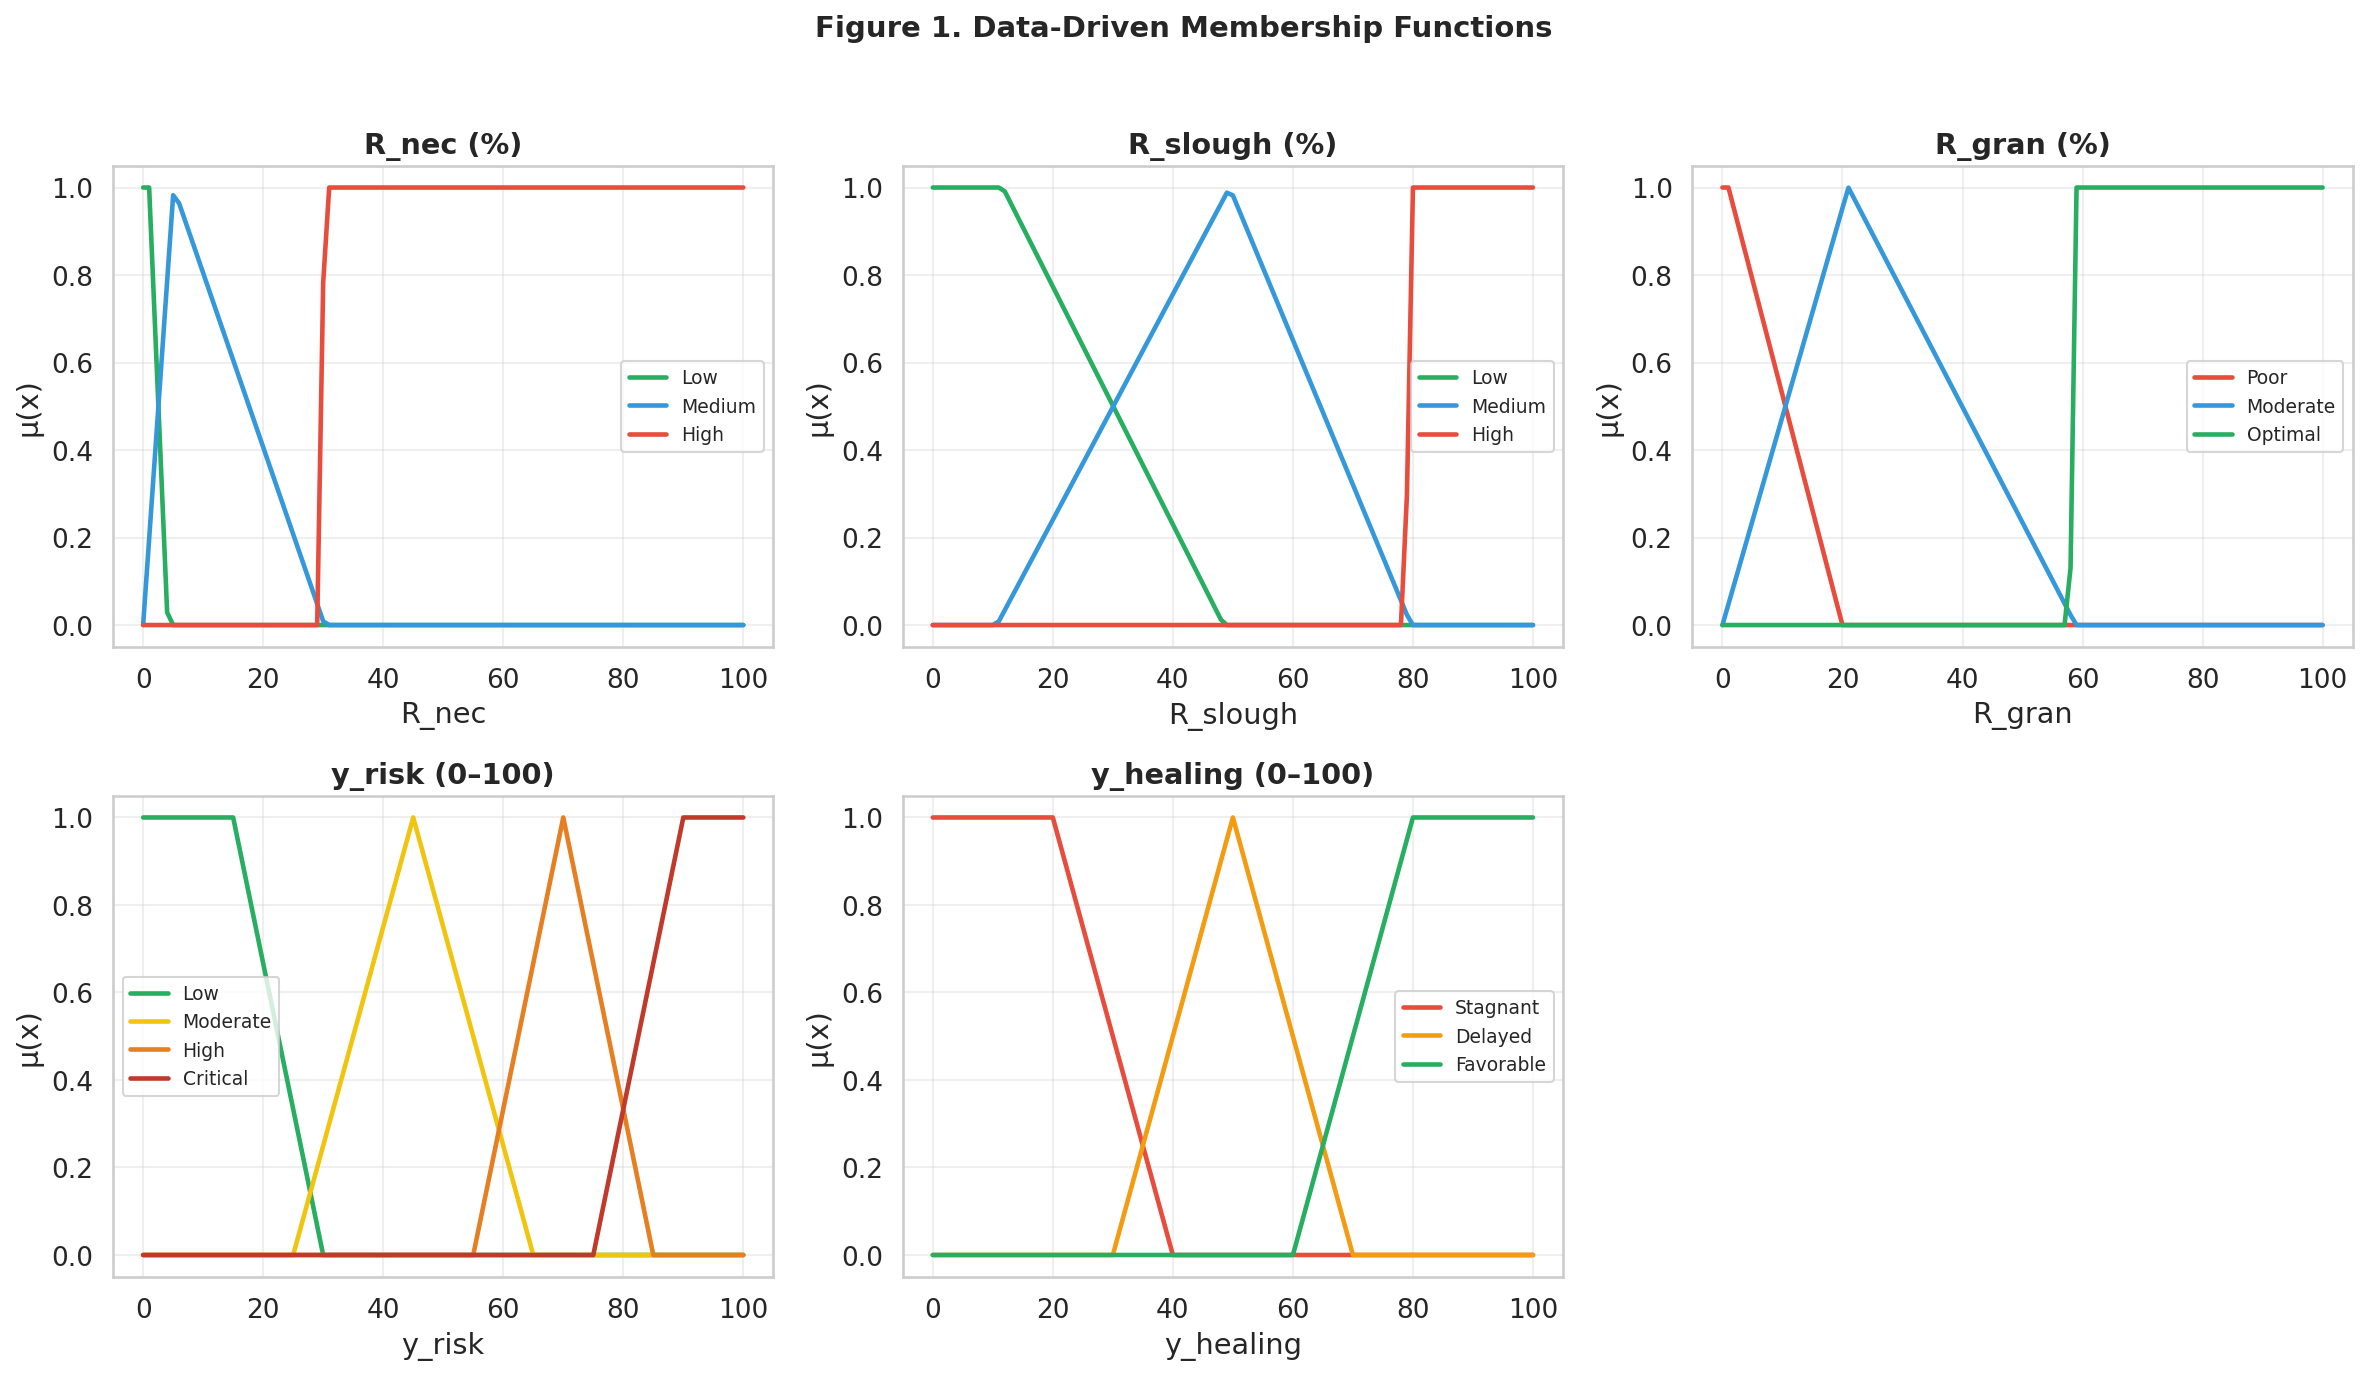

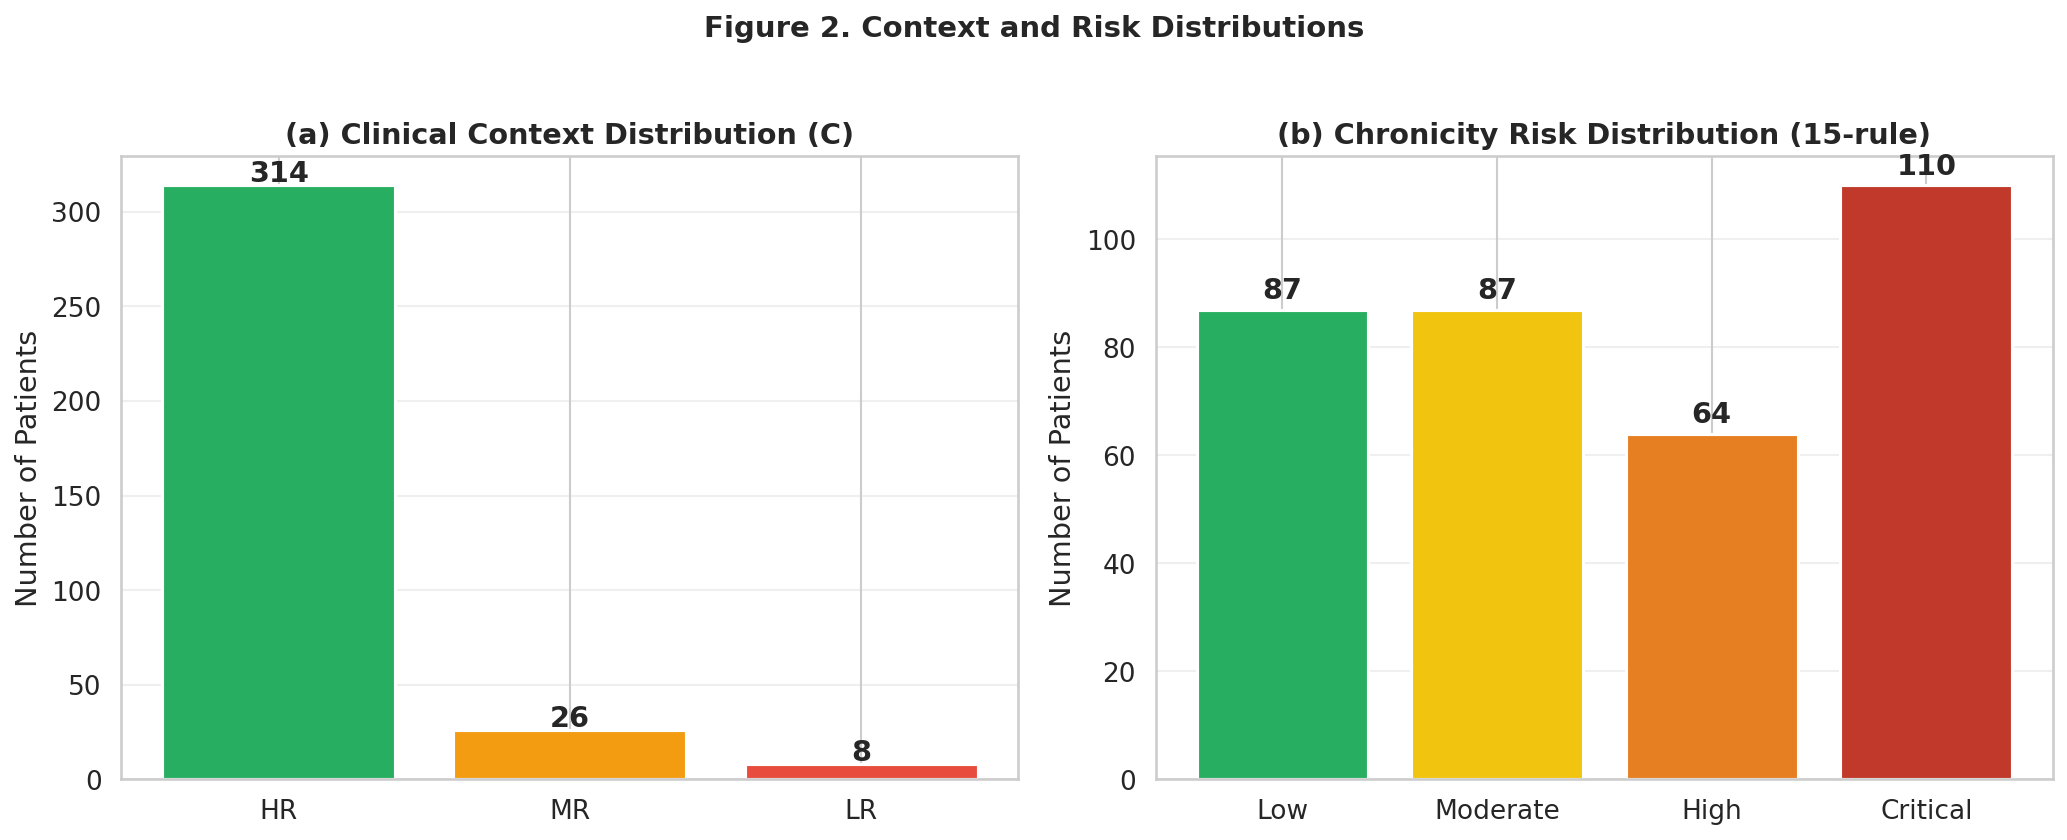

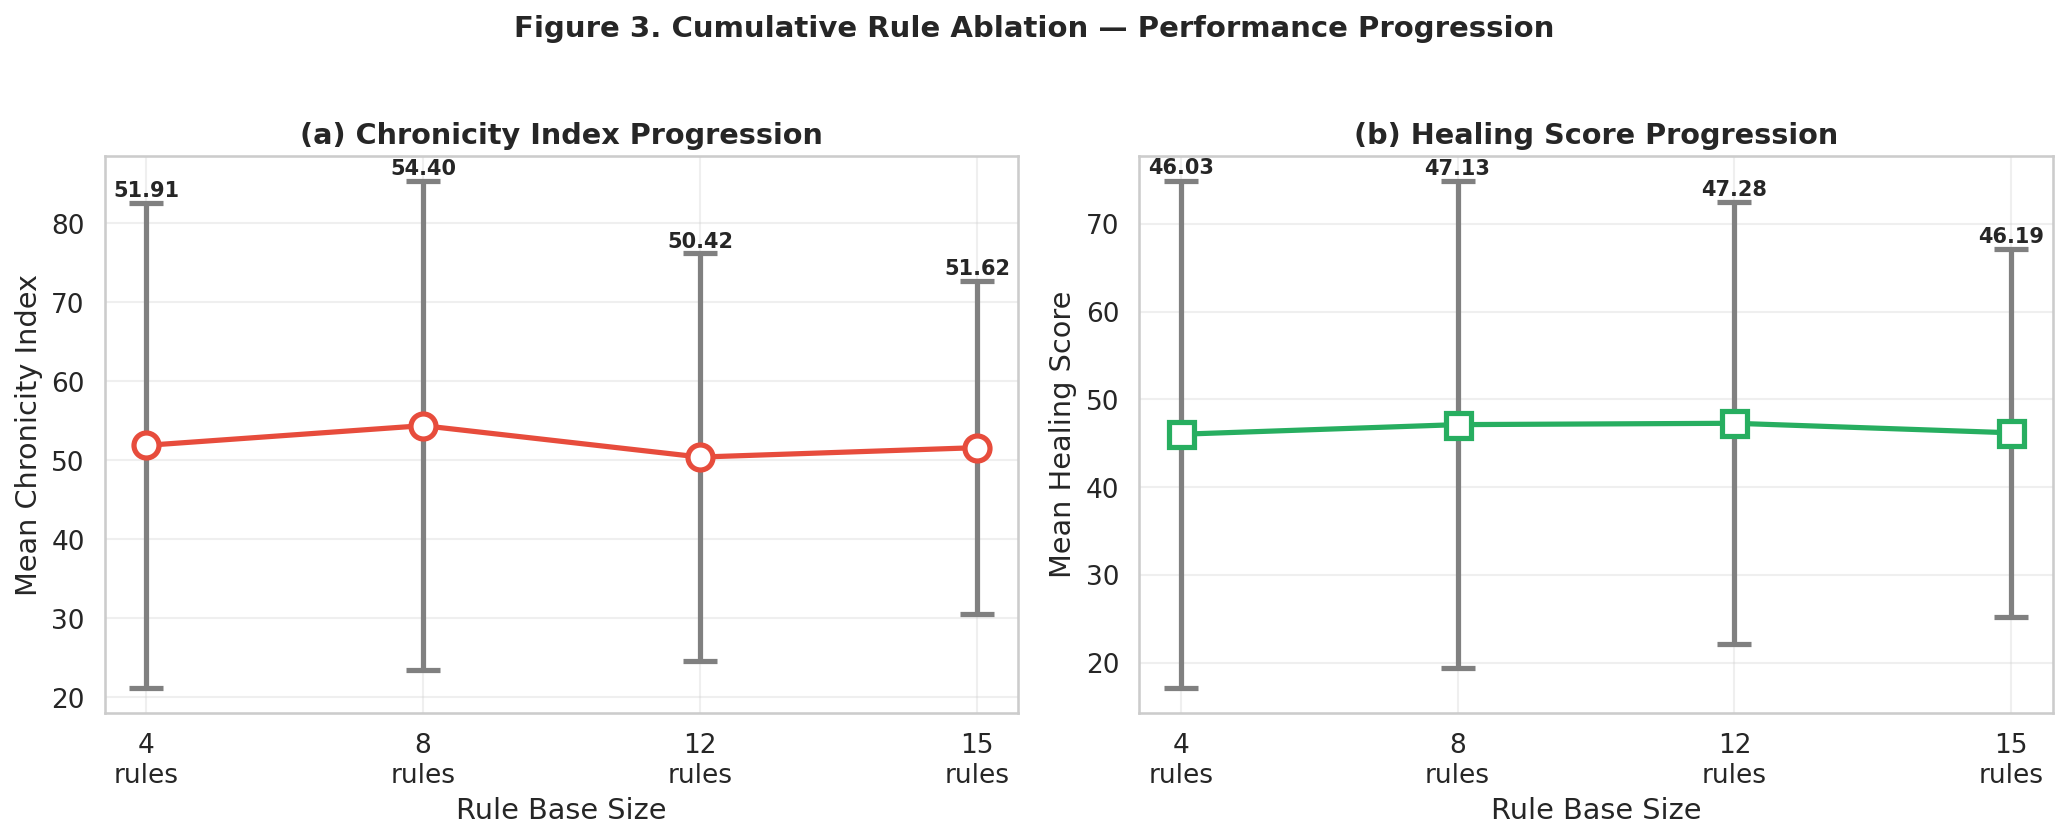

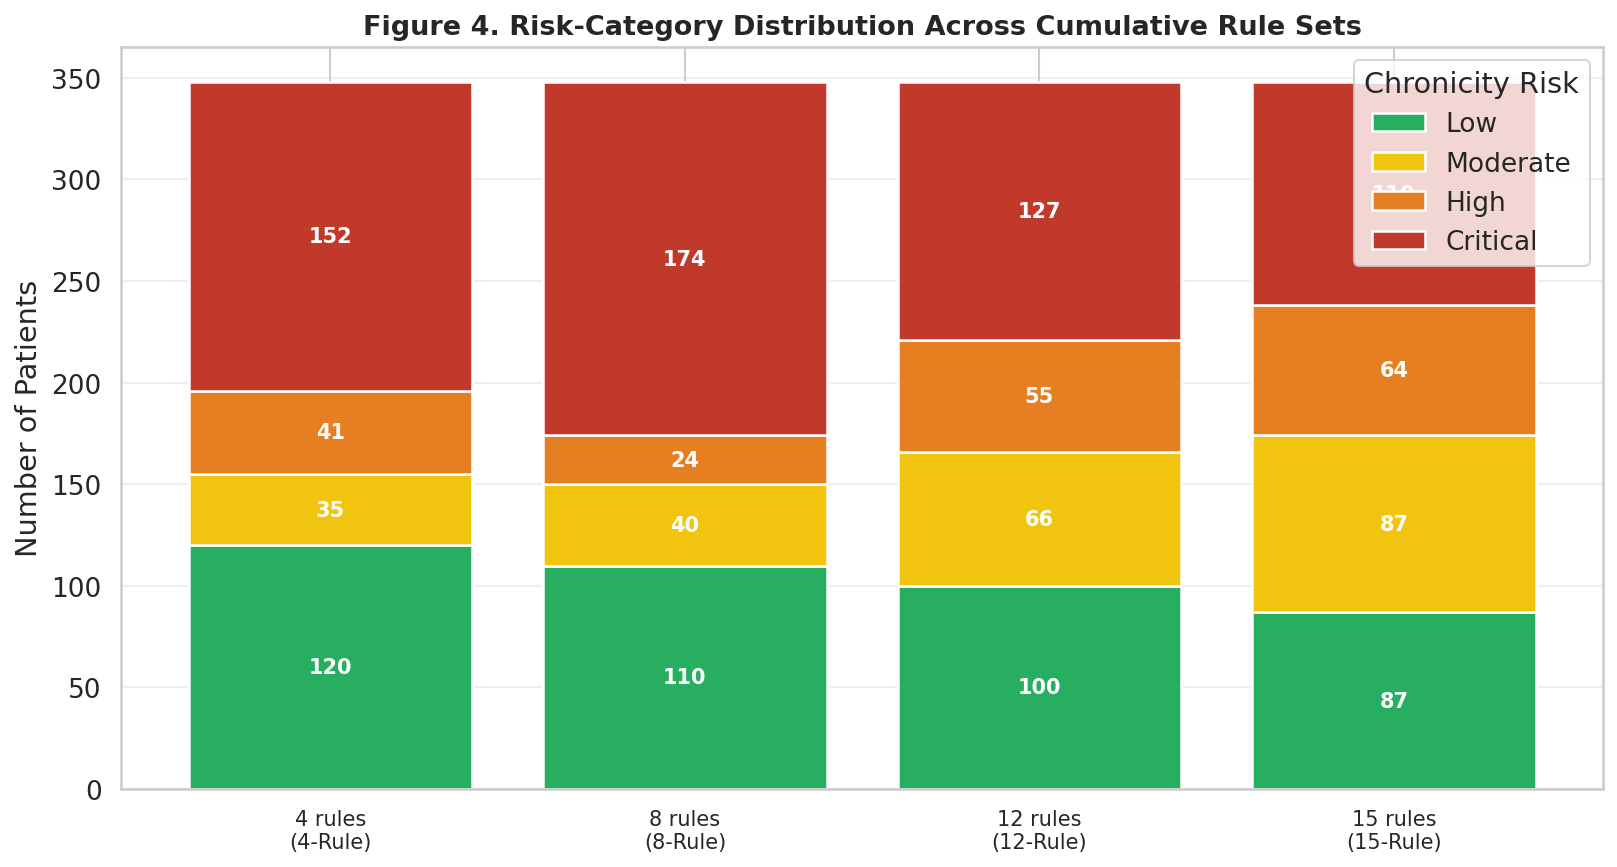

/tmp/ipykernel_4121/882352149.py:612: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True,
/tmp/ipykernel_4121/882352149.py:612: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True,


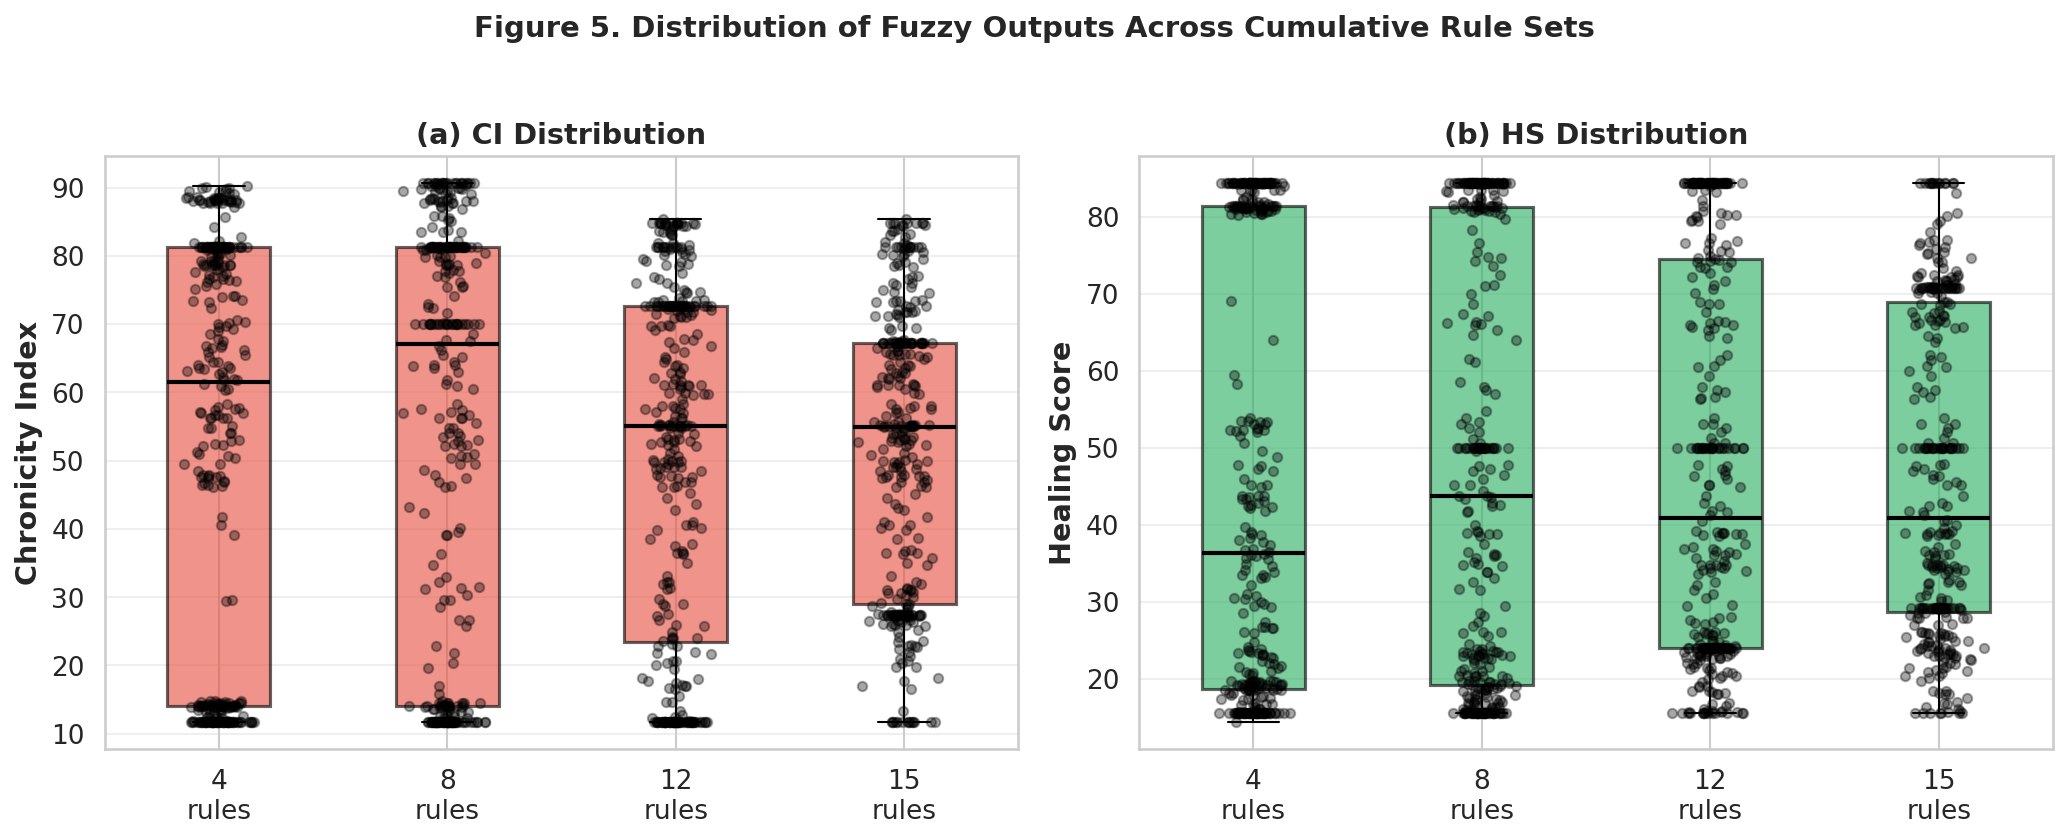

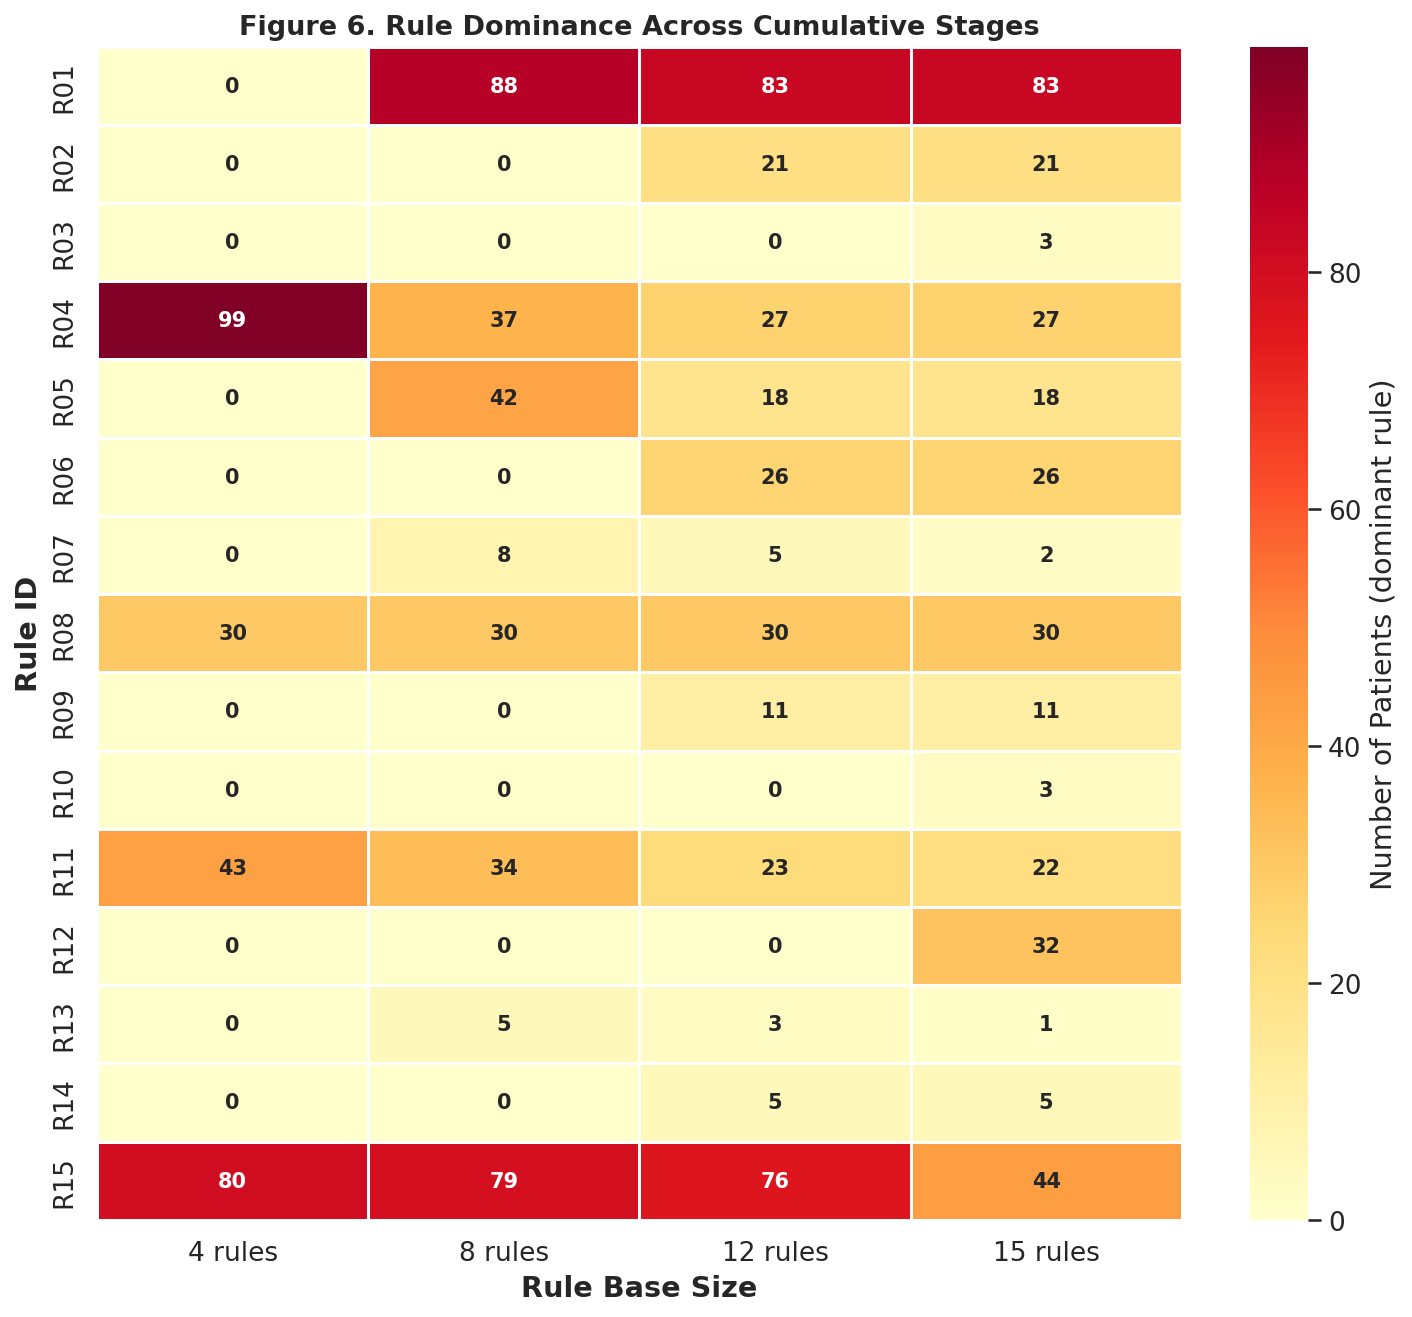

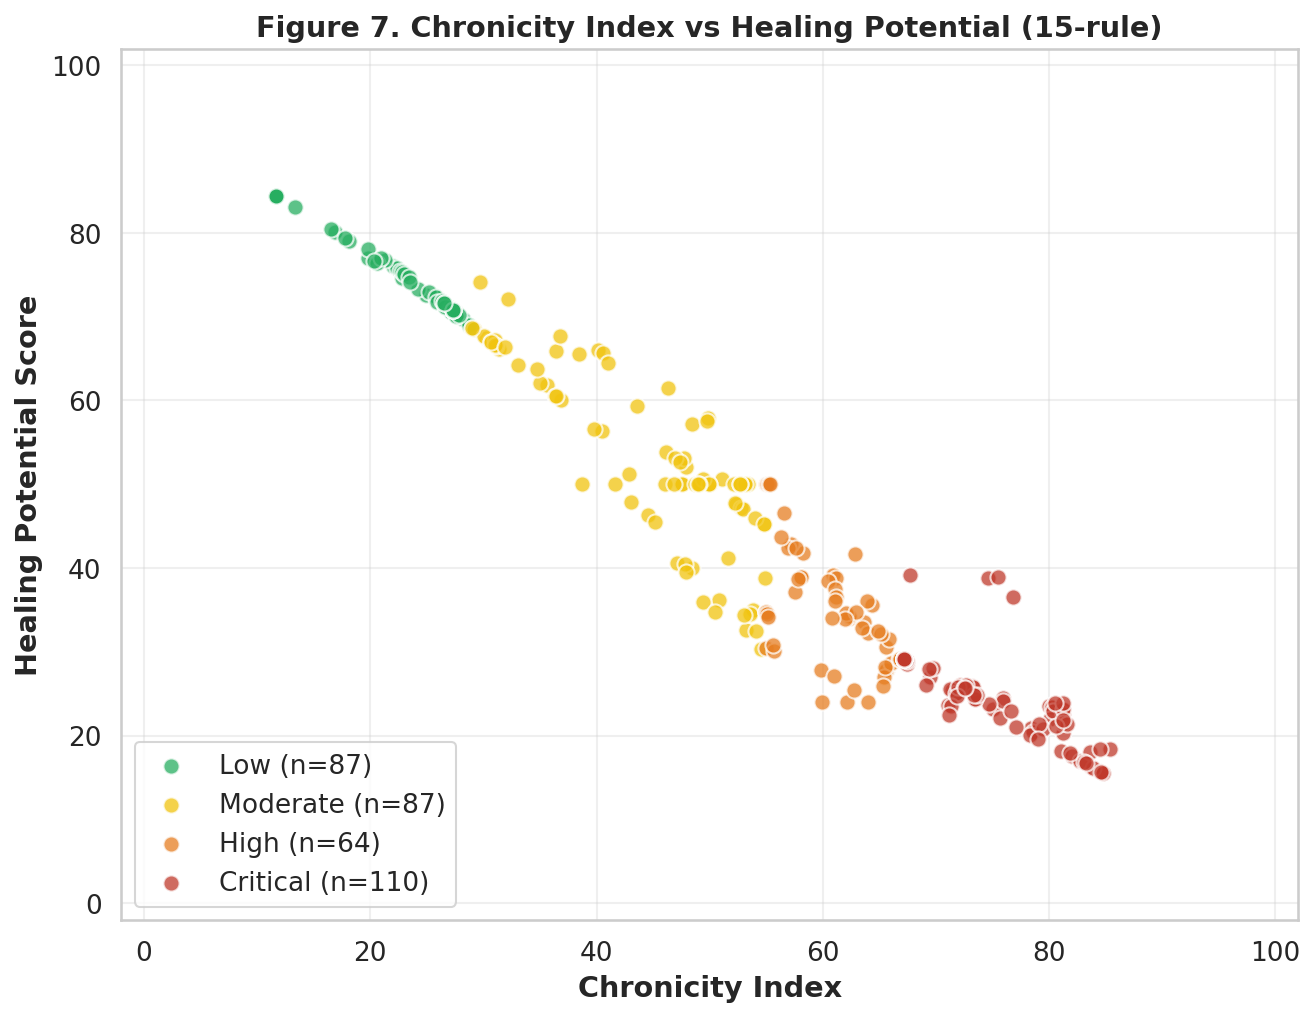

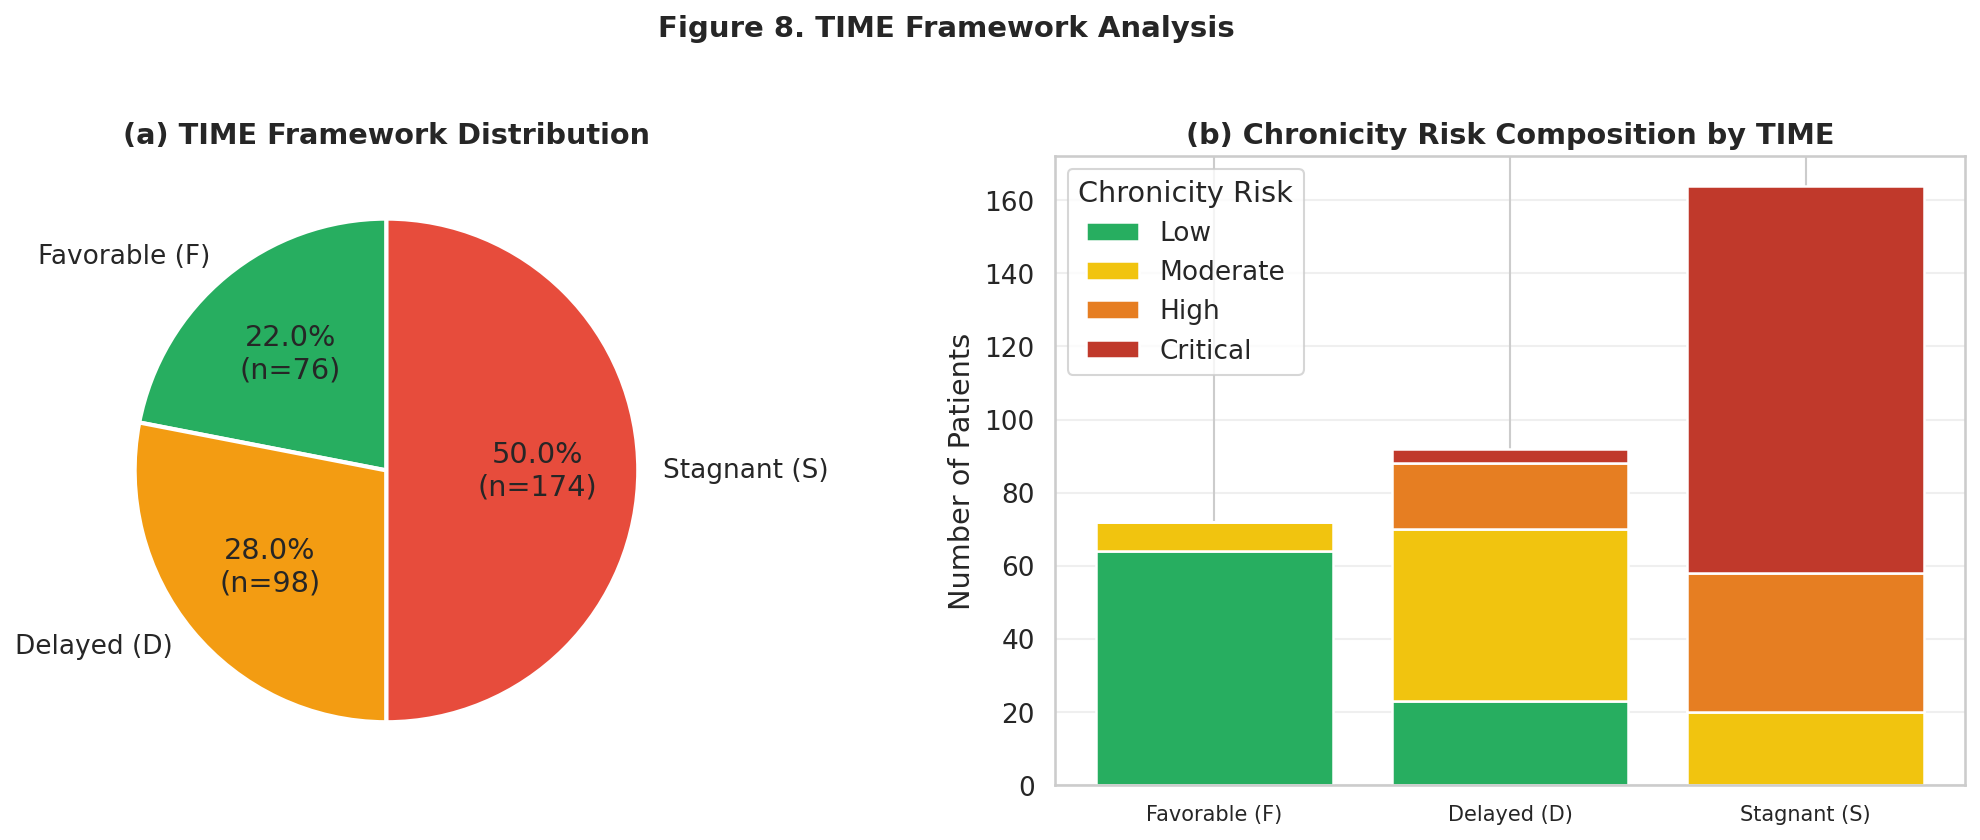


COMPLETE — ALL OUTPUTS SAVED
  /content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/stage8_15_Mamdani_Ablation

Tables:
  Table3_Per_Patient_Results.csv
  Table9_Cumulative_Ablation.csv
  Table10_Category_Shift.csv
  Table11_Rule_Coverage.csv

Figures:
  Fig1_Membership_Functions.png / .pdf
  Fig2_Context_and_Risk.png
  Fig3_Cumulative_Progression.png / .pdf
  Fig4_Category_Distribution.png
  Fig5_Cumulative_Boxplot.png
  Fig6_Rule_Dominance.png
  Fig7_CI_vs_HS.png
  Fig8_TIME_Framework.png



In [17]:
# ================================================================
# PIPELINE 2 — MAMDANI FUZZY ENGINE WITH CUMULATIVE ABLATION
# Cohort: 348 synthetic clinical + WTP tissue cases
# Rule base: R01–R15 (cumulative: 4 → 8 → 12 → 15)
# ================================================================

!pip install -q scikit-fuzzy openpyxl pandas numpy matplotlib seaborn scipy

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import skfuzzy as fuzz
from scipy import stats
from google.colab import drive

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# ---------------- PATHS ----------------
CLINICAL_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/clinical_data_synthetic_matched.xlsx"
if not os.path.exists(CLINICAL_XLSX):
    CLINICAL_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/clinical_data_detailed.xlsx"

OUTPUT_DIR = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/stage8_15_Mamdani_Ablation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.15)
plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300})

print("=" * 80)
print("MAMDANI FUZZY ENGINE — CUMULATIVE ABLATION (4 → 8 → 12 → 15 RULES)")
print("=" * 80)


# =================================================================
# STAGE 8 — DATA LOADING
# =================================================================
print("\n[STAGE 8] Data Loading")

xls = pd.ExcelFile(CLINICAL_XLSX)
clinical = pd.read_excel(xls, sheet_name="Clinical Data")
tissue   = pd.read_excel(xls, sheet_name="Tissue Percentages")

print(f"  Clinical sheet : {clinical.shape}")
print(f"  Tissue sheet   : {tissue.shape}")

# Rename tissue columns
rename_map = {
    "necrosis":          "R_nec",
    "slough":            "R_slough",
    "granulation":       "R_gran",
    "Pred_WTP_Necrosis": "R_nec",
    "Pred_WTP_Slough":   "R_slough",
    "Pred_WTP_Granulation": "R_gran",
}
tissue = tissue.rename(columns={k:v for k,v in rename_map.items() if k in tissue.columns})

# Ensure case_id column exists
if "case_id" not in tissue.columns and "Patient" in tissue.columns:
    tissue = tissue.rename(columns={"Patient": "case_id"})
if "case_id" not in clinical.columns and "patient_id" in clinical.columns:
    clinical["case_id"] = "case_" + clinical["patient_id"].astype(str)

# Merge
df = pd.merge(clinical, tissue[["case_id", "R_nec", "R_slough", "R_gran"]],
              on="case_id", how="inner")

print(f"  Merged: {len(df)} patients")

if len(df) == 0:
    raise ValueError("No patients matched — check case_id formats")

df["healing_rate"] = ((50.0 - df["healing_progress"]) / 50.0).clip(-1, 1)


# =================================================================
# STAGE 9 — CLINICAL CONTEXT
# =================================================================
print("\n[STAGE 9] Clinical Context")

def compute_clinical_context(row):
    hba1c     = row.get("hba1c", 6.0)
    infection = row.get("infection_status", 1)
    vascular  = row.get("vascular_status", 2)
    duration  = row.get("diabetes_duration", 0)
    age       = row.get("age", 50)

    if (hba1c >= 8.0) or (infection >= 2) or (vascular <= 1):
        return "HR"
    if (hba1c >= 6.5) or (duration >= 10) or (age >= 65):
        return "MR"
    return "LR"

df["clinical_context"] = df.apply(compute_clinical_context, axis=1)

print(f"  Context distribution:")
print(df["clinical_context"].value_counts().to_string())

print(f"\n  Tissue diagnostics:")
for col in ["R_nec", "R_slough", "R_gran"]:
    print(f"    {col:10s}: min={df[col].min():6.2f}  max={df[col].max():6.2f}  "
          f"mean={df[col].mean():6.2f}  std={df[col].std():6.2f}")


# =================================================================
# STAGE 10 — MEMBERSHIP FUNCTIONS (data-driven)
# =================================================================
print("\n[STAGE 10] MF Calibration")

x_nec    = np.arange(0, 101, 1)
x_slough = np.arange(0, 101, 1)
x_gran   = np.arange(0, 101, 1)
x_risk   = np.arange(0, 101, 1)
x_heal   = np.arange(0, 101, 1)

def pct(arr, p): return float(np.percentile(arr, p))

nec_p20, nec_p50, nec_p80 = pct(df["R_nec"],    20), pct(df["R_nec"],    50), pct(df["R_nec"],    80)
slo_p20, slo_p50, slo_p80 = pct(df["R_slough"], 20), pct(df["R_slough"], 50), pct(df["R_slough"], 80)
gra_p20, gra_p50, gra_p80 = pct(df["R_gran"],   20), pct(df["R_gran"],   50), pct(df["R_gran"],   80)

nec_p20 = max(nec_p20, 1.0); nec_p80 = max(nec_p80, nec_p50 + 1.0)
slo_p20 = max(slo_p20, 1.0); slo_p80 = max(slo_p80, slo_p50 + 1.0)
gra_p20 = max(gra_p20, 1.0); gra_p80 = max(gra_p80, gra_p50 + 1.0)

nec_L = fuzz.trapmf(x_nec, [0, 0, nec_p20, max(nec_p50 - 1, nec_p20 + 1)])
nec_M = fuzz.trimf(x_nec,  [max(nec_p20 - 1, 0), nec_p50, max(nec_p80, nec_p50 + 1)])
nec_H = fuzz.trapmf(x_nec, [max(nec_p80 - 1, nec_p50), nec_p80, 100, 100])

slo_L = fuzz.trapmf(x_slough, [0, 0, slo_p20, max(slo_p50 - 1, slo_p20 + 1)])
slo_M = fuzz.trimf(x_slough,  [max(slo_p20 - 1, 0), slo_p50, max(slo_p80, slo_p50 + 1)])
slo_H = fuzz.trapmf(x_slough, [max(slo_p80 - 1, slo_p50), slo_p80, 100, 100])

gran_P = fuzz.trapmf(x_gran, [0, 0, gra_p20, max(gra_p50 - 1, gra_p20 + 1)])
gran_M = fuzz.trimf(x_gran,  [max(gra_p20 - 1, 0), gra_p50, max(gra_p80, gra_p50 + 1)])
gran_O = fuzz.trapmf(x_gran, [max(gra_p80 - 1, gra_p50), gra_p80, 100, 100])

risk_L = fuzz.trapmf(x_risk, [0, 0, 15, 30])
risk_M = fuzz.trimf(x_risk,  [25, 45, 65])
risk_H = fuzz.trimf(x_risk,  [55, 70, 85])
risk_C = fuzz.trapmf(x_risk, [75, 90, 100, 100])

heal_S = fuzz.trapmf(x_heal, [0, 0, 20, 40])
heal_D = fuzz.trimf(x_heal,  [30, 50, 70])
heal_F = fuzz.trapmf(x_heal, [60, 80, 100, 100])

def fuzzify_inputs(nec, slo, gra):
    return {
        "R_nec": {
            "L": float(fuzz.interp_membership(x_nec, nec_L, nec)),
            "M": float(fuzz.interp_membership(x_nec, nec_M, nec)),
            "H": float(fuzz.interp_membership(x_nec, nec_H, nec)),
        },
        "R_slough": {
            "L": float(fuzz.interp_membership(x_slough, slo_L, slo)),
            "M": float(fuzz.interp_membership(x_slough, slo_M, slo)),
            "H": float(fuzz.interp_membership(x_slough, slo_H, slo)),
        },
        "R_gran": {
            "P": float(fuzz.interp_membership(x_gran, gran_P, gra)),
            "M": float(fuzz.interp_membership(x_gran, gran_M, gra)),
            "O": float(fuzz.interp_membership(x_gran, gran_O, gra)),
        },
    }


# =================================================================
# STAGE 11 — RULE BASE
# =================================================================
RULES = [
    ("R01", "H", "H", "P", "HR", "C", "S", "Stagnant (S)"),
    ("R02", "H", "M", "P", "MR", "H", "S", "Stagnant (S)"),
    ("R03", "H", "L", "P", "LR", "H", "S", "Stagnant (S)"),
    ("R04", "M", "H", "P", "HR", "C", "S", "Stagnant (S)"),
    ("R05", "M", "H", "M", "MR", "H", "D", "Delayed (D)"),
    ("R06", "M", "M", "M", "MR", "M", "D", "Delayed (D)"),
    ("R07", "M", "L", "M", "LR", "M", "D", "Delayed (D)"),
    ("R08", "L", "H", "P", "HR", "H", "S", "Stagnant (S)"),
    ("R09", "L", "H", "M", "MR", "M", "D", "Delayed (D)"),
    ("R10", "L", "M", "M", "LR", "M", "D", "Delayed (D)"),
    ("R11", "L", "M", "O", "MR", "L", "F", "Favorable (F)"),
    ("R12", "L", "L", "P", "HR", "M", "D", "Delayed (D)"),
    ("R13", "L", "L", "M", "LR", "L", "F", "Favorable (F)"),
    ("R14", "L", "L", "O", "LR", "L", "F", "Favorable (F)"),
    ("R15", "L", "L", "O", "HR", "L", "F", "Favorable (F)"),
]

# Rule sets for cumulative ablation
STAGE_RULE_SETS = {
    "4-Rule (Core)":  ["R04", "R08", "R11", "R15"],
    "8-Rule":         ["R04", "R08", "R11", "R15",
                       "R01", "R05", "R07", "R13"],
    "12-Rule":        ["R04", "R08", "R11", "R15",
                       "R01", "R05", "R07", "R13",
                       "R02", "R06", "R09", "R14"],
    "15-Rule (Full)": [r[0] for r in RULES],
}

print("\n[STAGE 11] Rule Sets for Cumulative Ablation:")
for stage, ids in STAGE_RULE_SETS.items():
    print(f"  {stage:15s} ({len(ids):2d}): {ids}")


def context_weight(ctx_label, rule_ctx):
    order = {"LR": 0, "MR": 1, "HR": 2}
    d = abs(order[ctx_label] - order[rule_ctx])
    return {0: 1.0, 1: 0.3, 2: 0.0}[d]


def fire_rules(fuzzy_inputs, context_label, active_rule_ids):
    """2-out-of-3 tissue matching + soft context gating."""
    fired = []
    for r in RULES:
        if r[0] not in active_rule_ids:
            continue
        rid, nt, st, gt, ct, rt, ht, tm = r
        m_nec  = fuzzy_inputs["R_nec"][nt]
        m_slo  = fuzzy_inputs["R_slough"][st]
        m_gran = fuzzy_inputs["R_gran"][gt]
        tissue_strength = sorted([m_nec, m_slo, m_gran], reverse=True)[1]
        w = context_weight(context_label, ct)
        fired.append({
            "rule_id": rid, "strength": float(tissue_strength * w),
            "risk_term": rt, "heal_term": ht, "time_label": tm,
        })
    return fired


def defuzzify(fired, row=None):
    agg_r = np.zeros_like(x_risk)
    agg_h = np.zeros_like(x_heal)
    rmap = {"L": risk_L, "M": risk_M, "H": risk_H, "C": risk_C}
    hmap = {"S": heal_S, "D": heal_D, "F": heal_F}

    any_fired = False
    for m in fired:
        if m["strength"] <= 0: continue
        any_fired = True
        agg_r = np.fmax(agg_r, np.fmin(m["strength"], rmap[m["risk_term"]]))
        agg_h = np.fmax(agg_h, np.fmin(m["strength"], hmap[m["heal_term"]]))

    if any_fired:
        try: r = float(fuzz.defuzz(x_risk, agg_r, "centroid"))
        except Exception: r = 50.0
        try: h = float(fuzz.defuzz(x_heal, agg_h, "centroid"))
        except Exception: h = 50.0
        return r, h

    if row is not None:
        heuristic_ci = np.clip(
            0.5 * row["R_nec"] + 0.3 * row["R_slough"]
            - 0.2 * row["R_gran"] + 40, 0, 100
        )
        return float(heuristic_ci), float(100 - heuristic_ci)
    return 50.0, 50.0


RISK_THRESHOLDS = (30, 50, 75)

def risk_label_from_value(v, thresholds=None):
    t1, t2, t3 = thresholds if thresholds is not None else RISK_THRESHOLDS
    if v < t1: return "Low"
    if v < t2: return "Moderate"
    if v < t3: return "High"
    return "Critical"

def heal_label_from_value(v):
    if v < 35:  return "Stagnant"
    if v < 60:  return "Delayed"
    return "Favorable"


# =================================================================
# STAGE 12 — INFERENCE DRIVER
# =================================================================
def run_inference(df_input, active_rule_ids, thresholds=None):
    risk_vals, heal_vals, risk_labs, heal_labs = [], [], [], []
    dominant_rules, time_labels, fallback_flags = [], [], []

    for _, row in df_input.iterrows():
        fi = fuzzify_inputs(row["R_nec"], row["R_slough"], row["R_gran"])
        fired = fire_rules(fi, row["clinical_context"], active_rule_ids)
        r, h = defuzzify(fired, row=row)
        risk_vals.append(r); heal_vals.append(h)
        risk_labs.append(risk_label_from_value(r, thresholds))
        heal_labs.append(heal_label_from_value(h))

        fired_nz = [m for m in fired if m["strength"] > 0]
        if fired_nz:
            dom = max(fired_nz, key=lambda m: m["strength"])
            dominant_rules.append(dom["rule_id"])
            time_labels.append(dom["time_label"])
            fallback_flags.append(False)
        else:
            dominant_rules.append("—")
            time_labels.append("—")
            fallback_flags.append(True)

    return pd.DataFrame({
        "case_id":          df_input["case_id"].values,
        "chronicity_index": risk_vals,
        "healing_score":    heal_vals,
        "chronicity_label": risk_labs,
        "healing_label":    heal_labs,
        "dominant_rule":    dominant_rules,
        "TIME_label":       time_labels,
        "fallback_used":    fallback_flags,
    })


# ---- First pass to calibrate thresholds ----
print("\n[STAGE 12] Running full inference for threshold calibration ...")
full_pass = run_inference(df, [r[0] for r in RULES])
p25, p50, p75 = np.percentile(full_pass["chronicity_index"], [25, 50, 75])
RISK_THRESHOLDS = (float(p25), float(p50), float(p75))
print(f"  Adaptive thresholds (p25, p50, p75): "
      f"({RISK_THRESHOLDS[0]:.2f}, {RISK_THRESHOLDS[1]:.2f}, {RISK_THRESHOLDS[2]:.2f})")


# ---- Run cumulative ablation ----
print("\n[STAGE 13] Cumulative Rule Ablation")
print("=" * 100)

stage_results = {}
stage_order = list(STAGE_RULE_SETS.keys())

for stage, rule_ids in STAGE_RULE_SETS.items():
    res = run_inference(df, rule_ids, thresholds=RISK_THRESHOLDS)
    stage_results[stage] = res

    n_fb = res["fallback_used"].sum()
    n_low = (res["chronicity_label"] == "Low").sum()
    n_mod = (res["chronicity_label"] == "Moderate").sum()
    n_hi  = (res["chronicity_label"] == "High").sum()
    n_cr  = (res["chronicity_label"] == "Critical").sum()

    print(f"\n{stage}  ({len(rule_ids)} rules)")
    print(f"  Mean CI   : {res['chronicity_index'].mean():.3f}")
    print(f"  Std CI    : {res['chronicity_index'].std():.3f}")
    print(f"  Mean HS   : {res['healing_score'].mean():.3f}")
    print(f"  Categories: Low={n_low}  Mod={n_mod}  High={n_hi}  Crit={n_cr}")
    print(f"  Fallback  : {n_fb} / {len(df)}")
    print(f"  Dominant  : {res['dominant_rule'].value_counts().head(5).to_dict()}")

print("\n" + "=" * 100)


# =================================================================
# STAGE 14 — STATISTICAL COMPARISON
# =================================================================
print("\n[STAGE 14] Statistical Comparison")

stats_rows = []
for i, stage in enumerate(stage_order):
    res = stage_results[stage]
    ci = res["chronicity_index"].values
    hs = res["healing_score"].values

    if i == 0:
        stats_rows.append({
            "Configuration": stage,
            "N rules": len(STAGE_RULE_SETS[stage]),
            "Mean CI": f"{ci.mean():.3f}",
            "Std CI":  f"{ci.std():.3f}",
            "Mean HS": f"{hs.mean():.3f}",
            "Δ CI vs prev": "—",
            "Wilcoxon p": "—",
            "Significance": "—",
            "Patients shifted": "—",
        })
        continue

    prev = stage_results[stage_order[i-1]]
    prev_ci = prev["chronicity_index"].values
    prev_labs = prev["chronicity_label"].values
    curr_labs = res["chronicity_label"].values

    delta = ci.mean() - prev_ci.mean()
    try: _, w_p = stats.wilcoxon(prev_ci, ci)
    except Exception: w_p = np.nan
    shifted = int((curr_labs != prev_labs).sum())

    sig = ("***" if (not np.isnan(w_p) and w_p < 0.001) else
           "**"  if (not np.isnan(w_p) and w_p < 0.01)  else
           "*"   if (not np.isnan(w_p) and w_p < 0.05)  else "ns")

    stats_rows.append({
        "Configuration": stage,
        "N rules": len(STAGE_RULE_SETS[stage]),
        "Mean CI": f"{ci.mean():.3f}",
        "Std CI":  f"{ci.std():.3f}",
        "Mean HS": f"{hs.mean():.3f}",
        "Δ CI vs prev": f"{delta:+.3f}",
        "Wilcoxon p": f"{w_p:.4f}" if not np.isnan(w_p) else "—",
        "Significance": sig,
        "Patients shifted": shifted,
    })

stats_table = pd.DataFrame(stats_rows)
stats_table.to_csv(os.path.join(OUTPUT_DIR, "Table9_Cumulative_Ablation.csv"), index=False)

print("\n" + "=" * 120)
print("TABLE 9 — Cumulative Rule Ablation (4 → 8 → 12 → 15 rules)")
print("=" * 120)
print(stats_table.to_string(index=False))
print("=" * 120)
print("Significance: *** p<0.001, ** p<0.01, * p<0.05, ns = not significant")


# =================================================================
# STAGE 15 — PER-CATEGORY DISTRIBUTION
# =================================================================
risk_order = ["Low", "Moderate", "High", "Critical"]

cat_rows = []
for stage in stage_order:
    res = stage_results[stage]
    row = {"Configuration": stage, "N rules": len(STAGE_RULE_SETS[stage])}
    for cat in risk_order:
        row[cat] = int((res["chronicity_label"] == cat).sum())
    cat_rows.append(row)
cat_table = pd.DataFrame(cat_rows)
cat_table.to_csv(os.path.join(OUTPUT_DIR, "Table10_Category_Shift.csv"), index=False)

print("\n" + "=" * 100)
print("TABLE 10 — Risk Category Distribution Across Cumulative Rule Sets")
print("=" * 100)
print(cat_table.to_string(index=False))


# =================================================================
# STAGE 16 — RULE COVERAGE
# =================================================================
coverage_rows = []
for stage in stage_order:
    res = stage_results[stage]
    active = STAGE_RULE_SETS[stage]
    n_dom = sum(1 for rid in active if (res["dominant_rule"] == rid).sum() > 0)
    coverage_rows.append({
        "Configuration": stage,
        "Total rules": len(active),
        "Rules dominant ≥1": n_dom,
        "Coverage (%)": f"{100 * n_dom / len(active):.1f}%",
    })
coverage_df = pd.DataFrame(coverage_rows)
coverage_df.to_csv(os.path.join(OUTPUT_DIR, "Table11_Rule_Coverage.csv"), index=False)

print("\n" + "=" * 90)
print("TABLE 11 — Rule Activation Coverage")
print("=" * 90)
print(coverage_df.to_string(index=False))


# =================================================================
# STAGE 17 — PER-PATIENT RESULTS (using the FULL 15-rule base)
# =================================================================
print("\n[STAGE 17] Saving per-patient results (15-rule base) ...")

final_df = df.copy()
final_df["chronicity_index"] = stage_results["15-Rule (Full)"]["chronicity_index"].values
final_df["healing_score"]    = stage_results["15-Rule (Full)"]["healing_score"].values
final_df["chronicity_label"] = stage_results["15-Rule (Full)"]["chronicity_label"].values
final_df["healing_label"]    = stage_results["15-Rule (Full)"]["healing_label"].values
final_df["dominant_rule"]    = stage_results["15-Rule (Full)"]["dominant_rule"].values
final_df["TIME_label"]       = stage_results["15-Rule (Full)"]["TIME_label"].values
final_df["fallback_used"]    = stage_results["15-Rule (Full)"]["fallback_used"].values

final_df[["case_id", "R_nec", "R_slough", "R_gran", "clinical_context",
          "age", "healing_progress", "chronicity_index", "healing_score",
          "chronicity_label", "healing_label", "TIME_label",
          "dominant_rule", "fallback_used"]].round(3).to_csv(
    os.path.join(OUTPUT_DIR, "Table3_Per_Patient_Results.csv"), index=False)


# =================================================================
# STAGE 18 — VISUALIZATIONS
# =================================================================
print("\n[STAGE 18] Generating Figures")

COLOR_RISK = {"Low": "#27AE60", "Moderate": "#F1C40F",
              "High": "#E67E22", "Critical": "#C0392B"}
COLOR_HEAL = {"Favorable": "#27AE60", "Delayed": "#F39C12", "Stagnant": "#E74C3C"}


# ---------- FIG 1: Membership Functions ----------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
mfs = [
    (axes[0,0], x_nec,    [(nec_L,"Low","#27AE60"), (nec_M,"Medium","#3498DB"), (nec_H,"High","#E74C3C")], "R_nec (%)"),
    (axes[0,1], x_slough, [(slo_L,"Low","#27AE60"), (slo_M,"Medium","#3498DB"), (slo_H,"High","#E74C3C")], "R_slough (%)"),
    (axes[0,2], x_gran,   [(gran_P,"Poor","#E74C3C"), (gran_M,"Moderate","#3498DB"), (gran_O,"Optimal","#27AE60")], "R_gran (%)"),
    (axes[1,0], x_risk,   [(risk_L,"Low","#27AE60"), (risk_M,"Moderate","#F1C40F"),
                            (risk_H,"High","#E67E22"), (risk_C,"Critical","#C0392B")], "y_risk (0–100)"),
    (axes[1,1], x_heal,   [(heal_S,"Stagnant","#E74C3C"), (heal_D,"Delayed","#F39C12"),
                            (heal_F,"Favorable","#27AE60")], "y_healing (0–100)"),
]
for ax, x, series, title in mfs:
    for arr, name, col in series:
        ax.plot(x, arr, color=col, lw=2.2, label=name)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(title.split(' ')[0]); ax.set_ylabel("μ(x)")
    ax.set_ylim(-0.05, 1.05); ax.legend(fontsize=9); ax.grid(alpha=0.3)
axes[1,2].axis('off')
plt.suptitle("Figure 1. Data-Driven Membership Functions", fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig1_Membership_Functions.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(OUTPUT_DIR, "Fig1_Membership_Functions.pdf"), bbox_inches='tight', facecolor='white')
plt.show()


# ---------- FIG 2: Output Distributions ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
rc = df["clinical_context"].value_counts()
axes[0].bar(rc.index, rc.values, color=['#27AE60','#F39C12','#E74C3C'],
            edgecolor='white', linewidth=1.5)
for i, v in enumerate(rc.values):
    axes[0].text(i, v + 2, str(v), ha='center', fontweight='bold')
axes[0].set_ylabel("Number of Patients")
axes[0].set_title("(a) Clinical Context Distribution (C)", fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')

risk_full = final_df["chronicity_label"].value_counts().reindex(risk_order).fillna(0)
bars = axes[1].bar(risk_order, risk_full, color=[COLOR_RISK[r] for r in risk_order],
                   edgecolor='white', linewidth=1.5)
for b, c in zip(bars, risk_full):
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+2, int(c),
                 ha='center', fontweight='bold')
axes[1].set_ylabel("Number of Patients")
axes[1].set_title("(b) Chronicity Risk Distribution (15-rule)", fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')
plt.suptitle("Figure 2. Context and Risk Distributions", fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig2_Context_and_Risk.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


# ---------- FIG 3: Cumulative Progression (CI and HS) ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
x = np.arange(len(stage_order))
ci_means = [stage_results[s]["chronicity_index"].mean() for s in stage_order]
ci_stds  = [stage_results[s]["chronicity_index"].std()  for s in stage_order]
hs_means = [stage_results[s]["healing_score"].mean()    for s in stage_order]
hs_stds  = [stage_results[s]["healing_score"].std()     for s in stage_order]

ax = axes[0]
ax.errorbar(x, ci_means, yerr=ci_stds, marker='o', markersize=12,
            linewidth=2.5, capsize=8, color='#E74C3C',
            ecolor='gray', markerfacecolor='white', markeredgewidth=2.5)
for xi, m, sd in zip(x, ci_means, ci_stds):
    ax.text(xi, m + sd + 0.8, f"{m:.2f}", ha='center', fontweight='bold', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels([f"{len(STAGE_RULE_SETS[s])}\nrules" for s in stage_order])
ax.set_xlabel("Rule Base Size"); ax.set_ylabel("Mean Chronicity Index")
ax.set_title("(a) Chronicity Index Progression", fontweight='bold'); ax.grid(alpha=0.3)

ax = axes[1]
ax.errorbar(x, hs_means, yerr=hs_stds, marker='s', markersize=12,
            linewidth=2.5, capsize=8, color='#27AE60',
            ecolor='gray', markerfacecolor='white', markeredgewidth=2.5)
for xi, m, sd in zip(x, hs_means, hs_stds):
    ax.text(xi, m + sd + 0.8, f"{m:.2f}", ha='center', fontweight='bold', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels([f"{len(STAGE_RULE_SETS[s])}\nrules" for s in stage_order])
ax.set_xlabel("Rule Base Size"); ax.set_ylabel("Mean Healing Score")
ax.set_title("(b) Healing Score Progression", fontweight='bold'); ax.grid(alpha=0.3)

plt.suptitle("Figure 3. Cumulative Rule Ablation — Performance Progression",
             fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig3_Cumulative_Progression.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(OUTPUT_DIR, "Fig3_Cumulative_Progression.pdf"), bbox_inches='tight', facecolor='white')
plt.show()


# ---------- FIG 4: Category Distribution Stacked Bars ----------
fig, ax = plt.subplots(figsize=(11, 6))
cat_plot = cat_table.set_index("Configuration").reindex(stage_order)
bottom = np.zeros(len(cat_plot))
x = np.arange(len(cat_plot))
for cat in risk_order:
    vals = cat_plot[cat].values
    ax.bar(x, vals, bottom=bottom, color=COLOR_RISK[cat],
           label=cat, edgecolor='white', linewidth=1.2)
    for xi, (b, v) in enumerate(zip(bottom, vals)):
        if v > 5:
            ax.text(xi, b + v/2, str(int(v)), ha='center', va='center',
                    color='white', fontweight='bold', fontsize=10)
    bottom += vals
ax.set_xticks(x)
ax.set_xticklabels([f"{len(STAGE_RULE_SETS[s])} rules\n({s.split('(')[0].strip()})"
                    for s in stage_order], fontsize=10)
ax.set_ylabel("Number of Patients")
ax.set_title("Figure 4. Risk-Category Distribution Across Cumulative Rule Sets",
             fontweight='bold', fontsize=13)
ax.legend(title="Chronicity Risk", loc='upper right'); ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig4_Category_Distribution.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


# ---------- FIG 5: Boxplot of CI/HS per stage ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
data_ci = [stage_results[s]["chronicity_index"].values for s in stage_order]
data_hs = [stage_results[s]["healing_score"].values    for s in stage_order]
labels  = [f"{len(STAGE_RULE_SETS[s])}\nrules" for s in stage_order]

for ax, data, color, ylabel, title in [
    (axes[0], data_ci, "#E74C3C", "Chronicity Index", "(a) CI Distribution"),
    (axes[1], data_hs, "#27AE60", "Healing Score",    "(b) HS Distribution"),
]:
    bp = ax.boxplot(data, labels=labels, patch_artist=True,
                    boxprops=dict(linewidth=1.5),
                    medianprops=dict(linewidth=2, color='black'))
    for patch in bp['boxes']:
        patch.set_facecolor(color); patch.set_alpha(0.6)
    for i, d in enumerate(data):
        xj = np.random.normal(i + 1, 0.06, len(d))
        ax.scatter(xj, d, alpha=0.35, s=20, color='black', zorder=3)
    ax.set_ylabel(ylabel, fontweight='bold'); ax.set_title(title, fontweight='bold')
    ax.grid(alpha=0.3, axis='y')

plt.suptitle("Figure 5. Distribution of Fuzzy Outputs Across Cumulative Rule Sets",
             fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig5_Cumulative_Boxplot.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


# ---------- FIG 6: Rule Dominance Heatmap ----------
all_rule_ids = [r[0] for r in RULES]
dominance_matrix = np.zeros((len(all_rule_ids), len(stage_order)))

for j, stage in enumerate(stage_order):
    res = stage_results[stage]
    dominant_counts = res["dominant_rule"].value_counts().to_dict()
    for i, rid in enumerate(all_rule_ids):
        dominance_matrix[i, j] = dominant_counts.get(rid, 0)

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(dominance_matrix, cmap="YlOrRd", annot=True, fmt=".0f",
            xticklabels=[f"{len(STAGE_RULE_SETS[s])} rules" for s in stage_order],
            yticklabels=all_rule_ids,
            cbar_kws={'label': 'Number of Patients (dominant rule)'},
            ax=ax, linewidths=0.5, linecolor='white',
            annot_kws={"size": 10, "weight": "bold"})
ax.set_xlabel("Rule Base Size", fontweight='bold')
ax.set_ylabel("Rule ID", fontweight='bold')
ax.set_title("Figure 6. Rule Dominance Across Cumulative Stages",
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig6_Rule_Dominance.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


# ---------- FIG 7: CI vs HS Scatter (15-rule) ----------
fig, ax = plt.subplots(figsize=(9, 7))
for rl in risk_order:
    sub = final_df[final_df["chronicity_label"] == rl]
    if len(sub) == 0: continue
    ax.scatter(sub["chronicity_index"], sub["healing_score"], s=60,
               color=COLOR_RISK[rl], edgecolor='white', linewidth=1.0,
               label=f"{rl} (n={len(sub)})", alpha=0.75)
ax.set_xlabel("Chronicity Index", fontweight='bold')
ax.set_ylabel("Healing Potential Score", fontweight='bold')
ax.set_title("Figure 7. Chronicity Index vs Healing Potential (15-rule)",
             fontweight='bold')
ax.set_xlim(-2, 102); ax.set_ylim(-2, 102)
ax.legend(loc='lower left'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig7_CI_vs_HS.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


# ---------- FIG 8: TIME Framework Analysis ----------
time_order = ["Favorable (F)", "Delayed (D)", "Stagnant (S)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

time_counts = final_df["TIME_label"].value_counts().reindex(time_order).fillna(0)
time_colors = {"Favorable (F)": "#27AE60",
               "Delayed (D)":   "#F39C12",
               "Stagnant (S)":  "#E74C3C"}
axes[0].pie(time_counts, labels=time_order,
            autopct=lambda p: f"{p:.1f}%\n(n={int(round(p * len(final_df) / 100))})",
            colors=[time_colors[t] for t in time_order],
            startangle=90, wedgeprops=dict(edgecolor='white', linewidth=2))
axes[0].set_title("(a) TIME Framework Distribution", fontweight='bold')

ct_plot = pd.crosstab(final_df["TIME_label"], final_df["chronicity_label"])
ct_plot = ct_plot.reindex(
    index=[t for t in time_order if t in ct_plot.index],
    columns=[c for c in risk_order if c in ct_plot.columns]
).fillna(0)
bottom = np.zeros(len(ct_plot))
x = np.arange(len(ct_plot))
for rl in ct_plot.columns:
    axes[1].bar(x, ct_plot[rl].values, bottom=bottom,
                color=COLOR_RISK[rl], label=rl,
                edgecolor='white', linewidth=1.2)
    bottom += ct_plot[rl].values
axes[1].set_xticks(x); axes[1].set_xticklabels(ct_plot.index, fontsize=10)
axes[1].set_ylabel("Number of Patients")
axes[1].set_title("(b) Chronicity Risk Composition by TIME", fontweight='bold')
axes[1].legend(title="Chronicity Risk"); axes[1].grid(alpha=0.3, axis='y')

plt.suptitle("Figure 8. TIME Framework Analysis", fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Fig8_TIME_Framework.png"), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


# =================================================================
# FINAL SUMMARY
# =================================================================
print("\n" + "=" * 80)
print("COMPLETE — ALL OUTPUTS SAVED")
print(f"  {OUTPUT_DIR}")
print("=" * 80)
print("""
Tables:
  Table3_Per_Patient_Results.csv
  Table9_Cumulative_Ablation.csv
  Table10_Category_Shift.csv
  Table11_Rule_Coverage.csv

Figures:
  Fig1_Membership_Functions.png / .pdf
  Fig2_Context_and_Risk.png
  Fig3_Cumulative_Progression.png / .pdf
  Fig4_Category_Distribution.png
  Fig5_Cumulative_Boxplot.png
  Fig6_Rule_Dominance.png
  Fig7_CI_vs_HS.png
  Fig8_TIME_Framework.png
""")

In [20]:
# ================================================================
# PIPELINE 2 — FINAL IMPLEMENTATION
# Paths updated | Clinical Context balanced | 15-Rule logic unchanged
# Cumulative Ablation: 4 → 8 → 12 → 15 rules
# ================================================================

!pip install -q scikit-fuzzy openpyxl pandas numpy matplotlib seaborn scipy

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import skfuzzy as fuzz
from scipy import stats

from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# ----------------------------------------------------------------
# PATHS (exactly as specified)
# ----------------------------------------------------------------
WTP_CSV = "/content/drive/MyDrive/Colab Notebooks/Wound/Woundds/STAGEWISE/VisionMamba_Results/Evaluation/WTP/WTP_per_case.csv"

CLINICAL_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/clinical_data_detailed.xlsx"
if not os.path.exists(CLINICAL_XLSX):
    CLINICAL_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/Wound dataset/clinical_data_detailed.xlsx"

# Prefer the already-matched synthetic file if it exists
SYNTHETIC_XLSX = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/clinical_data_synthetic_matched.xlsx"
OUTPUT_DIR = "/content/drive/MyDrive/Colab Notebooks/Wound/stagewise_execution/stage8_15_Mamdani_Ablation_Final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.15)
plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300})

print("=" * 80)
print("PIPELINE 2 — FINAL | Balanced Context + Cumulative Ablation")
print("=" * 80)

# =================================================================
# STAGE 8 — DATA LOADING (WTP + Clinical)
# =================================================================
print("\n[STAGE 8] Data Loading")

# ---- Load WTP ----
wtp = pd.read_csv(WTP_CSV)
print(f"  WTP file      : {wtp.shape}  → {list(wtp.columns)}")

# Standardise WTP column names
wtp_rename = {}
for c in wtp.columns:
    cl = c.lower()
    if "necrosis" in cl or cl == "r_nec":
        wtp_rename[c] = "R_nec"
    elif "slough" in cl or cl == "r_slough":
        wtp_rename[c] = "R_slough"
    elif "granulation" in cl or cl == "r_gran":
        wtp_rename[c] = "R_gran"
    elif "case" in cl or "patient" in cl or "id" in cl:
        wtp_rename[c] = "case_id"
wtp = wtp.rename(columns=wtp_rename)

if "case_id" not in wtp.columns:
    # fallback: use first column as case_id
    wtp = wtp.rename(columns={wtp.columns[0]: "case_id"})

print(f"  WTP columns after rename: {list(wtp.columns)}")

# ---- Load Clinical ----
if os.path.exists(SYNTHETIC_XLSX):
    print("  Using synthetic matched clinical file")
    xls = pd.ExcelFile(SYNTHETIC_XLSX)
else:
    print("  Using original clinical_data_detailed.xlsx")
    xls = pd.ExcelFile(CLINICAL_XLSX)

clinical = pd.read_excel(xls, sheet_name="Clinical Data")
print(f"  Clinical sheet: {clinical.shape}")

if "case_id" not in clinical.columns and "patient_id" in clinical.columns:
    clinical["case_id"] = "case_" + clinical["patient_id"].astype(str)

# ---- Merge ----
# ---- Merge ----
clin_cols = ["case_id"]
for c in ["age", "hba1c", "infection_status", "vascular_status",
          "diabetes_duration", "healing_progress", "wound_duration_weeks"]:
    if c in clinical.columns:
        clin_cols.append(c)

df = pd.merge(
    clinical[clin_cols],
    wtp[["case_id", "R_nec", "R_slough", "R_gran"]],
    on="case_id",
    how="inner"
)
print(f"  Merged patients: {len(df)}")

if len(df) == 0:
    clinical["case_id_alt"] = clinical["patient_id"].astype(str)
    wtp["case_id_alt"] = wtp["case_id"].astype(str).str.replace("case_", "", regex=False)
    df = pd.merge(
        clinical[clin_cols + ["case_id_alt"]],
        wtp[["case_id_alt", "R_nec", "R_slough", "R_gran"]],
        on="case_id_alt", how="inner"
    )
    if "case_id" not in df.columns:
        df["case_id"] = "case_" + df["case_id_alt"].astype(str)
    print(f"  Merged after alt matching: {len(df)}")

if len(df) == 0:
    raise ValueError("No patients matched between WTP and clinical data.")

# ---------- FIX starts here ----------
df = df.loc[:, ~df.columns.duplicated()]          # drop duplicate column names
for col in ["R_nec", "R_slough", "R_gran"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=["R_nec", "R_slough", "R_gran"]).reset_index(drop=True)
print(f"  After cleaning: {len(df)} patients")
# ---------- FIX ends here ----------

if "healing_progress" not in df.columns:
    df["healing_progress"] = 50.0
df["healing_rate"] = ((50.0 - df["healing_progress"]) / 50.0).clip(-1, 1)

print(f"  Final cohort size: {len(df)}")

# ---- diagnostics (now safe) ----
print("\n  Tissue diagnostics:")
for col in ["R_nec", "R_slough", "R_gran"]:
    print(f"    {col:10s}: min={df[col].min():6.2f}  max={df[col].max():6.2f}  "
          f"mean={df[col].mean():6.2f}  std={df[col].std():6.2f}")

# =================================================================
# STAGE 9 — BALANCED CLINICAL CONTEXT
# =================================================================
print("\n[STAGE 9] Clinical Context (balanced)")

def compute_clinical_context(row):
    """
    Continuous multi-factor score → realistic LR / MR / HR distribution.
    Does NOT change any rule logic.
    """
    hba1c     = float(row.get("hba1c", 6.5) or 6.5)
    infection = row.get("infection_status", 0)
    vascular  = row.get("vascular_status", 2)
    duration  = float(row.get("diabetes_duration", 0) or 0)
    age       = float(row.get("age", 55) or 55)

    if isinstance(infection, str):
        infection = {"none":0,"no":0,"mild":1,"moderate":2,"severe":3,"yes":2}.get(infection.lower(), 1)
    try:
        infection = int(infection)
    except:
        infection = 1

    if isinstance(vascular, str):
        vascular = {"normal":3,"mild":2,"moderate":1,"poor":0,"impaired":0}.get(vascular.lower(), 2)
    try:
        vascular = int(vascular)
    except:
        vascular = 2

    score = 0.0
    # Age
    if age >= 75:   score += 0.30
    elif age >= 65: score += 0.18
    elif age >= 55: score += 0.08
    # HbA1c
    if hba1c >= 9.0:   score += 0.30
    elif hba1c >= 8.0: score += 0.18
    elif hba1c >= 7.0: score += 0.08
    # Infection
    if infection >= 3:   score += 0.25
    elif infection >= 2: score += 0.15
    elif infection >= 1: score += 0.07
    # Vascular (lower = worse)
    if vascular <= 0:   score += 0.20
    elif vascular <= 1: score += 0.12
    elif vascular <= 2: score += 0.05
    # Duration
    if duration >= 15:  score += 0.15
    elif duration >= 10: score += 0.08

    score = float(np.clip(score, 0.0, 1.0))

    if score >= 0.55:
        return "HR"
    elif score >= 0.28:
        return "MR"
    else:
        return "LR"

df["clinical_context"] = df.apply(compute_clinical_context, axis=1)

print("  Context distribution:")
print(df["clinical_context"].value_counts().to_string())
print("\n  Percentages:")
print((df["clinical_context"].value_counts(normalize=True)*100).round(1).to_string())

print("\n  Tissue diagnostics:")
for col in ["R_nec", "R_slough", "R_gran"]:
    print(f"    {col:10s}: min={df[col].min():6.2f}  max={df[col].max():6.2f}  "
          f"mean={df[col].mean():6.2f}  std={df[col].std():6.2f}")

# =================================================================
# STAGE 10 — MEMBERSHIP FUNCTIONS (data-driven)
# =================================================================
print("\n[STAGE 10] MF Calibration")

x_nec    = np.arange(0, 101, 1)
x_slough = np.arange(0, 101, 1)
x_gran   = np.arange(0, 101, 1)
x_risk   = np.arange(0, 101, 1)
x_heal   = np.arange(0, 101, 1)

def pct(arr, p):
    return float(np.percentile(arr, p))

nec_p20, nec_p50, nec_p80 = pct(df["R_nec"], 20), pct(df["R_nec"], 50), pct(df["R_nec"], 80)
slo_p20, slo_p50, slo_p80 = pct(df["R_slough"], 20), pct(df["R_slough"], 50), pct(df["R_slough"], 80)
gra_p20, gra_p50, gra_p80 = pct(df["R_gran"], 20), pct(df["R_gran"], 50), pct(df["R_gran"], 80)

nec_p20 = max(nec_p20, 1.0); nec_p80 = max(nec_p80, nec_p50 + 1.0)
slo_p20 = max(slo_p20, 1.0); slo_p80 = max(slo_p80, slo_p50 + 1.0)
gra_p20 = max(gra_p20, 1.0); gra_p80 = max(gra_p80, gra_p50 + 1.0)

nec_L = fuzz.trapmf(x_nec, [0, 0, nec_p20, max(nec_p50-1, nec_p20+1)])
nec_M = fuzz.trimf(x_nec,  [max(nec_p20-1, 0), nec_p50, max(nec_p80, nec_p50+1)])
nec_H = fuzz.trapmf(x_nec, [max(nec_p80-1, nec_p50), nec_p80, 100, 100])

slo_L = fuzz.trapmf(x_slough, [0, 0, slo_p20, max(slo_p50-1, slo_p20+1)])
slo_M = fuzz.trimf(x_slough,  [max(slo_p20-1, 0), slo_p50, max(slo_p80, slo_p50+1)])
slo_H = fuzz.trapmf(x_slough, [max(slo_p80-1, slo_p50), slo_p80, 100, 100])

gran_P = fuzz.trapmf(x_gran, [0, 0, gra_p20, max(gra_p50-1, gra_p20+1)])
gran_M = fuzz.trimf(x_gran,  [max(gra_p20-1, 0), gra_p50, max(gra_p80, gra_p50+1)])
gran_O = fuzz.trapmf(x_gran, [max(gra_p80-1, gra_p50), gra_p80, 100, 100])

risk_L = fuzz.trapmf(x_risk, [0, 0, 15, 30])
risk_M = fuzz.trimf(x_risk,  [25, 45, 65])
risk_H = fuzz.trimf(x_risk,  [55, 70, 85])
risk_C = fuzz.trapmf(x_risk, [75, 90, 100, 100])

heal_S = fuzz.trapmf(x_heal, [0, 0, 20, 40])
heal_D = fuzz.trimf(x_heal,  [30, 50, 70])
heal_F = fuzz.trapmf(x_heal, [60, 80, 100, 100])

def fuzzify_inputs(nec, slo, gra):
    return {
        "R_nec": {
            "L": float(fuzz.interp_membership(x_nec, nec_L, nec)),
            "M": float(fuzz.interp_membership(x_nec, nec_M, nec)),
            "H": float(fuzz.interp_membership(x_nec, nec_H, nec)),
        },
        "R_slough": {
            "L": float(fuzz.interp_membership(x_slough, slo_L, slo)),
            "M": float(fuzz.interp_membership(x_slough, slo_M, slo)),
            "H": float(fuzz.interp_membership(x_slough, slo_H, slo)),
        },
        "R_gran": {
            "P": float(fuzz.interp_membership(x_gran, gran_P, gra)),
            "M": float(fuzz.interp_membership(x_gran, gran_M, gra)),
            "O": float(fuzz.interp_membership(x_gran, gran_O, gra)),
        },
    }

# =================================================================
# STAGE 11 — 15-RULE BASE (UNCHANGED)
# =================================================================
RULES = [
    ("R01", "H", "H", "P", "HR", "C", "S", "Stagnant (S)"),
    ("R02", "H", "M", "P", "MR", "H", "S", "Stagnant (S)"),
    ("R03", "H", "L", "P", "LR", "H", "S", "Stagnant (S)"),
    ("R04", "M", "H", "P", "HR", "C", "S", "Stagnant (S)"),
    ("R05", "M", "H", "M", "MR", "H", "D", "Delayed (D)"),
    ("R06", "M", "M", "M", "MR", "M", "D", "Delayed (D)"),
    ("R07", "M", "L", "M", "LR", "M", "D", "Delayed (D)"),
    ("R08", "L", "H", "P", "HR", "H", "S", "Stagnant (S)"),
    ("R09", "L", "H", "M", "MR", "M", "D", "Delayed (D)"),
    ("R10", "L", "M", "M", "LR", "M", "D", "Delayed (D)"),
    ("R11", "L", "M", "O", "MR", "L", "F", "Favorable (F)"),
    ("R12", "L", "L", "P", "HR", "M", "D", "Delayed (D)"),
    ("R13", "L", "L", "M", "LR", "L", "F", "Favorable (F)"),
    ("R14", "L", "L", "O", "LR", "L", "F", "Favorable (F)"),
    ("R15", "L", "L", "O", "HR", "L", "F", "Favorable (F)"),
]

STAGE_RULE_SETS = {
    "4-Rule (Core)":  ["R04", "R08", "R11", "R15"],
    "8-Rule":         ["R04", "R08", "R11", "R15", "R01", "R05", "R07", "R13"],
    "12-Rule":        ["R04", "R08", "R11", "R15", "R01", "R05", "R07", "R13",
                       "R02", "R06", "R09", "R14"],
    "15-Rule (Full)": [r[0] for r in RULES],
}

print("\n[STAGE 11] Rule Sets:")
for stage, ids in STAGE_RULE_SETS.items():
    print(f"  {stage:15s} ({len(ids):2d}): {ids}")

def context_weight(ctx_label, rule_ctx):
    order = {"LR": 0, "MR": 1, "HR": 2}
    d = abs(order[ctx_label] - order[rule_ctx])
    return {0: 1.0, 1: 0.3, 2: 0.0}[d]

def fire_rules(fuzzy_inputs, context_label, active_rule_ids):
    fired = []
    for r in RULES:
        if r[0] not in active_rule_ids:
            continue
        rid, nt, st, gt, ct, rt, ht, tm = r
        m_nec  = fuzzy_inputs["R_nec"][nt]
        m_slo  = fuzzy_inputs["R_slough"][st]
        m_gran = fuzzy_inputs["R_gran"][gt]
        tissue_strength = sorted([m_nec, m_slo, m_gran], reverse=True)[1]
        w = context_weight(context_label, ct)
        fired.append({
            "rule_id": rid, "strength": float(tissue_strength * w),
            "risk_term": rt, "heal_term": ht, "time_label": tm,
        })
    return fired

def defuzzify(fired, row=None):
    agg_r = np.zeros_like(x_risk)
    agg_h = np.zeros_like(x_heal)
    rmap = {"L": risk_L, "M": risk_M, "H": risk_H, "C": risk_C}
    hmap = {"S": heal_S, "D": heal_D, "F": heal_F}
    any_fired = False
    for m in fired:
        if m["strength"] <= 0:
            continue
        any_fired = True
        agg_r = np.fmax(agg_r, np.fmin(m["strength"], rmap[m["risk_term"]]))
        agg_h = np.fmax(agg_h, np.fmin(m["strength"], hmap[m["heal_term"]]))
    if any_fired:
        try:
            r = float(fuzz.defuzz(x_risk, agg_r, "centroid"))
        except Exception:
            r = 50.0
        try:
            h = float(fuzz.defuzz(x_heal, agg_h, "centroid"))
        except Exception:
            h = 50.0
        return r, h
    if row is not None:
        heuristic_ci = np.clip(
            0.5 * row["R_nec"] + 0.3 * row["R_slough"] - 0.2 * row["R_gran"] + 40, 0, 100)
        return float(heuristic_ci), float(100 - heuristic_ci)
    return 50.0, 50.0

RISK_THRESHOLDS = (30, 50, 75)

def risk_label_from_value(v, thresholds=None):
    t1, t2, t3 = thresholds if thresholds is not None else RISK_THRESHOLDS
    if v < t1: return "Low"
    if v < t2: return "Moderate"
    if v < t3: return "High"
    return "Critical"

def heal_label_from_value(v):
    if v < 35: return "Stagnant"
    if v < 60: return "Delayed"
    return "Favorable"

# =================================================================
# STAGE 12 — INFERENCE
# =================================================================
def run_inference(df_input, active_rule_ids, thresholds=None):
    risk_vals, heal_vals, risk_labs, heal_labs = [], [], [], []
    dominant_rules, time_labels, fallback_flags = [], [], []
    for _, row in df_input.iterrows():
        fi = fuzzify_inputs(row["R_nec"], row["R_slough"], row["R_gran"])
        fired = fire_rules(fi, row["clinical_context"], active_rule_ids)
        r, h = defuzzify(fired, row=row)
        risk_vals.append(r)
        heal_vals.append(h)
        risk_labs.append(risk_label_from_value(r, thresholds))
        heal_labs.append(heal_label_from_value(h))
        fired_nz = [m for m in fired if m["strength"] > 0]
        if fired_nz:
            dom = max(fired_nz, key=lambda m: m["strength"])
            dominant_rules.append(dom["rule_id"])
            time_labels.append(dom["time_label"])
            fallback_flags.append(False)
        else:
            dominant_rules.append("—")
            time_labels.append("—")
            fallback_flags.append(True)
    return pd.DataFrame({
        "case_id": df_input["case_id"].values,
        "chronicity_index": risk_vals,
        "healing_score": heal_vals,
        "chronicity_label": risk_labs,
        "healing_label": heal_labs,
        "dominant_rule": dominant_rules,
        "TIME_label": time_labels,
        "fallback_used": fallback_flags,
    })

print("\n[STAGE 12] Threshold calibration ...")
full_pass = run_inference(df, [r[0] for r in RULES])
p25, p50, p75 = np.percentile(full_pass["chronicity_index"], [25, 50, 75])
RISK_THRESHOLDS = (float(p25), float(p50), float(p75))
print(f"  Adaptive thresholds: ({RISK_THRESHOLDS[0]:.2f}, {RISK_THRESHOLDS[1]:.2f}, {RISK_THRESHOLDS[2]:.2f})")

# =================================================================
# STAGE 13 — CUMULATIVE ABLATION
# =================================================================
print("\n[STAGE 13] Cumulative Rule Ablation")
print("=" * 100)

stage_results = {}
stage_order = list(STAGE_RULE_SETS.keys())

for stage, rule_ids in STAGE_RULE_SETS.items():
    res = run_inference(df, rule_ids, thresholds=RISK_THRESHOLDS)
    stage_results[stage] = res
    n_fb  = res["fallback_used"].sum()
    n_low = (res["chronicity_label"] == "Low").sum()
    n_mod = (res["chronicity_label"] == "Moderate").sum()
    n_hi  = (res["chronicity_label"] == "High").sum()
    n_cr  = (res["chronicity_label"] == "Critical").sum()
    print(f"\n{stage}  ({len(rule_ids)} rules)")
    print(f"  Mean CI   : {res['chronicity_index'].mean():.3f}")
    print(f"  Std CI    : {res['chronicity_index'].std():.3f}")
    print(f"  Mean HS   : {res['healing_score'].mean():.3f}")
    print(f"  Categories: Low={n_low}  Mod={n_mod}  High={n_hi}  Crit={n_cr}")
    print(f"  Fallback  : {n_fb} / {len(df)}")
    print(f"  Dominant  : {res['dominant_rule'].value_counts().head(5).to_dict()}")

print("\n" + "=" * 100)

# =================================================================
# STAGE 14 — STATISTICAL COMPARISON + TABLES
# =================================================================
print("\n[STAGE 14] Statistical Comparison")

stats_rows = []
for i, stage in enumerate(stage_order):
    res = stage_results[stage]
    ci = res["chronicity_index"].values
    hs = res["healing_score"].values
    if i == 0:
        stats_rows.append({
            "Configuration": stage, "N rules": len(STAGE_RULE_SETS[stage]),
            "Mean CI": f"{ci.mean():.3f}", "Std CI": f"{ci.std():.3f}",
            "Mean HS": f"{hs.mean():.3f}", "Δ CI vs prev": "—",
            "Wilcoxon p": "—", "Significance": "—", "Patients shifted": "—",
        })
        continue
    prev = stage_results[stage_order[i-1]]
    prev_ci = prev["chronicity_index"].values
    delta = ci.mean() - prev_ci.mean()
    try:
        _, w_p = stats.wilcoxon(prev_ci, ci)
    except Exception:
        w_p = np.nan
    shifted = int((res["chronicity_label"].values != prev["chronicity_label"].values).sum())
    sig = ("***" if (not np.isnan(w_p) and w_p < 0.001) else
           "**"  if (not np.isnan(w_p) and w_p < 0.01)  else
           "*"   if (not np.isnan(w_p) and w_p < 0.05)  else "ns")
    stats_rows.append({
        "Configuration": stage, "N rules": len(STAGE_RULE_SETS[stage]),
        "Mean CI": f"{ci.mean():.3f}", "Std CI": f"{ci.std():.3f}",
        "Mean HS": f"{hs.mean():.3f}", "Δ CI vs prev": f"{delta:+.3f}",
        "Wilcoxon p": f"{w_p:.4f}" if not np.isnan(w_p) else "—",
        "Significance": sig, "Patients shifted": shifted,
    })

stats_table = pd.DataFrame(stats_rows)
stats_table.to_csv(os.path.join(OUTPUT_DIR, "Table9_Cumulative_Ablation.csv"), index=False)
print("\nTABLE 9 — Cumulative Ablation")
print(stats_table.to_string(index=False))

risk_order = ["Low", "Moderate", "High", "Critical"]
cat_rows = []
for stage in stage_order:
    res = stage_results[stage]
    row = {"Configuration": stage, "N rules": len(STAGE_RULE_SETS[stage])}
    for cat in risk_order:
        row[cat] = int((res["chronicity_label"] == cat).sum())
    cat_rows.append(row)
cat_table = pd.DataFrame(cat_rows)
cat_table.to_csv(os.path.join(OUTPUT_DIR, "Table10_Category_Shift.csv"), index=False)
print("\nTABLE 10 — Category Distribution")
print(cat_table.to_string(index=False))

# Per-patient (full 15-rule)
final_df = df.copy()
final_df["chronicity_index"] = stage_results["15-Rule (Full)"]["chronicity_index"].values
final_df["healing_score"]    = stage_results["15-Rule (Full)"]["healing_score"].values
final_df["chronicity_label"] = stage_results["15-Rule (Full)"]["chronicity_label"].values
final_df["healing_label"]    = stage_results["15-Rule (Full)"]["healing_label"].values
final_df["dominant_rule"]    = stage_results["15-Rule (Full)"]["dominant_rule"].values
final_df["TIME_label"]       = stage_results["15-Rule (Full)"]["TIME_label"].values
final_df["fallback_used"]    = stage_results["15-Rule (Full)"]["fallback_used"].values

final_df[["case_id", "R_nec", "R_slough", "R_gran", "clinical_context",
          "age", "healing_progress", "chronicity_index", "healing_score",
          "chronicity_label", "healing_label", "TIME_label",
          "dominant_rule", "fallback_used"]].round(3).to_csv(
    os.path.join(OUTPUT_DIR, "Table3_Per_Patient_Results.csv"), index=False)

print("\n" + "=" * 80)
print("COMPLETE — ALL OUTPUTS SAVED")
print(f"  {OUTPUT_DIR}")
print("=" * 80)
print("""
Tables:
  Table3_Per_Patient_Results.csv
  Table9_Cumulative_Ablation.csv
  Table10_Category_Shift.csv
""")

PIPELINE 2 — FINAL | Balanced Context + Cumulative Ablation

[STAGE 8] Data Loading
  WTP file      : (348, 14)  → ['Case', 'WoundType', 'GT_WTP_Background', 'Pred_WTP_Background', 'Delta_Background', 'GT_WTP_Granulation', 'Pred_WTP_Granulation', 'Delta_Granulation', 'GT_WTP_Slough', 'Pred_WTP_Slough', 'Delta_Slough', 'GT_WTP_Necrosis', 'Pred_WTP_Necrosis', 'Delta_Necrosis']
  WTP columns after rename: ['case_id', 'WoundType', 'GT_WTP_Background', 'Pred_WTP_Background', 'Delta_Background', 'R_gran', 'R_gran', 'R_gran', 'R_slough', 'R_slough', 'R_slough', 'R_nec', 'R_nec', 'R_nec']
  Using synthetic matched clinical file
  Clinical sheet: (348, 17)
  Merged patients: 348
  After cleaning: 348 patients
  Final cohort size: 348

  Tissue diagnostics:
    R_nec     : min=  0.00  max= 43.68  mean=  8.70  std= 10.28
    R_slough  : min=  0.00  max= 98.91  mean= 36.24  std= 22.51
    R_gran    : min=  1.09  max= 90.57  mean= 33.64  std= 19.96

[STAGE 9] Clinical Context (balanced)
  Context d